In [1]:
import os
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from IPython.display import display
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import IsolationForest
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 80)

BLACKBOX_FRAC = 0.05                                # last ~5% of the data, by step
BLACKBOX_PATH = "fraud_blackbox_holdout.parquet"    # written next to this notebook


/home/ssm-user/asset-rate-estimation/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Catching Fraud

## Developer Environment:
This project was completed on a 96-core AWS EC2 instance with the help of Claude.
I trusted Claude to write much of the code here. I would edit stuff that felt wrong. I did my best to ensure that I understand and can explain every step of the process and decision made here. Sometimes we would have discussions about methodology and strategy. In instances when it didn't feel right I went with my gut or double checked with Gemini. Virtually all of the decisions and questions posed originated from me. I kept AI on a short leash and gave it specific instructions rather than relying on its overall direction and guidance. This is a kaggle dataset, and I have no doubt there's a lot of discussion and shared strategies online. Those wont be present for real-world datasets. I didn't do any research into this specific dataset, I went entirely off my own judgement, warts and all.

A few areas I did abdicate decision-making to AI: These usually included steps that are industry standard, add only small accuracy gains, are well understood in ML theory, and detail heavy. For example setting the parameters for hyperparameter tuning. I have done this often in the pre AI world, and it rarely results in huge accuracy gains, even if they are measurable. its also pretty tedious but well defined work, so shipping this type of decisioning off to I made sense so I could focus more on some more strategic areas. Given time constraints. Feel free to quiz me on what Claude was actually doing here though!

## Table of Contents:
### 1) General EDA
- Before setting aside black box part of dataset

### 2) Target specific EDA for feature engineering
- Setting aside black box part of dataset

### 3) Feature Engineering
- static
- temporal split

### 4) Using isolation Forests for outlier scoring
- Training an Isolation Forest to create columns that score how "outliery" each data point is relative to its peers.

### 5) Understanding Incumbent baseline
- Before attempting any sort of validation accuracy tuning, we should define the incumbent method and get a sense of its accuracy through time

### Discussion on Tuning Strategy 

### 6.1) Feature selection via simulations chosen by Beta Binomial
- A method I created and really like. Works decently well here. 
- Uses a random forest classifier as they are a bit quicker than GBTs but also similar in philosophy.


### 6.2) Leakage and retrying Feature Selection
- Discovery of leakage in trail selection run
- Removing features downstream from column clearly not present at time of scoring 
- Rerun with watertight freatures

### Discussion on Model Selection

### 7) Tuning the Loss function
- Perhaps the most underrated and important part of building a model. I have many stories about learning this lesson.

### 9) Sensitivity Learning
- Tuning the weights of fraud/honest transactions as a way to balance the dataset.

### 10) Hyperparemeter Tuning
- Classic Step
- Small accuracy bump

### 11) Observing walk forward validation
- Now we can get a rough baseline performance to compare against our benchmark

### 12) Trying another model that sounds cool
- Nearest neighbor with PLS vectors as features

### 13) Ensemble discussion
- Great in kaggle
- Terrible in practice

### 14) Walk forward with recency weights for regime changes
- Little improvement in accuracy
- Feels right Philosophically

### 15) Black Box Model Holdout Test
- discuss results and regime change
- Alternative evaluation metric the business may care more about

### 16) Stakeholder Proposal


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dylanmoraes/credit-card-fraud-dataset")

# Load the dataset
df = pd.read_csv(os.path.join(path, "Fraud.csv"))
# Display basic information
print(df.info())
print(df.head())

# Check fraud distribution
print(df['isFraud'].value_counts())

df.sample(9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        298

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
3717446,278,CASH_IN,119090.68,C1408852508,53297.62,172388.30,C640330387,678387.35,559296.67,0,0
3102335,235,PAYMENT,20467.68,C1813358934,15367.00,0.00,M934309729,0.00,0.00,0,0
2385174,201,CASH_OUT,51940.46,C1927596278,1293.00,0.00,C570119176,37258.89,89199.35,0,0
314967,16,CASH_IN,178715.83,C1113559218,24613432.87,24792148.70,C1569007457,1271171.59,1092455.76,0,0
2610923,208,TRANSFER,340184.28,C965519004,29644.85,0.00,C814270414,608571.17,948755.44,0,0
3012686,232,CASH_OUT,183363.36,C1749173056,36.00,0.00,C1534089715,189948.53,373311.89,0,0
5123693,356,CASH_IN,72554.97,C1606827034,1656309.65,1728864.62,C645246736,161585.07,89030.10,0,0
2866352,227,CASH_OUT,75048.03,C885089670,101759.00,26710.97,C531163501,0.00,75048.03,0,0
998808,45,CASH_OUT,131.66,C638590000,0.00,0.00,C378331617,15063.78,15195.45,0,0


## Assumptions:
- We are assuming it takes an hour of processing lag for transaction features
- We are assuning it takes true fraud 24 hours to be identified

I am still not sure how true fraud is actually identified, in the real world it could takes weeks or months. I am assuming something optimistic here, and if it seems overly optimistic later on I will revisit.

In [3]:
LAG = 1          # hours of processing lag for transaction-history features
LABEL_LAG = 24   # hours until a fraud label is visible (>= LAG; raise to match real label latency)

## 1) General EDA
I am not looking at the target isFraud except in the most general circumstances, to keep any sort of feature selection bias at bay until we separate out the black box.

I will say that the following plots indicate strong regime change in both the transaction counts. This will have implications later on.

These following plots highlight the fact that this is indeed synthetic data. 

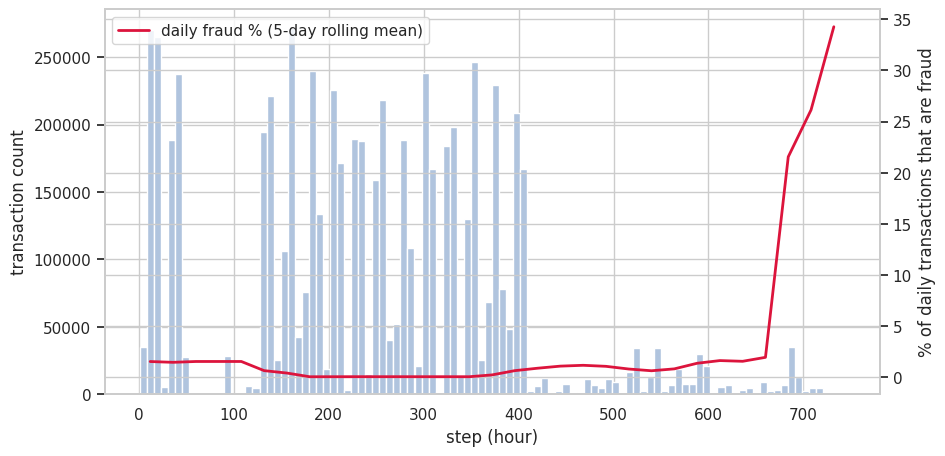

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df.step, bins=100, color='lightsteelblue')
ax.set_xlabel('step (hour)')
ax.set_ylabel('transaction count')

# daily fraud rate (% of that day's transactions that are fraud), smoothed
daily = df.assign(day=df.step // 24).groupby('day').isFraud.mean() * 100
smooth = daily.rolling(window=5, center=True, min_periods=1).mean()

ax2 = ax.twinx()
ax2.plot(smooth.index * 24 + 12, smooth.values, color='crimson', lw=2, label='daily fraud % (5-day rolling mean)')
ax2.set_ylabel('% of daily transactions that are fraud')
ax2.legend(loc='upper left')
plt.show()

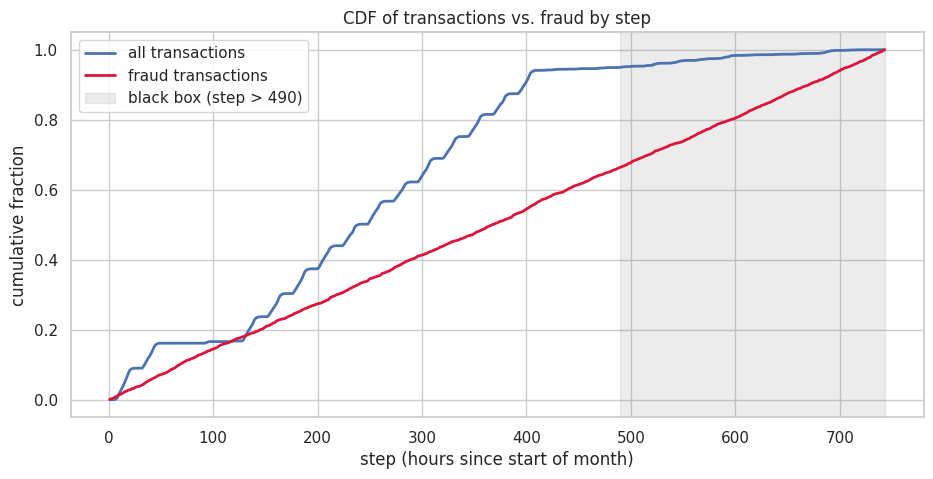

In [5]:
steps_all = np.arange(df.step.min(), df.step.max() + 1)
txn_cdf = df.step.value_counts().reindex(steps_all, fill_value=0).cumsum() / len(df)
fraud_cdf = (
    df.loc[df.isFraud == 1, "step"].value_counts().reindex(steps_all, fill_value=0).cumsum()
    / df.isFraud.sum()
)
cdf_cut = int(txn_cdf[txn_cdf >= 1 - BLACKBOX_FRAC].index[0])

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(txn_cdf.index, txn_cdf.values, lw=2, label="all transactions")
ax.plot(fraud_cdf.index, fraud_cdf.values, lw=2, color="crimson", label="fraud transactions")
ax.axvspan(cdf_cut, steps_all.max(), color="gray", alpha=0.15, label=f"black box (step > {cdf_cut})")
ax.set(xlabel="step (hours since start of month)", ylabel="cumulative fraction",
       title="CDF of transactions vs. fraud by step")
ax.legend(loc="upper left")
plt.show()

This next set of plots shows strong unevenness across hor of the day and day of the week.

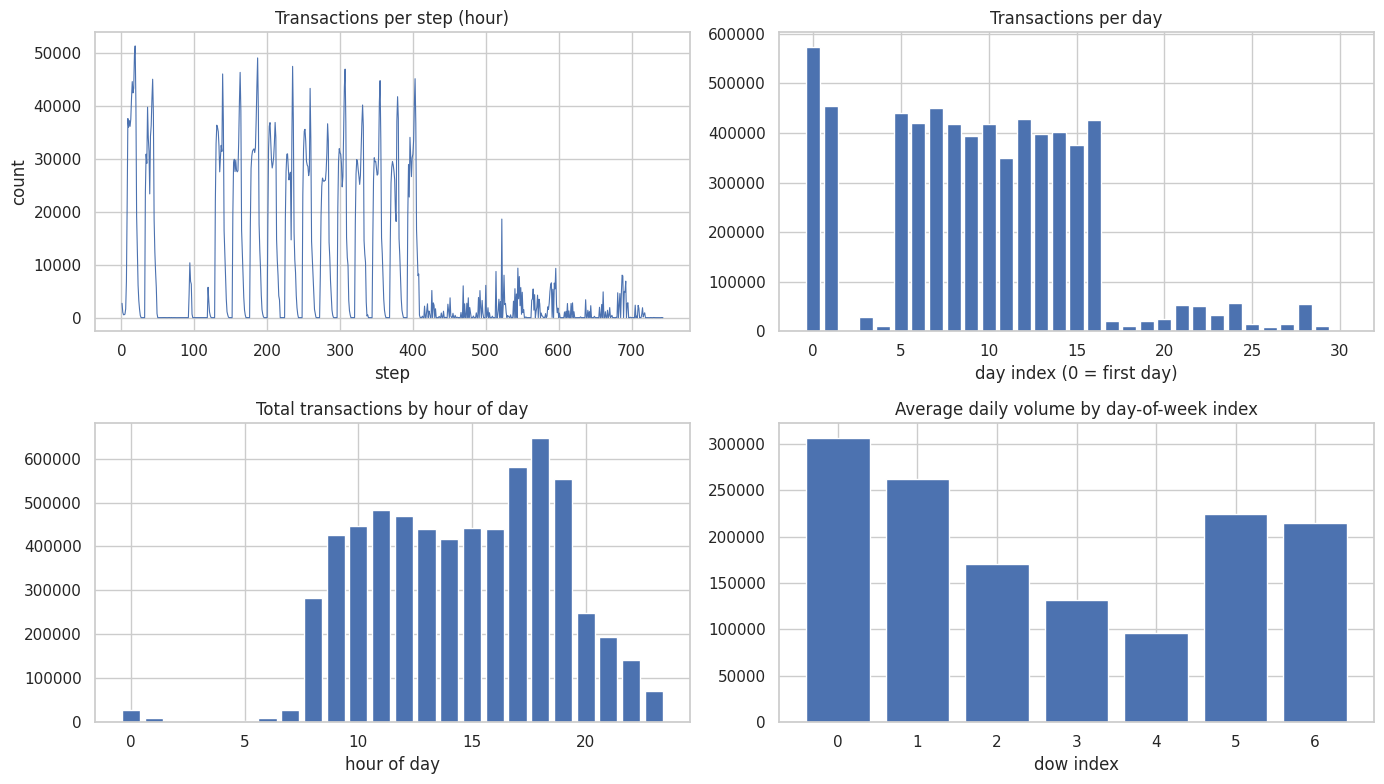

In [6]:
df["hour"] = (df.step - 1) % 24   # hour of day, 0-23
df["day"] = (df.step - 1) // 24   # day of month index, 0-30
df["dow"] = df["day"] % 7         # day-of-week index (anchor weekday unknown)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
per_step = df.step.value_counts().sort_index()
axes[0, 0].plot(per_step.index, per_step.values, lw=0.8)
axes[0, 0].set(title="Transactions per step (hour)", xlabel="step", ylabel="count")

per_day = df.groupby("day").size()
axes[0, 1].bar(per_day.index, per_day.values)
axes[0, 1].set(title="Transactions per day", xlabel="day index (0 = first day)")

by_hour = df.groupby("hour").size()
axes[1, 0].bar(by_hour.index, by_hour.values)
axes[1, 0].set(title="Total transactions by hour of day", xlabel="hour of day")

dow_avg = df.groupby(["dow", "day"]).size().groupby("dow").mean()
axes[1, 1].bar(dow_avg.index, dow_avg.values)
axes[1, 1].set(title="Average daily volume by day-of-week index", xlabel="dow index")
plt.tight_layout()
plt.show()

And here, we see that there is inconsistency in the numbers all agreeing with each other. Old balance, new balance, and amount transfered do not always line up.

In [7]:
def slog(x):
    """Signed log10(1 + |x|)."""
    return np.sign(x) * np.log10(1 + np.abs(x))


def add_money_features(d):
    # magnitudes
    d["log_amount"] = np.log10(1 + d.amount)
    d["log_old_orig"] = np.log10(1 + d.oldbalanceOrg)
    d["log_new_orig"] = np.log10(1 + d.newbalanceOrig)
    d["log_old_dest"] = np.log10(1 + d.oldbalanceDest)
    d["log_new_dest"] = np.log10(1 + d.newbalanceDest)
    # ratios (+1 keeps them finite when a balance is 0)
    d["amt_over_old_orig"] = (d.amount + 1) / (d.oldbalanceOrg + 1)
    d["amt_over_old_dest"] = (d.amount + 1) / (d.oldbalanceDest + 1)
    d["old_dest_over_old_orig"] = (d.oldbalanceDest + 1) / (d.oldbalanceOrg + 1)
    # flags
    d["orig_was_zero"] = (d.oldbalanceOrg == 0).astype("int8")
    d["orig_zeroed"] = ((d.oldbalanceOrg > 0) & (d.newbalanceOrig == 0)).astype("int8")
    d["dest_was_zero"] = (d.oldbalanceDest == 0).astype("int8")
    d["dest_new_zero"] = (d.newbalanceDest == 0).astype("int8")
    d["dest_untouched"] = ((d.amount > 0) & (d.newbalanceDest == d.oldbalanceDest)).astype("int8")
    d["dest_is_merchant"] = d.nameDest.str.startswith("M").astype("int8")
    # does the transaction take the entire origin balance? (independent of what newbalanceOrig reports)
    d["full_drain"] = ((d.oldbalanceOrg > 0) & (d.amount >= d.oldbalanceOrg - 0.01)).astype("int8")
    # unexplained balance changes
    sign = np.where(d.type == "CASH_IN", 1.0, -1.0)
    d["orig_gap"] = d.newbalanceOrig - (d.oldbalanceOrg + sign * d.amount)
    d["dest_gap"] = d.newbalanceDest - (d.oldbalanceDest + d.amount)
    d["orig_gap_slog"] = slog(d.orig_gap)
    d["dest_gap_slog"] = slog(d.dest_gap)
    return d


df = add_money_features(df)

tol = 0.01
consistent = pd.DataFrame({"orig_consistent": df.orig_gap.abs() < tol,
                           "dest_consistent": df.dest_gap.abs() < tol})
print("Share of rows where the balance change matches the amount exactly, by type:")
display(consistent.groupby(df.type).mean())
display(pd.crosstab(df.type, df.dest_is_merchant, normalize="index").rename(columns={0: "dest is C*", 1: "dest is M*"}))

Share of rows where the balance change matches the amount exactly, by type:


,orig_consistent,dest_consistent
type,,
CASH_IN,0.927752,0.000000
CASH_OUT,0.110047,0.773217
DEBIT,0.699218,0.767547
PAYMENT,0.458101,0.000000
TRANSFER,0.045274,0.773299


dest_is_merchant,dest is C*,dest is M*
type,,
CASH_IN,1.0,0.0
CASH_OUT,1.0,0.0
DEBIT,1.0,0.0
PAYMENT,0.0,1.0
TRANSFER,1.0,0.0


Origin accounts are close to unique, destination accounts less so.

Implies more temporal feature engineering opportunity for the latter.

In [8]:
orig_counts = df.nameOrig.value_counts()
dest_counts = df.nameDest.value_counts()
print(f"unique nameOrig: {len(orig_counts):,}   unique nameDest: {len(dest_counts):,}   rows: {len(df):,}")
display(pd.DataFrame({
    "nameOrig": orig_counts.value_counts().sort_index().head(8),
    "nameDest": dest_counts.value_counts().sort_index().head(8),
}).rename_axis("# transactions on account").fillna(0).astype(int))
print("max transactions on one nameOrig:", orig_counts.max(), "  on one nameDest:", dest_counts.max())

dest_set = set(dest_counts.index)
print(f"share of rows whose nameOrig also appears as a nameDest: {df.nameOrig.isin(dest_set).mean():.4%}")
del orig_counts, dest_counts, dest_set
gc.collect()

unique nameOrig: 6,353,307   unique nameDest: 2,722,362   rows: 6,362,620


,nameOrig,nameDest
# transactions on account,,
1,6344009,2262704
2,9283,77054
3,15,57289
4,0,45115
5,0,36821
6,0,30416
7,0,25807
8,0,21900


max transactions on one nameOrig: 3   on one nameDest: 113
share of rows whose nameOrig also appears as a nameDest: 0.0278%


18

### 2) Target specific EDA for feature engineering

Now lets do some EDA in relation to the target. We will need to split out the black box test set so we don't bias ourselves in our selections visually.

We are choosing the last 5% of the dataset for our black box holdout. This is an unusually small percentage, but because of the regime change this is something like the third of the dataset temporally. The fact that our dataset is so large is helpful here: our 5% holdout is still 300k+ rows and approximately a third of all the fraud cases (see plots above).

In [9]:
df = df.sort_values("step", kind="stable").reset_index(drop=True)
cum_share = df.step.value_counts().sort_index().cumsum() / len(df)
split_step = int(cum_share[cum_share >= 1 - BLACKBOX_FRAC].index[0])

train = df[df.step <= split_step].copy()
blackbox = df[df.step > split_step]

print(f"split after step {split_step}")
print(f"train:     {len(train):,} rows ({len(train) / len(df):.2%}), steps {train.step.min()}-{train.step.max()}")
print(f"black box: {len(blackbox):,} rows ({len(blackbox) / len(df):.2%}), steps {blackbox.step.min()}-{blackbox.step.max()}")

blackbox.to_parquet(BLACKBOX_PATH, index=False)
print("black box saved to", os.path.abspath(BLACKBOX_PATH))

del df, blackbox, cum_share
gc.collect()

split after step 490
train:     6,044,570 rows (95.00%), steps 1-490
black box: 318,050 rows (5.00%), steps 491-743
black box saved to /home/ssm-user/eda/fraud_blackbox_holdout.parquet


29

Observe how 100% of frauds are in two of the five types. 

This makes sense in some ways (how can a CASH_IN be a fraud?). I propose during live scoring we only look at CASH_OUT and TRANSFER, and if there are any true frauds out of those types after the fact we issue something similar to an on-call alert to data scientists, signaling that a core assumption the model was built around is now broken.

This is a form of Undersampling of Majority Class, which the kaggle download explainer encouraged.

We will need to keep these types in for feature engineering though!

,n,frauds,rate
type,,,
CASH_IN,1326773,0,0.000000
CASH_OUT,2135393,2739,0.001283
DEBIT,38920,0,0.000000
PAYMENT,2040604,0,0.000000
TRANSFER,502880,2720,0.005409


types with any fraud: ['CASH_OUT', 'TRANSFER']
  -> 43.6% of rows, 100.0% of frauds, fraud rate within them: 0.2069%


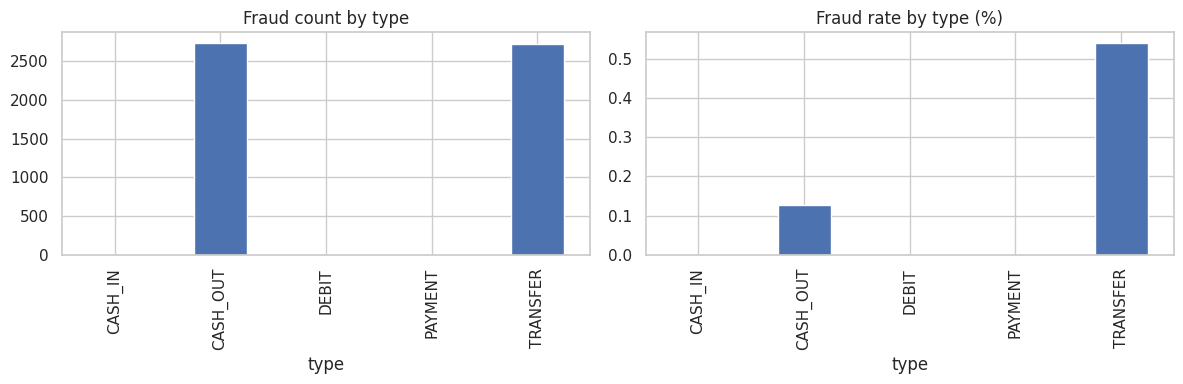

In [10]:
by_type = train.groupby("type").isFraud.agg(n="size", frauds="sum", rate="mean")
display(by_type)

fraud_types = by_type.index[by_type.frauds > 0].tolist()
risky = train.type.isin(fraud_types)
print(f"types with any fraud: {fraud_types}")
print(f"  -> {risky.mean():.1%} of rows, {train.loc[risky, 'isFraud'].sum() / train.isFraud.sum():.1%} of frauds, "
      f"fraud rate within them: {train.loc[risky, 'isFraud'].mean():.4%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_type.frauds.plot.bar(ax=axes[0], title="Fraud count by type")
(by_type.rate * 100).plot.bar(ax=axes[1], title="Fraud rate by type (%)")
plt.tight_layout()
plt.show()

Observe how fraud remains relatively steady while the overall counts fluctuate temporally. This is very curious, as I would expect both to fluctuate but on different cycles. Maybe these are just the kind of funky results you get from synthetic data though. Thankfully this is still good signal.

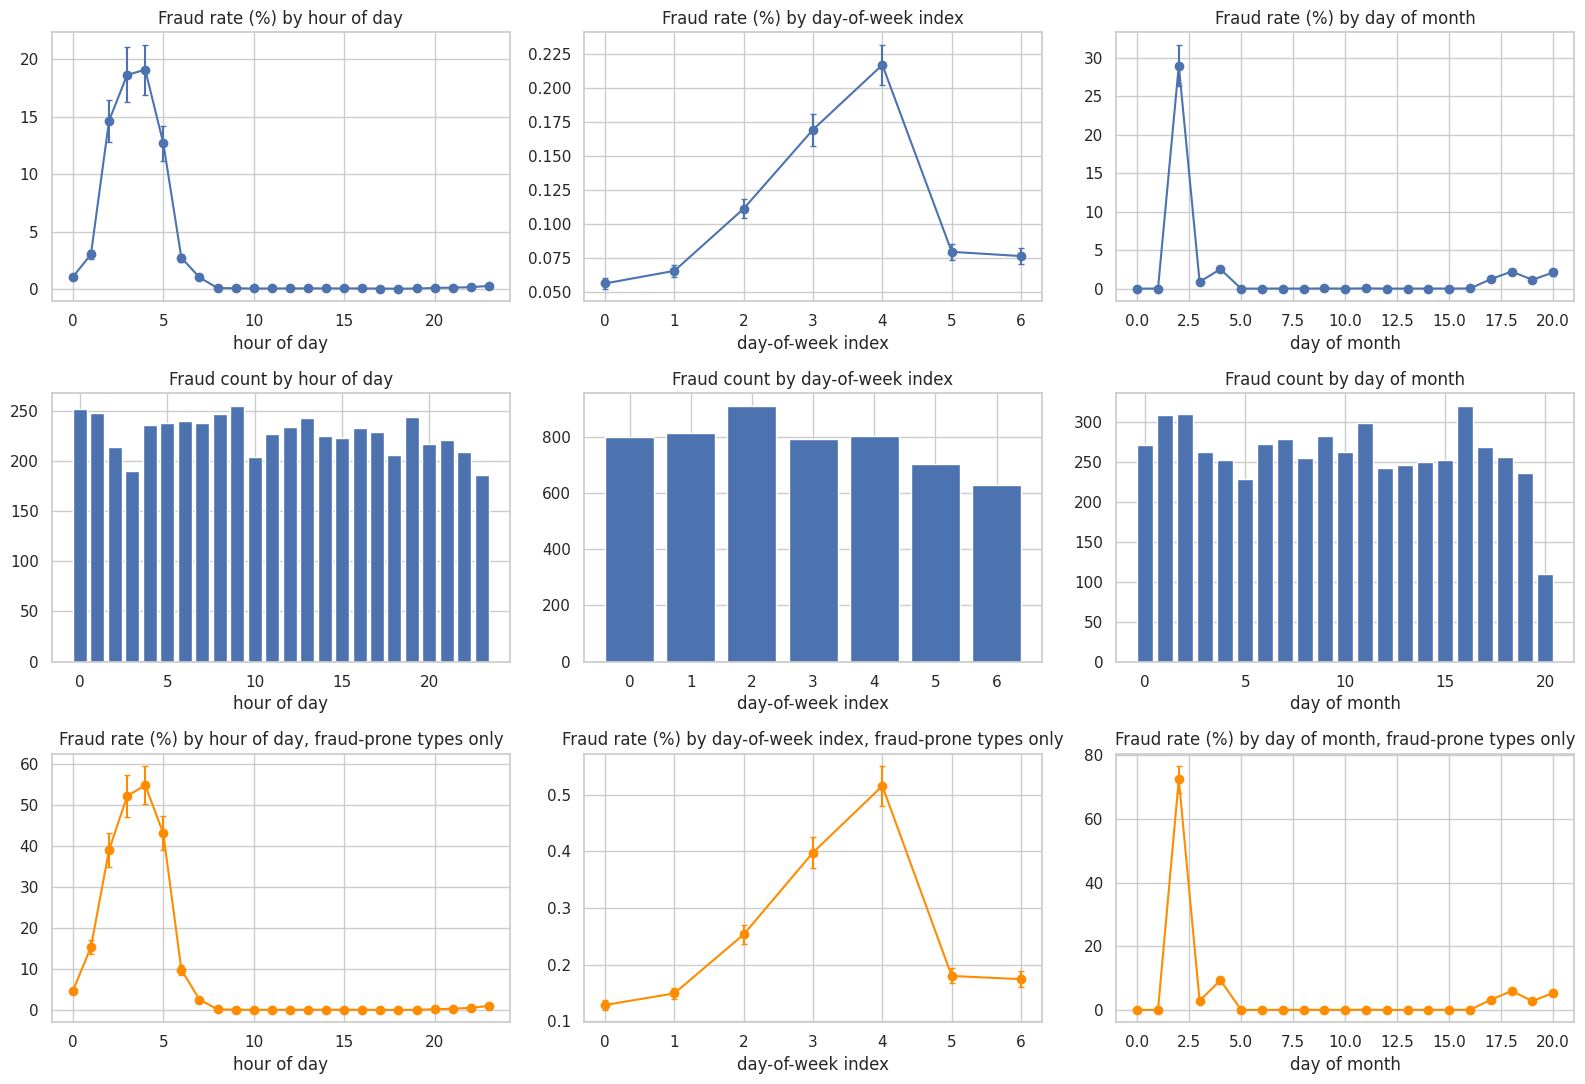

In [11]:
def rate_table(d, col):
    g = d.groupby(col).isFraud.agg(n="size", frauds="sum", rate="mean")
    g["se"] = np.sqrt(g.rate * (1 - g.rate) / g.n)
    return g


fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for j, (col, label) in enumerate([("hour", "hour of day"), ("dow", "day-of-week index"), ("day", "day of month")]):
    g_all, g_risky = rate_table(train, col), rate_table(train[risky], col)
    axes[0, j].errorbar(g_all.index, g_all.rate * 100, yerr=1.96 * g_all.se * 100, fmt="o-", capsize=2)
    axes[0, j].set(title=f"Fraud rate (%) by {label}", xlabel=label)
    axes[1, j].bar(g_all.index, g_all.frauds)
    axes[1, j].set(title=f"Fraud count by {label}", xlabel=label)
    axes[2, j].errorbar(g_risky.index, g_risky.rate * 100, yerr=1.96 * g_risky.se * 100, fmt="o-", capsize=2, color="darkorange")
    axes[2, j].set(title=f"Fraud rate (%) by {label}, fraud-prone types only", xlabel=label)
plt.tight_layout()
plt.show()

A lot of signal in the old amount of origin (foreshadowing):

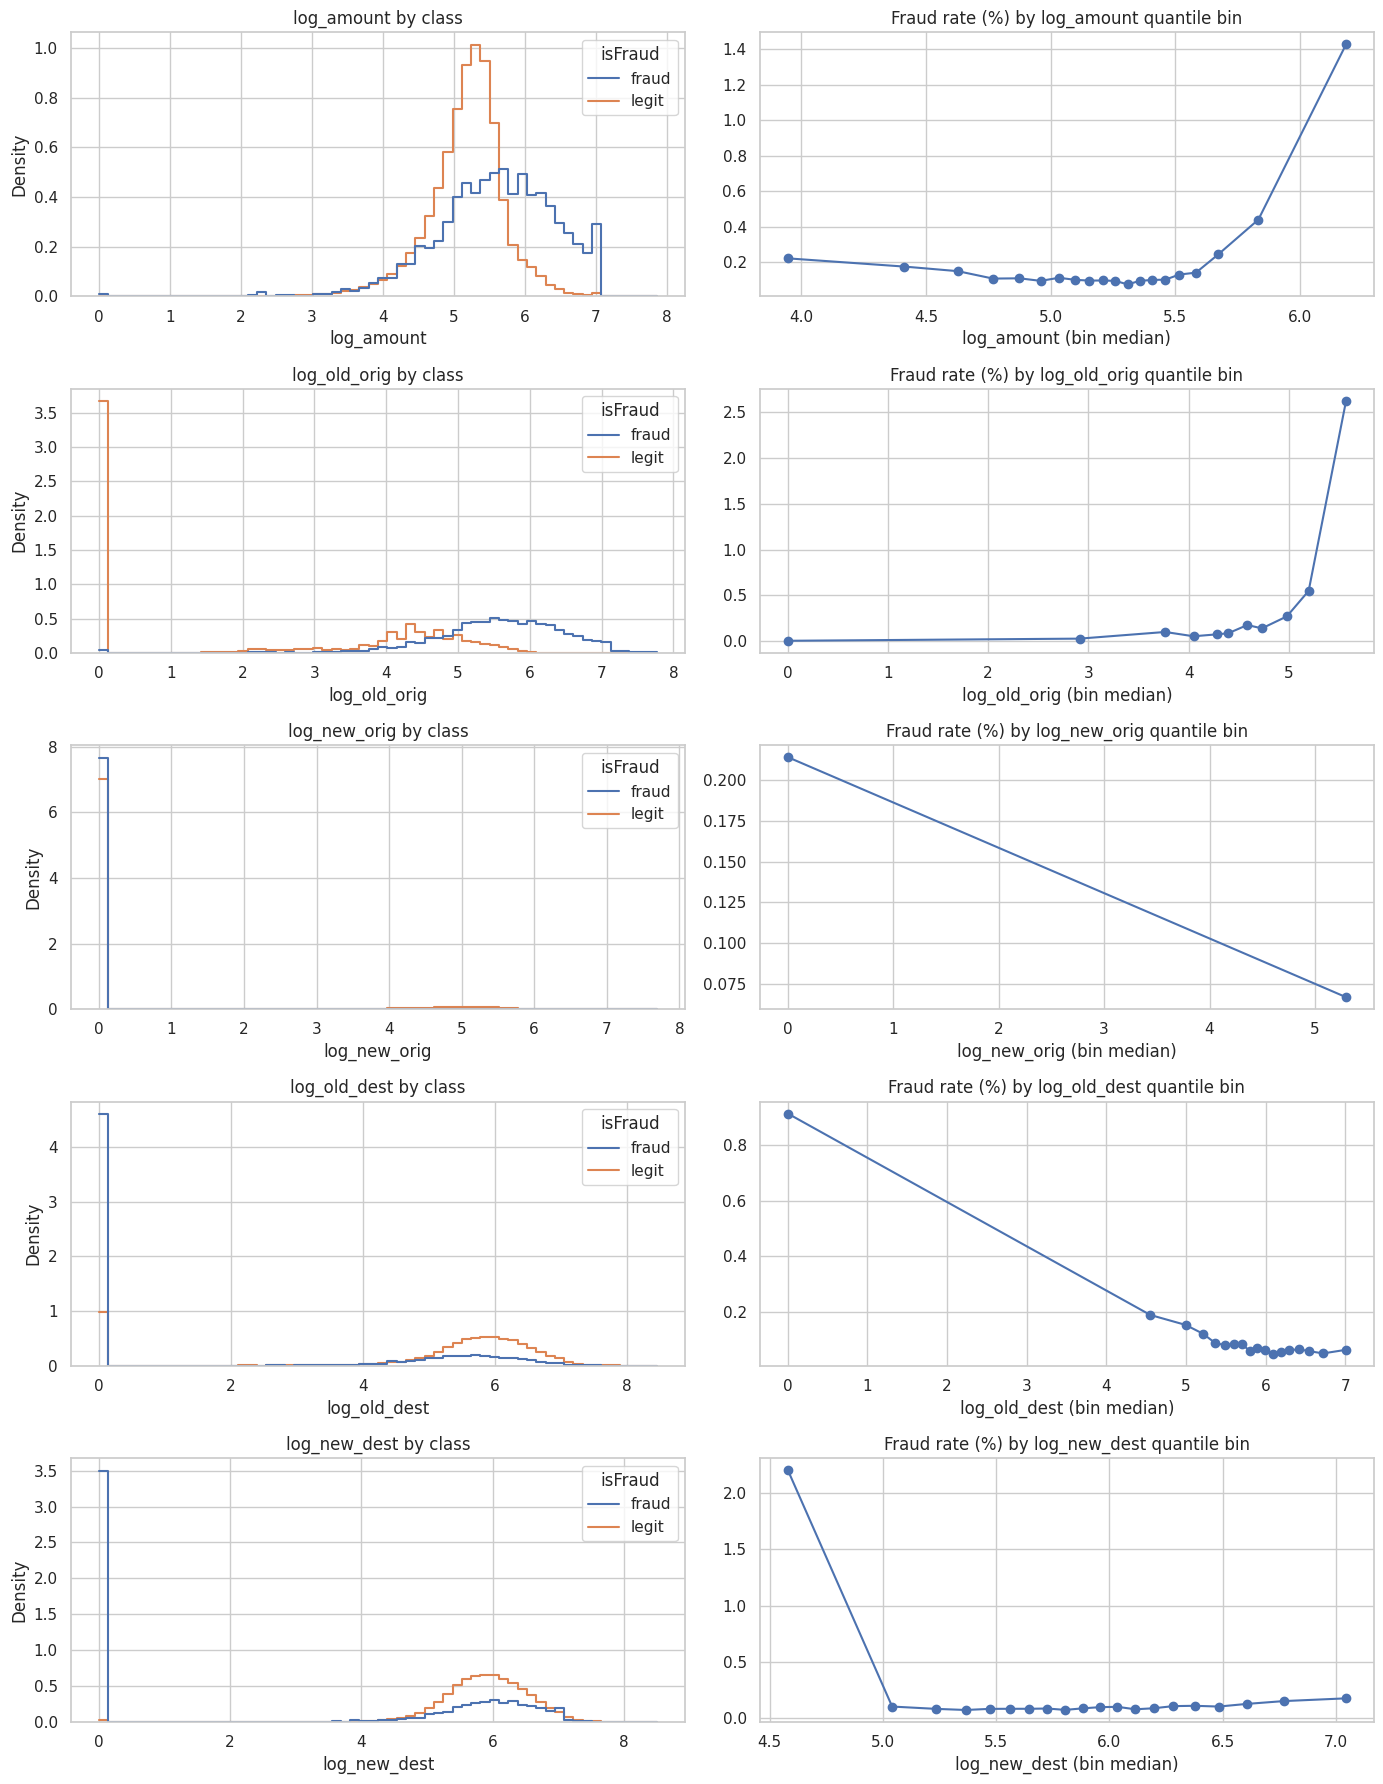

In [12]:
risky_df = train[risky]
fraud_rows = risky_df[risky_df.isFraud == 1]
legit_rows = risky_df[risky_df.isFraud == 0]
viz = pd.concat([fraud_rows, legit_rows.sample(min(200_000, len(legit_rows)), random_state=0)])


def rate_by_bins(d, col, q=20):
    b = pd.qcut(d[col], q=q, duplicates="drop")
    return d.groupby(b, observed=True).agg(n=("isFraud", "size"), frauds=("isFraud", "sum"),
                                           rate=("isFraud", "mean"), x=(col, "median"))


def dist_and_rate(cols, xlog=False, q=20):
    fig, axes = plt.subplots(len(cols), 2, figsize=(14, 3.6 * len(cols)))
    axes = np.atleast_2d(axes)
    for i, c in enumerate(cols):
        x = np.log10(viz[c]) if xlog else viz[c]
        sns.histplot(x=x, hue=viz.isFraud.map({0: "legit", 1: "fraud"}), bins=60, stat="density",
                     common_norm=False, element="step", fill=False, ax=axes[i, 0])
        axes[i, 0].set(title=f"{c}{' (log10)' if xlog else ''} by class", xlabel=c)
        g = rate_by_bins(risky_df, c, q)
        axes[i, 1].plot(g.x, g.rate * 100, marker="o")
        if xlog:
            axes[i, 1].set_xscale("log")
        axes[i, 1].set(title=f"Fraud rate (%) by {c} quantile bin", xlabel=f"{c} (bin median)")
    plt.tight_layout()
    plt.show()


dist_and_rate(["log_amount", "log_old_orig", "log_new_orig", "log_old_dest", "log_new_dest"])

Ditto for here

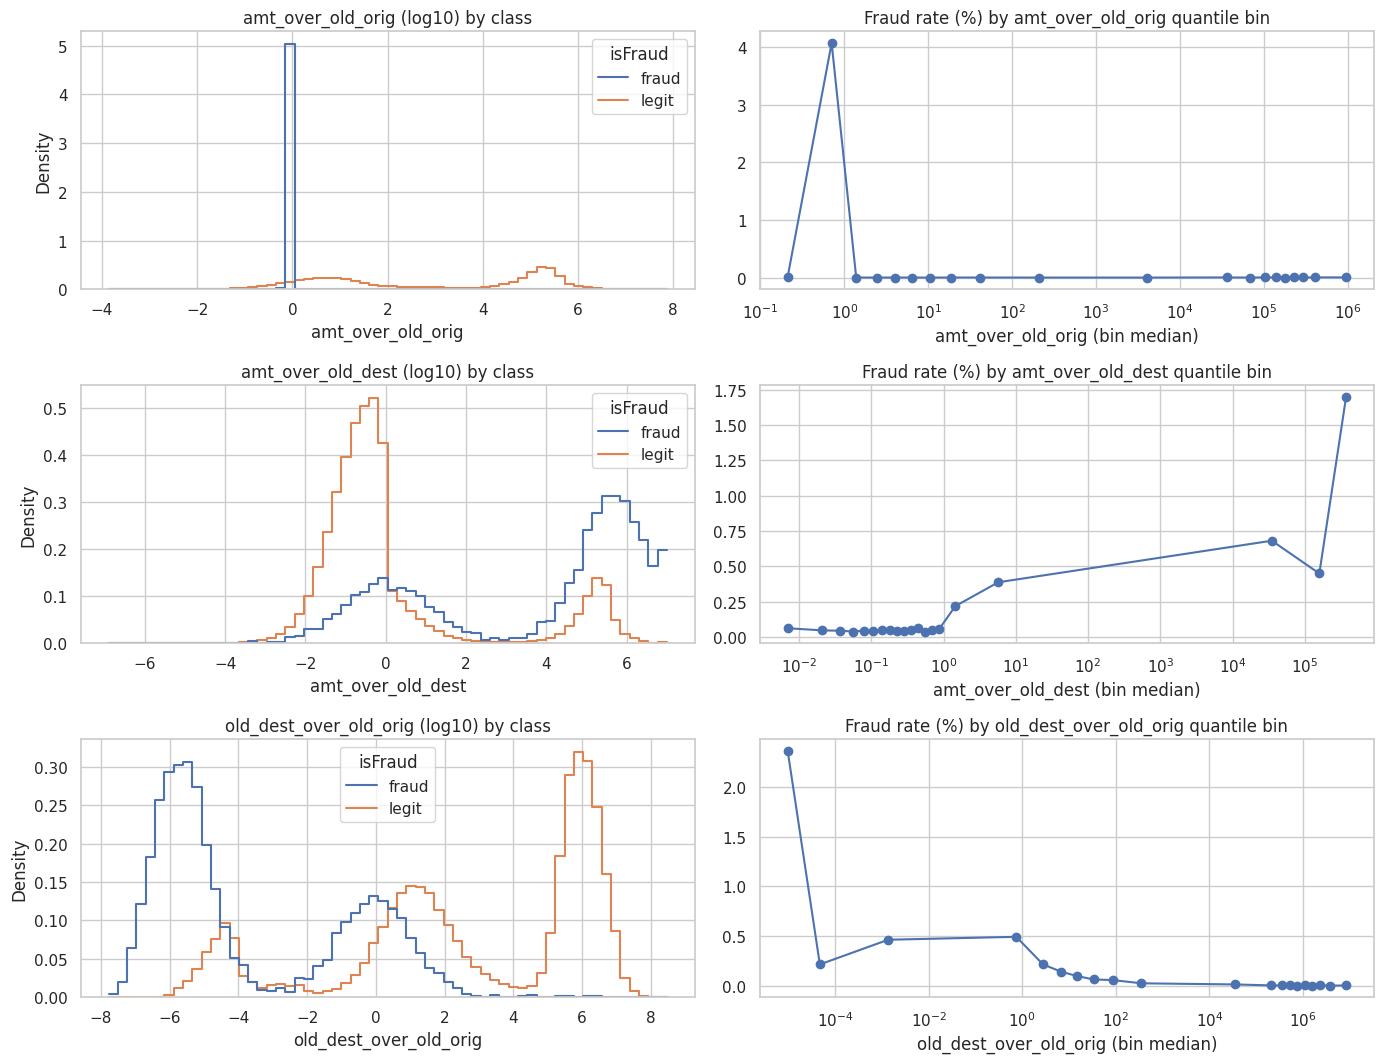

In [13]:
dist_and_rate(["amt_over_old_orig", "amt_over_old_dest", "old_dest_over_old_orig"], xlog=True)

Indicator features of the amount changes are also very predictive:

n  frauds      rate
flag             value                           
orig_was_zero    0      1382105    5428  0.003927
                 1      1256168      31  0.000025
orig_zeroed      0      1515452     119  0.000079
                 1      1122821    5340  0.004756
full_drain       0      1515446     115  0.000076
                 1      1122827    5344  0.004759
dest_was_zero    0      2272025    1916  0.000843
                 1       366248    3543  0.009674
dest_new_zero    0      2623069    2749  0.001048
                 1        15204    2710  0.178243
dest_untouched   0      2633874    2766  0.001050
                 1         4399    2693  0.612185
dest_is_merchant 0      2638273    5459  0.002069

Both destination balances zero but amount > 0, and origin zeroed:


,n,frauds,rate
combo,,,
False,2634433,2852,0.001083
True,3840,2607,0.678906


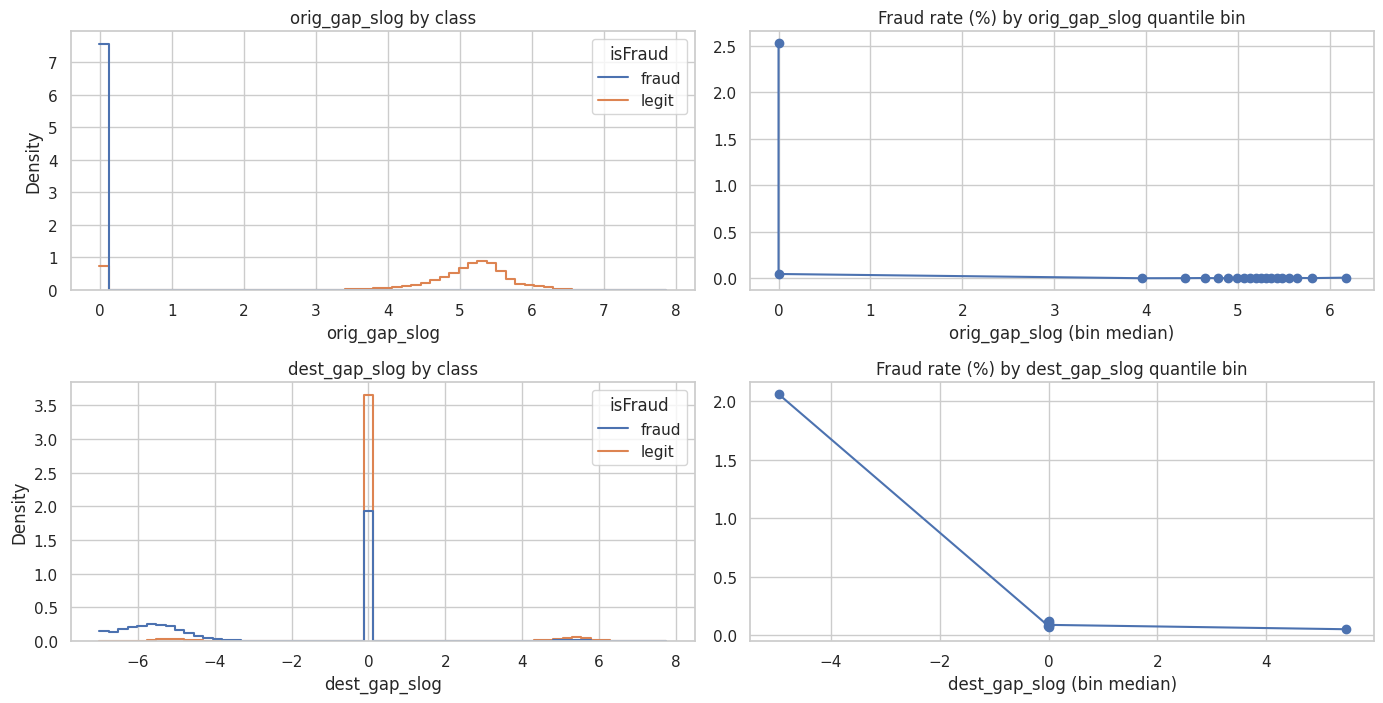

In [14]:
flag_cols = ["orig_was_zero", "orig_zeroed", "full_drain", "dest_was_zero", "dest_new_zero", "dest_untouched",
             "dest_is_merchant"]
tabs = {c: risky_df.groupby(c).isFraud.agg(n="size", frauds="sum", rate="mean") for c in flag_cols}
display(pd.concat(tabs, names=["flag", "value"]))

print("Both destination balances zero but amount > 0, and origin zeroed:")
combo = (risky_df.dest_was_zero == 1) & (risky_df.dest_new_zero == 1) & (risky_df.orig_zeroed == 1)
display(risky_df.groupby(combo).isFraud.agg(n="size", frauds="sum", rate="mean").rename_axis("combo"))

dist_and_rate(["orig_gap_slog", "dest_gap_slog"])

Overlapping the indicator with the types seems solid as well:

Fraud rate by type and full_drain (all training rows):


n  frauds      rate
type     full_drain                           
CASH_IN  0            887476       0  0.000000
         1            439297       0  0.000000
CASH_OUT 0           1228049      28  0.000023
         1            907344    2711  0.002988
DEBIT    0             33664       0  0.000000
         1              5256       0  0.000000
PAYMENT  0           1731389       0  0.000000
         1            309215       0  0.000000
TRANSFER 0            287397      87  0.000303
         1            215483    2633  0.012219

CASH_OUT only, full_drain x orig_zeroed (newbalanceOrig == 0):


n  frauds      rate
full_drain orig_zeroed                           
0          0            1228049      28  0.000023
1          0                  2       0  0.000000
           1             907342    2711  0.002988

share of CASH_OUT frauds that take the full balance: 98.98%
share of all CASH_OUT that take the full balance:    42.49%


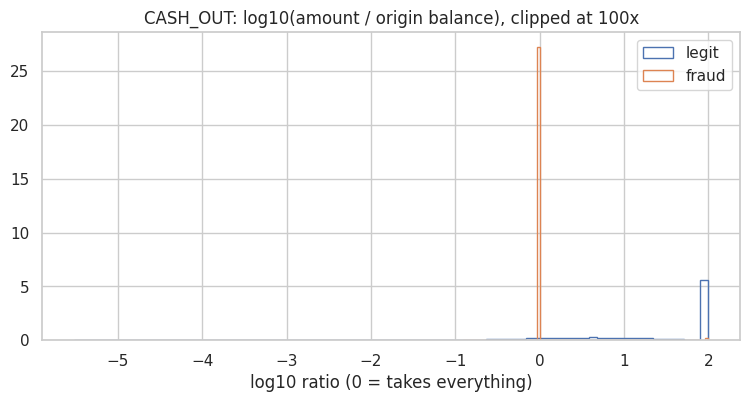

In [15]:
print("Fraud rate by type and full_drain (all training rows):")
display(train.groupby(["type", "full_drain"]).isFraud.agg(n="size", frauds="sum", rate="mean"))

co = train[train.type == "CASH_OUT"]
print("CASH_OUT only, full_drain x orig_zeroed (newbalanceOrig == 0):")
display(co.groupby(["full_drain", "orig_zeroed"]).isFraud.agg(n="size", frauds="sum", rate="mean"))
print(f"share of CASH_OUT frauds that take the full balance: {co.loc[co.isFraud == 1, 'full_drain'].mean():.2%}")
print(f"share of all CASH_OUT that take the full balance:    {co.full_drain.mean():.2%}")

fig, ax = plt.subplots(figsize=(9, 4))
for label, sub in co.groupby("isFraud"):
    ax.hist(np.log10(sub.amt_over_old_orig.clip(upper=100)), bins=80, density=True, histtype="step",
            label="fraud" if label else "legit")
ax.set(title="CASH_OUT: log10(amount / origin balance), clipped at 100x", xlabel="log10 ratio (0 = takes everything)")
ax.legend()
plt.show()
del co

Histories of fraud in destination seem a bit predictive (note the lag assumption)

In [16]:
n_tr = len(train)
tr_codes = pd.factorize(pd.concat([train.nameOrig, train.nameDest], ignore_index=True))[0].astype(np.int64)
q_codes = {"orig": tr_codes[:n_tr], "dest": tr_codes[n_tr:]}
tr_steps = train.step.to_numpy(np.int64)
is_fraud = (train.isFraud == 1).to_numpy()
BIG = 10_000  # larger than any step, so (account, step) packs into one sortable int64

def prior_counts(q_acct, q_step, ev_acct, ev_step, window=None, lag=LAG):
    """For each query row (account, step): number of events on that account that are visible,
    i.e. with event step <= query step - lag. If `window` is given, only the last `window`
    visible steps count (steps q_step - lag - window + 1 ... q_step - lag); otherwise all history."""
    ev = np.sort(ev_acct * BIG + ev_step)
    hi = np.searchsorted(ev, q_acct * BIG + q_step - lag + 1, side="left")
    lo_key = q_acct * BIG if window is None else q_acct * BIG + q_step - lag - window + 1
    lo = np.searchsorted(ev, lo_key, side="left")
    return (hi - lo).astype(np.int32)

windows = {"ever": None, "24h": 24, "6h": 6}

for role, qc in q_codes.items():
    # all earlier transactions on this account (lagged by LAG); the denominator for fraud_share_ever below
    train[f"{role}_n_all_ever"] = prior_counts(qc, tr_steps, qc, tr_steps, None, lag=LAG)
    for ev_role, ec in q_codes.items():          # role the account played in the earlier fraud
        for w_name, w in windows.items():
            train[f"{role}_fraud_as_{ev_role}_{w_name}"] = prior_counts(
                qc, tr_steps, ec[is_fraud], tr_steps[is_fraud], w, lag=LABEL_LAG)
    for w_name in windows:
        train[f"{role}_fraud_any_{w_name}"] = (train[f"{role}_fraud_as_orig_{w_name}"]
                                                + train[f"{role}_fraud_as_dest_{w_name}"])
    train[f"{role}_had_fraud_ever"] = (train[f"{role}_fraud_any_ever"] > 0).astype("int8")
    train[f"{role}_had_fraud_24h"] = (train[f"{role}_fraud_any_24h"] > 0).astype("int8")
    train[f"{role}_had_fraud_6h"] = (train[f"{role}_fraud_any_6h"] > 0).astype("int8")
    train[f"{role}_fraud_share_ever"] = train[f"{role}_fraud_as_dest_ever"] / train[f"{role}_n_all_ever"].clip(lower=1)

# ---- destination / origin history counts by type and window (mirrors temporal_features) ----
type_map = {"all": None, "transfer": "TRANSFER", "cashout": "CASH_OUT", "cashin": "CASH_IN", "debit": "DEBIT"}
typ = train.type.to_numpy()
dest_codes, orig_codes = q_codes["dest"], q_codes["orig"]

for ev_name, t in type_map.items():
    m = np.ones(len(train), dtype=bool) if t is None else (typ == t)
    for w_name, w in windows.items():
        # events = earlier transactions of this type received by the account, lagged by LAG
        train[f"dest_n_{ev_name}_{w_name}"] = prior_counts(dest_codes, tr_steps, dest_codes[m], tr_steps[m], w, lag=LAG)

# origin activity (any type, as sender) in the same windows
for w_name, w in windows.items():
    train[f"orig_n_all_{w_name}"] = prior_counts(orig_codes, tr_steps, orig_codes, tr_steps, w, lag=LAG)

train["dest_is_new"] = (train["dest_n_all_ever"] == 0).astype("int8")

# share of the destination's visible history that was each type
for t in ["cashin", "cashout", "transfer", "debit"]:
    for w_name in ("ever", "24h"):
        train[f"dest_mix_{t}_{w_name}"] = train[f"dest_n_{t}_{w_name}"] / train[f"dest_n_all_{w_name}"].clip(lower=1)
        
del tr_codes, q_codes
gc.collect()

# the earlier risky_df/fraud_rows/legit_rows slices predate these columns, so rebuild them
risky_df = train[risky]
fraud_rows = risky_df[risky_df.isFraud == 1]
legit_rows = risky_df[risky_df.isFraud == 0]

fraud_flags = [f"{r}_had_fraud_{w}" for r in ("dest", "orig") for w in ("ever", "24h", "6h")]
print("Share of rows with the flag set (all train rows | fraud-prone types):")
display(pd.DataFrame({"all_rows": train[fraud_flags].mean(), "risky_rows": risky_df[fraud_flags].mean()}))
display(pd.concat({c: risky_df.groupby(c).isFraud.agg(n="size", frauds="sum", rate="mean") for c in fraud_flags},
                  names=["flag", "value"]))
print("Share of all training frauds that had each flag set at the time:")
display(train.loc[train.isFraud == 1, fraud_flags].mean().to_frame("share_of_frauds").T)

Share of rows with the flag set (all train rows | fraud-prone types):


,all_rows,risky_rows
dest_had_fraud_ever,0.004594,0.007052
dest_had_fraud_24h,0.000546,0.000839
dest_had_fraud_6h,0.000159,0.000251
orig_had_fraud_ever,0.000002,0.000002
orig_had_fraud_24h,0.000000,0.000000
orig_had_fraud_6h,0.000000,0.000000


n  frauds      rate
flag                value                           
dest_had_fraud_ever 0      2619667    5440  0.002077
                    1        18606      19  0.001021
dest_had_fraud_24h  0      2636060    5456  0.002070
                    1         2213       3  0.001356
dest_had_fraud_6h   0      2637611    5458  0.002069
                    1          662       1  0.001511
orig_had_fraud_ever 0      2638267    5459  0.002069
                    1            6       0  0.000000
orig_had_fraud_24h  0      2638273    5459  0.002069
orig_had_fraud_6h   0      2638273    5459  0.002069

Share of all training frauds that had each flag set at the time:


,dest_had_fraud_ever,dest_had_fraud_24h,dest_had_fraud_6h,orig_had_fraud_ever,orig_had_fraud_24h,orig_had_fraud_6h
share_of_frauds,0.00348,0.00055,0.000183,0.0,0.0,0.0


Looking at overall transaction history trends across types for destination accounts also has a little bit of signal.

ever: 84.8% of fraud-prone rows have destination history; 2001 of 5459 frauds
24h: 58.3% of fraud-prone rows have destination history; 998 of 5459 frauds


n  frauds      rate
history_type type     received_before                           
cashin       CASH_OUT False             729994    1176  0.001611
                      True             1405399    1563  0.001112
             TRANSFER False             145408    2718  0.018692
                      True              357472       2  0.000006
cashout      CASH_OUT False             489497    1027  0.002098
                      True             1645896    1712  0.001040
             TRANSFER False              97445    2716  0.027872
                      True              405435       4  0.000010
transfer     CASH_OUT False            1216545    1910  0.001570
                      True              918848     829  0.000902
             TRANSFER False             228716    2718  0.011884
                      True              274164       2  0.000007
debit        CASH_OUT False            1998012    2599  0.001301
                      True              137381     140  0.001019
             TRANSFER False             463110    2720  0.005873
                      True               39770       0  0.000000

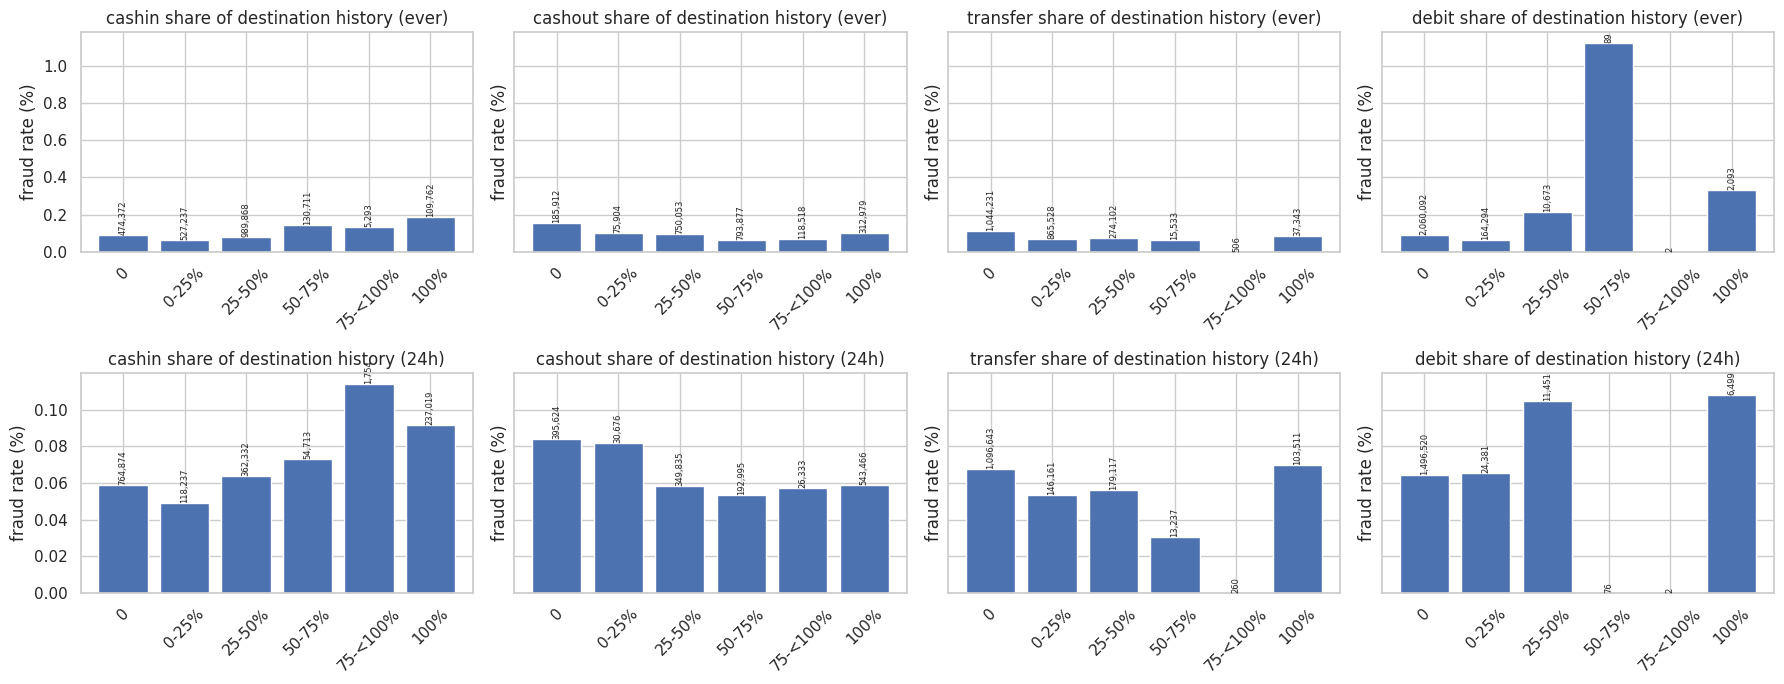

In [17]:
mix_types = ["cashin", "cashout", "transfer", "debit"]
type_mix_feats = [f"dest_mix_{t}_{w}" for t in mix_types for w in ("ever", "24h")]

for w in ("ever", "24h"):
    has = risky_df[f"dest_n_all_{w}"] > 0
    print(f"{w}: {has.mean():.1%} of fraud-prone rows have destination history; "
          f"{int(risky_df.loc[has, 'isFraud'].sum())} of {int(risky_df.isFraud.sum())} frauds")

tabs = {}
for t in mix_types:
    flag = (risky_df[f"dest_n_{t}_ever"] > 0).rename("received_before")
    tabs[t] = (risky_df.groupby([risky_df.type, flag]).isFraud
               .agg(n="size", frauds="sum", rate="mean"))
display(pd.concat(tabs, names=["history_type"]))

mix_edges = [-0.001, 0, 0.25, 0.5, 0.75, 0.999, 1.0]
mix_labels = ["0", "0-25%", "25-50%", "50-75%", "75-<100%", "100%"]
fig, axes = plt.subplots(2, len(mix_types), figsize=(18, 7), sharey="row")
for i, w in enumerate(("ever", "24h")):
    base = risky_df[risky_df[f"dest_n_all_{w}"] > 0]
    for j, t in enumerate(mix_types):
        ax = axes[i, j]
        b = pd.cut(base[f"dest_mix_{t}_{w}"], bins=mix_edges, labels=mix_labels)
        g = base.groupby(b, observed=True).isFraud.agg(n="size", rate="mean")
        ax.bar(g.index.astype(str), g.rate * 100)
        for k, (n, r) in enumerate(zip(g.n, g.rate)):
            ax.text(k, r * 100, f"{n:,}", ha="center", va="bottom", fontsize=6, rotation=90)
        ax.set(title=f"{t} share of destination history ({w})", ylabel="fraud rate (%)")
        ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 3) Feature Engineering
Good candidates for features include:
- hour of day
- day of week relabel, shifted forward by 2, so what is 4 is now 6 and what is 6 is now 1 (helps for forest splitting).
- ALL the train set's fraud are in CASH_OUT and TRANSFER type. Lets not only use those, after feature engineering lets drop them entirely. This will balance the dataset more. In production we will have an automatic rule that only those transactions can be labeled fraud, and if we see fraud elsewhere we will officially alert. For now we can one-hot_encode them as binary types
- raw values of new/old origin/destination are predictive as well.
- so are ratios of origin/destination vs amount transfered as well.
- no plot but my gut says ratio of new vs old is good too
- Although simply a linear transform of the above, the zero flags are highly predictive as well.
- Whether an account was fully drained or not is also very predictive.
- prior transfer type history. An example: only 2 of about 357k TRANSFERs to a destination with prior CASH_IN history were fraud. TRANSFERs to destinations with no such history were fraud about 1.9% of the time. Why put money into an account that could be frozen if you are comitting fraud? 
- raw amount of transfer (current feature in prod)
- Raw Balance gaps
- new vs old balance ratio
- 

### Kinda obvious stuff to leave out:
 Features to leave out:
  - step and day, which are non-stationary, with a regime shift and a holdout beyond the training range.
  - isFlaggedFraud, which is the output of the current rule.
  - Account name IDs, random aside from the first character.
  - dest_is_merchant, which is constant once only TRANSFER and CASH_OUT remain.

### Uncertain:
destination fraud history also seems slightly predictive (will have to watch for leakage).
- rows with a prior-fraud destination were fraud less often, about 0.12% vs 0.21% overall.
- Only about 0.5% of frauds had that flag set, so it's weak either way.
- I want to leave this in as it could become predictive in the hold out set. There is a regime change there as we can mabe capture.


### To start: create the time-agnostic feature engineering/

In [18]:
# ---- Time-agnostic ("static") features -------------------------------------------------------
# Everything here is computed from a single row (the transaction being scored), so it is available
# at scoring time and cannot leak other rows. Safe to run on the full dataset before any split.
# Rows are NOT dropped here: the temporal features still need history from every type, so the
# CASH_OUT / TRANSFER filter is applied after all feature engineering.

FRAUD_TYPES = ["CASH_OUT", "TRANSFER"]   # production rule: only these can be labeled fraud
DOW_SHIFT = 2                            # day-of-week relabel: (dow + 2) % 7, so 4 -> 6 and 6 -> 1


def static_features(d):
    """Return a DataFrame of row-wise features, indexed like `d`. Does not modify `d`."""
    f = pd.DataFrame(index=d.index)
    old_o, new_o = d.oldbalanceOrg, d.newbalanceOrig
    old_d, new_d = d.oldbalanceDest, d.newbalanceDest
    amt = d.amount

    # time of the transaction itself (step = hours since the start of the month, from 1)
    f["hour"] = ((d.step - 1) % 24).astype("int8")
    f["dow_shift"] = ((((d.step - 1) // 24) % 7 + DOW_SHIFT) % 7).astype("int8")

    # transaction type, one-hot over the two fraud-prone types (other types are all zeros here)
    f["is_transfer"] = (d.type == "TRANSFER").astype("int8")
    f["is_cash_out"] = (d.type == "CASH_OUT").astype("int8")

    # raw amount and balances
    f["amount"] = amt
    f["oldbalanceOrg"], f["newbalanceOrig"] = old_o, new_o
    f["oldbalanceDest"], f["newbalanceDest"] = old_d, new_d

    # amount relative to each balance (+1 keeps ratios finite when a balance is 0)
    f["amt_over_old_orig"] = (amt + 1) / (old_o + 1)
    f["amt_over_new_orig"] = (amt + 1) / (new_o + 1)
    f["amt_over_old_dest"] = (amt + 1) / (old_d + 1)
    f["amt_over_new_dest"] = (amt + 1) / (new_d + 1)

    # new vs old balance, and destination vs origin size
    f["new_over_old_orig"] = (new_o + 1) / (old_o + 1)
    f["new_over_old_dest"] = (new_d + 1) / (old_d + 1)
    f["old_dest_over_old_orig"] = (old_d + 1) / (old_o + 1)

    # zero flags
    f["orig_was_zero"] = (old_o == 0).astype("int8")
    f["orig_new_zero"] = (new_o == 0).astype("int8")
    f["orig_zeroed"] = ((old_o > 0) & (new_o == 0)).astype("int8")
    f["dest_was_zero"] = (old_d == 0).astype("int8")
    f["dest_new_zero"] = (new_d == 0).astype("int8")
    f["dest_untouched"] = ((amt > 0) & (new_d == old_d)).astype("int8")

    # does the transaction take the entire origin balance? (uses only the old balance and the amount)
    f["full_drain"] = ((old_o > 0) & (amt >= old_o - 0.01)).astype("int8")

    # raw balance gaps: 0 means the balance moved by exactly `amount`
    # (origin goes down, except CASH_IN where it goes up; destination goes up)
    sign = np.where(d.type == "CASH_IN", 1.0, -1.0)
    f["orig_gap"] = new_o - (old_o + sign * amt)
    f["dest_gap"] = new_d - (old_d + amt)
    return f


STATIC_FEATURES = list(static_features(train.head(5)).columns)

static_train = static_features(train)
assert np.isfinite(static_train.to_numpy(dtype=float)).all(), "non-finite value in static features"
print(f"{len(STATIC_FEATURES)} static features on {len(static_train):,} rows")
orig_dow = ((train.step - 1) // 24) % 7
print("day-of-week relabel:")
display(pd.DataFrame({"dow": orig_dow, "dow_shift": static_train.dow_shift}).drop_duplicates().sort_values("dow").set_index("dow").T)
display(static_train.describe().T[["mean", "min", "max"]])

25 static features on 6,044,570 rows
day-of-week relabel:


dow,0,1,2,3,4,5,6
dow_shift,2,3,4,5,6,0,1


,mean,min,max
hour,1.456855e+01,0.000000e+00,2.300000e+01
dow_shift,2.524578e+00,0.000000e+00,6.000000e+00
is_transfer,8.319533e-02,0.000000e+00,1.000000e+00
is_cash_out,3.532746e-01,0.000000e+00,1.000000e+00
amount,1.802696e+05,0.000000e+00,9.244552e+07
oldbalanceOrg,8.430105e+05,0.000000e+00,5.958504e+07
newbalanceOrig,8.647546e+05,0.000000e+00,4.958504e+07
oldbalanceDest,1.096925e+06,0.000000e+00,3.560159e+08
newbalanceDest,1.222903e+06,0.000000e+00,3.561793e+08
amt_over_old_orig,7.166616e+04,2.694571e-07,9.244552e+07


### Temporal feature Engineering
I prefer to keep these separate from the static feature engineering, as you can run the first on the entire dataset once, but the temporal engineering needs to be recomputed every time based on the train-validation split.

In [19]:
"""Temporal (account-history) features for the fraud model.

temporal_features(df, end_step, start_step=None) returns features for the rows with
start_step <= step < end_step, using ONLY rows with step < end_step as history (rows at or after
end_step are physically removed first). Within that, each row only sees events that are at least
`lag` hours old, so the row's own hour (and anything later) is never visible:
  - transaction history (counts, type mix):  event step <= row step - LAG
  - fraud labels (fraud history):            event step <= row step - LABEL_LAG
Because the rule is "as of the row's own step", a row's features do not depend on end_step, so a
whole day can be computed at a time (start_step=day_start, end_step=day_start + 24) in the daily loop.

`df` needs the columns: step, type, isFraud, nameOrig, nameDest. It is not modified.
Run it on the data BEFORE dropping non-fraud-prone types: CASH_IN, DEBIT and PAYMENT rows feed the counts.
"""
import numpy as np
import pandas as pd

LAG = 1          # hours of processing lag for transaction-history features
LABEL_LAG = 24   # hours until a fraud label is visible (>= LAG; raise to match real label latency)

_BIG = 10_000  # larger than any step, so (account, step) packs into one sortable int64
_WINDOWS = {"ever": None, "24h": 24, "6h": 6}
_EVENT_TYPES = {"all": None, "transfer": "TRANSFER", "cashout": "CASH_OUT", "cashin": "CASH_IN", "debit": "DEBIT"}
_MIX_TYPES = ["cashin", "cashout", "transfer", "debit"]   # PAYMENT omitted: its destinations are merchants


def _sorted_keys(acct, step, mask=None):
    key = acct * _BIG + step
    return np.sort(key if mask is None else key[mask])


def _visible_counts(ev_sorted, q_acct, q_step, lag, window=None):
    """Events on the query account with event step <= q_step - lag (only the last `window` visible steps if given)."""
    hi = np.searchsorted(ev_sorted, q_acct * _BIG + q_step - lag + 1, side="left")
    lo_key = q_acct * _BIG if window is None else q_acct * _BIG + q_step - lag - window + 1
    lo = np.searchsorted(ev_sorted, lo_key, side="left")
    return (hi - lo).astype(np.int32)


def temporal_features(df, end_step, start_step=None, lag=None, label_lag=None):
    lag = LAG if lag is None else lag
    label_lag = LABEL_LAG if label_lag is None else label_lag

    h = df.loc[df.step < end_step, ["step", "type", "isFraud", "nameOrig", "nameDest"]]   # nothing from end_step on
    n = len(h)
    codes = pd.factorize(pd.concat([h.nameOrig, h.nameDest], ignore_index=True))[0].astype(np.int64)
    oc, dc = codes[:n], codes[n:]            # shared account codes: an account is one entity as sender or receiver
    step = h.step.to_numpy(np.int64)
    typ = h.type.to_numpy()
    fraud = (h.isFraud == 1).to_numpy()

    q = np.ones(n, dtype=bool) if start_step is None else (step >= start_step)
    q_oc, q_dc, q_step = oc[q], dc[q], step[q]
    out = pd.DataFrame(index=h.index[q])

    # destination's prior transactions, by type and window
    for ev, t in _EVENT_TYPES.items():
        ev_sorted = _sorted_keys(dc, step, None if t is None else (typ == t))
        for w_name, w in _WINDOWS.items():
            out[f"dest_n_{ev}_{w_name}"] = _visible_counts(ev_sorted, q_dc, q_step, lag, w)
    out["dest_is_new"] = (out["dest_n_all_ever"] == 0).astype("int8")

    # share of the destination's visible history that was each type
    for t in _MIX_TYPES:
        out[f"dest_mix_{t}_ever"] = out[f"dest_n_{t}_ever"] / out["dest_n_all_ever"].clip(lower=1)
        out[f"dest_mix_{t}_24h"] = out[f"dest_n_{t}_24h"] / out["dest_n_all_24h"].clip(lower=1)

    # origin's prior transactions (origins are almost always new, so expect mostly zeros)
    ev_sorted = _sorted_keys(oc, step)
    for w_name in ("ever", "24h"):
        out[f"orig_n_all_{w_name}"] = _visible_counts(ev_sorted, q_oc, q_step, lag, _WINDOWS[w_name])

    # destination's prior fraud (label-based): as the sender (victim) or as the receiver in an earlier fraud
    fraud_as_orig = _sorted_keys(oc, step, fraud)
    fraud_as_dest = _sorted_keys(dc, step, fraud)
    for w_name, w in _WINDOWS.items():
        a = _visible_counts(fraud_as_orig, q_dc, q_step, label_lag, w)
        b = _visible_counts(fraud_as_dest, q_dc, q_step, label_lag, w)
        out[f"dest_fraud_as_orig_{w_name}"] = a
        out[f"dest_fraud_as_dest_{w_name}"] = b
        out[f"dest_fraud_any_{w_name}"] = a + b
        out[f"dest_had_fraud_{w_name}"] = ((a + b) > 0).astype("int8")
    out["dest_fraud_share_ever"] = out["dest_fraud_as_dest_ever"] / out["dest_n_all_ever"].clip(lower=1)
    return out


def check_no_lookahead(df, T=200):
    """Raise AssertionError if features for the day [T, T + 24) can see the future or the current hour."""
    a = temporal_features(df, end_step=T + 24, start_step=T)

    # 1) a row's features don't change when more future history is available (as-of property)
    b = temporal_features(df, end_step=T + 96, start_step=T).loc[a.index]
    pd.testing.assert_frame_equal(a, b)

    # 2) flipping every label in the last hour of the window must not change that hour's own features
    last_hour = T + 23
    flipped = df.loc[df.step < T + 24].copy()
    m = flipped.step == last_hour
    flipped.loc[m, "isFraud"] = 1 - flipped.loc[m, "isFraud"]
    c = temporal_features(flipped, end_step=T + 24, start_step=last_hour)
    pd.testing.assert_frame_equal(a.loc[c.index], c)
    print(f"no-lookahead checks passed for steps {T}-{T + 23} ({len(a):,} rows)")
    return a



## 4) Using isolation Forests for outlier scoring

Isolation forests take in a feature set and use classic forest bagging and bootstrapping to predict how much of an outlier a single data point is. They are unsupervised but return scores of outliery-ness, the score is a function of how many paths in the trees is one datapoint from the average path lenths.

These are good ways to find outliers without making any assumptions about the data. You can then feed these scores as predictive features into a supervised model.

In [20]:
# uses Isolation forest to flag outliers

def outlier_features(X_fit, X_score, n_estimators=200, ref_size=200_000, random_state=0, n_jobs=-1):
    """Fit an IsolationForest on `X_fit`, then score `X_score` (a DataFrame, or a list of them).

    Fit on rows from before the scoring window, already dropped to the fraud-prone types, so TRANSFER is not
    an outlier just for being rare. Returns a DataFrame indexed like each input; higher = more anomalous:
      outlier_score     -score_samples, in (0, 1]
      outlier_decision  decision_function (below 0 = outlier)
      outlier_flag      1 if the forest predicts an outlier
      outlier_pctile    share of fit rows scoring <= this row (comparable across daily refits; the raw scale is not)
    All four are monotone in the same forest score, so a tree gains nothing from using more than one per fit.
    """
    cols = list(X_fit.columns)
    as_array = lambda X: X[cols].to_numpy(np.float32)
    forest = IsolationForest(n_estimators=n_estimators, random_state=random_state, n_jobs=n_jobs)
    forest.fit(as_array(X_fit))
    ref = np.sort(-forest.score_samples(as_array(X_fit.sample(min(ref_size, len(X_fit)), random_state=random_state))))

    def score(X):
        raw = forest.score_samples(as_array(X))
        return pd.DataFrame({
            "outlier_score": -raw,
            "outlier_decision": raw - forest.offset_,
            "outlier_flag": (raw < forest.offset_).astype("int8"),
            "outlier_pctile": np.searchsorted(ref, -raw, side="right") / len(ref),
        }, index=X.index)

    if isinstance(X_score, pd.DataFrame):
        return score(X_score)
    return [score(X) for X in X_score]


# Daily loop (X_* = static + temporal features, dropped to CASH_OUT / TRANSFER after feature building):
#   o_tr, o_va = outlier_features(X_tr, [X_tr, X_va])
#   X_tr, X_va = X_tr.join(o_tr), X_va.join(o_va)



## 5) Understanding Incumbent baseline

The incumbent method is the flag every transaction above $200,000 as fraud. People complain that this results in too many manual fraud checks. The team also only has capacity for 1000 manual checks a day. I assume that the operation of the incumbent system is as follows:
- rank all transactions by amount.
- start at the maximum value and go down, checking for fraud.
- stop when you hit 1000 OR the value of the transfer drops below $200,000
This respects the team capacity and assumes that larger frauds are more desireable to catch

Note: I think we care about precision a little bit more, as the number of available labels are fixed. recall can be important too though in cases. Let's chat about it!

,n,frauds,flagged,tp,fp,fn,accuracy,precision,recall,at_capacity
day,,,,,,,,,,
0,574255,271,1000,26,974,245,0.9979,0.0260,0.0959,True
1,455238,309,1000,48,952,261,0.9973,0.0480,0.1553,True
2,1070,310,301,216,85,94,0.8327,0.7176,0.6968,False
3,28240,262,1000,120,880,142,0.9638,0.1200,0.4580,True
4,9789,252,1000,136,864,116,0.8999,0.1360,0.5397,True
5,441005,228,1000,54,946,174,0.9975,0.0540,0.2368,True
6,420583,272,1000,54,946,218,0.9972,0.0540,0.1985,True
7,449637,278,1000,36,964,242,0.9973,0.0360,0.1295,True
8,417919,255,1000,57,943,198,0.9973,0.0570,0.2235,True


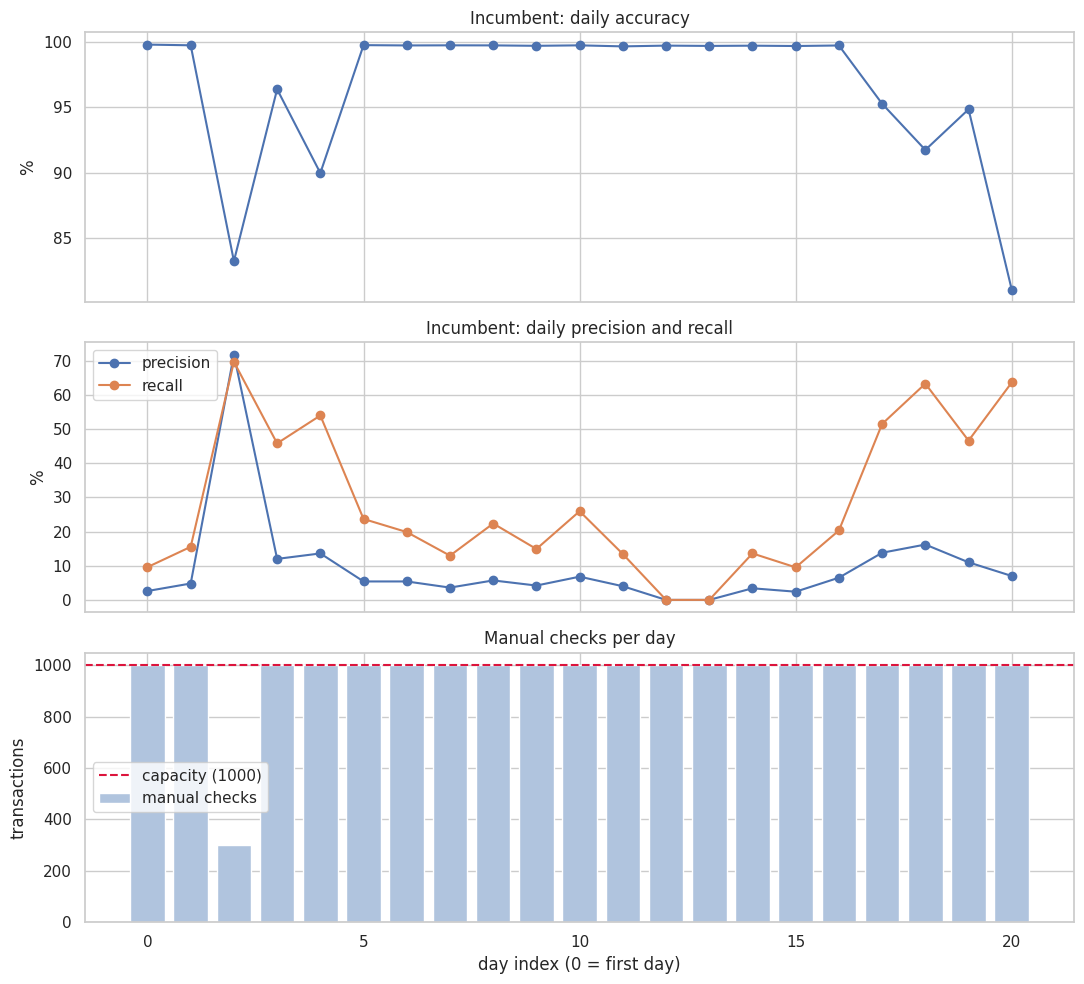

In [21]:
"""Incumbent baseline: each day, check the largest transactions >= $200k, at most 1000 per day."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def incumbent_flags(df, threshold=200_000, capacity=1000):
    """1 for the transactions the incumbent would check: rank each day's transactions by amount (largest first),
    stop at `capacity` checks or when the amount drops below `threshold`. Day = (step - 1) // 24."""
    rank = df.groupby((df.step - 1) // 24).amount.rank(method="first", ascending=False)
    return ((df.amount >= threshold) & (rank <= capacity)).astype("int8")


def incumbent_daily_metrics(df, threshold=200_000, capacity=1000):
    """Daily confusion counts, accuracy, precision and recall of the incumbent (needs step, amount, isFraud)."""
    flag, fraud = incumbent_flags(df, threshold, capacity).astype(bool), df.isFraud.astype(bool)
    d = pd.DataFrame({"day": (df.step - 1) // 24, "tp": flag & fraud, "fp": flag & ~fraud,
                      "fn": ~flag & fraud, "tn": ~flag & ~fraud}).groupby("day").sum()
    d["n"], d["frauds"], d["flagged"] = d[["tp", "fp", "fn", "tn"]].sum(axis=1), d.tp + d.fn, d.tp + d.fp
    d["accuracy"], d["precision"], d["recall"] = (d.tp + d.tn) / d.n, d.tp / d.flagged, d.tp / d.frauds
    d["at_capacity"] = d.flagged >= capacity
    return d[["n", "frauds", "flagged", "tp", "fp", "fn", "accuracy", "precision", "recall", "at_capacity"]]


def plot_incumbent(daily, capacity=1000):
    """Daily accuracy, precision/recall and manual-check volume through time."""
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    axes[0].plot(daily.index, daily.accuracy * 100, marker="o")
    axes[0].set(title="Incumbent: daily accuracy", ylabel="%")
    axes[1].plot(daily.index, daily.precision * 100, marker="o", label="precision")
    axes[1].plot(daily.index, daily.recall * 100, marker="o", label="recall")
    axes[1].set(title="Incumbent: daily precision and recall", ylabel="%")
    axes[1].legend()
    axes[2].bar(daily.index, daily.flagged, color="lightsteelblue", label="manual checks")
    axes[2].axhline(capacity, color="crimson", ls="--", label=f"capacity ({capacity})")
    axes[2].set(title="Manual checks per day", xlabel="day index (0 = first day)", ylabel="transactions")
    axes[2].legend()
    plt.tight_layout()
    plt.show()


# Usage on the training set only:
daily = incumbent_daily_metrics(train)
display(daily.round(4)); plot_incumbent(daily)

## Discussion on Tuning Strategy:
Now we are going to start tuning the model. 

There's some decisions being made here to go over: Ideally for all tuning you do a temporal forward-step for each training cycle. Because the recommended frauds are loaded up per days, I would assume that we are retraining each night, implying the best tuning/validation strategy is just that. Unfortunately, that is computationally expensive. In order to save time in development, I am simply choosing a 60/40 temporal split. This ensures we have both regimes in our validation set, although none in our training set (both can't have it unfortunately).

Another thing: precision and recall both have relevance here. But because the average number of fraudes is less than our 1000 alloted daily checks, recall is the more important metric. If this changes, IE we experience growth in either users or fraud rates such that the the number of daily frauds is greater than our allowance of flags, precision would become the most important, and might necessitate some retuning. Happy to discuss this if I am wrong.

## 6) Feature selection:
Ok, now we are going to do something fun that I cooked up on my own for feature selection. We are going to take a random forest with common sense hyperparams (a quicker class of model than the final GBT we will go with) and we are going to simulate many different permutations of possible features, creating a model on the first 60% of the training set (lets call it feature_engineering_subset_df). 

We will output a dataframe where each row represents a simulation, and each of the 64 possible features are a column. The ith/jth value itself will be a binary indicator of whether the column was present or not in that run of the model. We will have two more columns: the precision and recall of that models accuracy on the remainder of the train set. 

Each simulation of possible features will 
- choose the number of features via a beta binomial distribution that assumes 64 chances with a center of 32, and params of  α = β = 2
- then choose that number of features randomly from the overall set of 64
-  train the model on them
- append the appropriate row to the results df

I chose to run this on a random forest because even though we will go with a GBT it is much faster and is a similar class of model. Good features should persist on both as such.

In order to save time, I did a single temporal split: 60/40. I chose this so that both regimes were captured in the 40% validation set, even though its not going to have both regimes in the training set of this exercise. Later we will do roll-forward validation.




### Discussion on leakage in a feature:

While running this on a small number of simulations I found a possible source of leakage. Here is a discussion with Claude:

`One early thing to know: in that test, precision and recall were both close to 1.0 for every subset. A single feature, amt_over_old_orig, already scores about 1.0 precision and 0.98 recall in a depth-3 tree. If most subsets contain a feature like that, they'll all look about equally good, and the simulation won't tell the features apart much. I'll check for that in the 100-run results.`


"Is it safe to say that amt_over_old_orig is a feature with Leakage?

```
No. It isn't leakage, but it is a suspiciously clean signal, so be careful with

Why it isn't leakage
- amt_over_old_orig is (amount + 1) / (oldbalanceOrg + 1).
- It uses only the transaction's own amount and the origin's balance before the  on the label, on other rows, or on anything after scoring time.
- If oldbalanceOrg is genuinely known when you score, the feature is legitimate.

Why it's still suspicious
- I looked at what the tree learned. The ratio equals exactly 1 when amount == oansaction takes the account's balance to the cent.
- That happens in 5,346 train rows, and every one is fraud.
- Those rows cover 97.9% of all frauds, and no legitimate transaction in the dat
- It holds for both TRANSFER and CASH_OUT frauds, with 2,632 and 2,714 respectively.

That is an artifact of how this synthetic dataset generates fraud, which is why I'd call it a shortcut rather than leakage. Real fraudsters wouldn't always empty an account to the exact cent, and a legitimate customer sometimes will. The held-out period or live dataarticularly given the regime change in your data.
```

If single feature "solves" the problem of fraud, it is likely too good to be true. I doubt `oldbalanceOrg` is present as such, as `amount` certainly must be present. That means we need to oldbalanceOrg and all downstream features from the set. Lets do that and rerun the feature selection simulations at scale, not that the small test run has passed.

(Note we saved to a csv previously and now read from it, as the actual training takes over an hour.)

In [22]:
#removing oldbalanceOrg and dependent feats:
FEATURES = [
    # static (25)
    "hour", "dow_shift", "is_transfer", "is_cash_out",
    "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "amt_over_old_orig", "amt_over_new_orig", "amt_over_old_dest", "amt_over_new_dest",
    "new_over_old_orig", "new_over_old_dest", "old_dest_over_old_orig",
    "orig_was_zero", "orig_new_zero", "orig_zeroed",
    "dest_was_zero", "dest_new_zero", "dest_untouched",
    "full_drain", "orig_gap", "dest_gap",
    'isFlaggedFraud',
    # temporal (39)
    "dest_n_all_ever", "dest_n_all_24h", "dest_n_all_6h",
    "dest_n_transfer_ever", "dest_n_transfer_24h", "dest_n_transfer_6h",
    "dest_n_cashout_ever", "dest_n_cashout_24h", "dest_n_cashout_6h",
    "dest_n_cashin_ever", "dest_n_cashin_24h", "dest_n_cashin_6h",
    "dest_n_debit_ever", "dest_n_debit_24h", "dest_n_debit_6h",
    "dest_is_new",
    "dest_mix_cashin_ever", "dest_mix_cashin_24h",
    "dest_mix_cashout_ever", "dest_mix_cashout_24h",
    "dest_mix_transfer_ever", "dest_mix_transfer_24h",
    "dest_mix_debit_ever", "dest_mix_debit_24h",
    "orig_n_all_ever", "orig_n_all_24h",
    "dest_fraud_as_orig_ever", "dest_fraud_as_dest_ever", "dest_fraud_any_ever", "dest_had_fraud_ever",
    "dest_fraud_as_orig_24h", "dest_fraud_as_dest_24h", "dest_fraud_any_24h", "dest_had_fraud_24h",
    "dest_fraud_as_orig_6h", "dest_fraud_as_dest_6h", "dest_fraud_any_6h", "dest_had_fraud_6h",
    "dest_fraud_share_ever",
]

"""Feature selection by random feature subsets: train a random forest on many random subsets of the features."""
import numpy as np
import pandas as pd
from scipy.stats import betabinom
from sklearn.ensemble import RandomForestClassifier


def split_by_step(df, frac=0.6):
    """First `frac` of the rows by step (whole steps only) and the remainder."""
    cum = df.step.value_counts().sort_index().cumsum() / len(df)
    cut = cum[cum >= frac].index[0]
    return df[df.step <= cut], df[df.step > cut]


def simulate_feature_subsets(fit_df, eval_df, features, n_sims=100, alpha=2, beta=2, seed=0, **rf_params):
    """One row per simulation: a 0/1 column per feature (1 = used in that run), plus precision and recall on eval_df.

    Each run draws k ~ BetaBinomial(len(features), alpha, beta) (centered at len(features) / 2, at least 1),
    picks k features at random, fits a random forest on fit_df and predicts eval_df.
    Both frames need `features` and `isFraud`. Override forest settings through rf_params.
    """
    rng = np.random.default_rng(seed)
    n = len(features)
    Xf, yf = fit_df[features].to_numpy(np.float32), fit_df.isFraud.to_numpy()
    Xe, ye = eval_df[features].to_numpy(np.float32), eval_df.isFraud.to_numpy().astype(bool)
    params = dict(n_estimators=40, max_depth=10, min_samples_leaf=50, max_features="sqrt", max_samples=0.15,
                  class_weight="balanced_subsample", n_jobs=-1) | rf_params

    used = np.zeros((n_sims, n), dtype=np.int8)
    precision, recall = np.zeros(n_sims), np.zeros(n_sims)
    for i in range(n_sims):
        k = max(1, int(betabinom.rvs(n, alpha, beta, random_state=rng)))
        idx = np.sort(rng.choice(n, size=k, replace=False))
        forest = RandomForestClassifier(random_state=int(rng.integers(2**31)), **params).fit(Xf[:, idx], yf)
        pred = forest.predict(Xe[:, idx]).astype(bool)
        tp = (pred & ye).sum()
        used[i, idx] = 1
        precision[i], recall[i] = tp / max(pred.sum(), 1), tp / max(ye.sum(), 1)
    return pd.DataFrame(used, columns=features).assign(precision=precision, recall=recall)


# Usage (train set only, already dropped to CASH_OUT / TRANSFER after feature building):
# 64-feature matrix for the train set: static (row-wise) + temporal (account history) features
X = static_features(train).join(temporal_features(train, end_step=train.step.max() + 1))
FEATURES = list(X.columns)                                    # the 64 features
d = X.join(train[["step", "isFraud", "type"]])
d = d[d.type.isin(["CASH_OUT", "TRANSFER"])]                  # drop other types AFTER feature building

feature_engineering_subset_df, holdout_df = split_by_step(d, 0.6)
results = simulate_feature_subsets(feature_engineering_subset_df, holdout_df, FEATURES, n_sims=100)


### Dry run
Here is where we observed the leakage and then tracked it down to oldbalanceOrg in out of the notebook

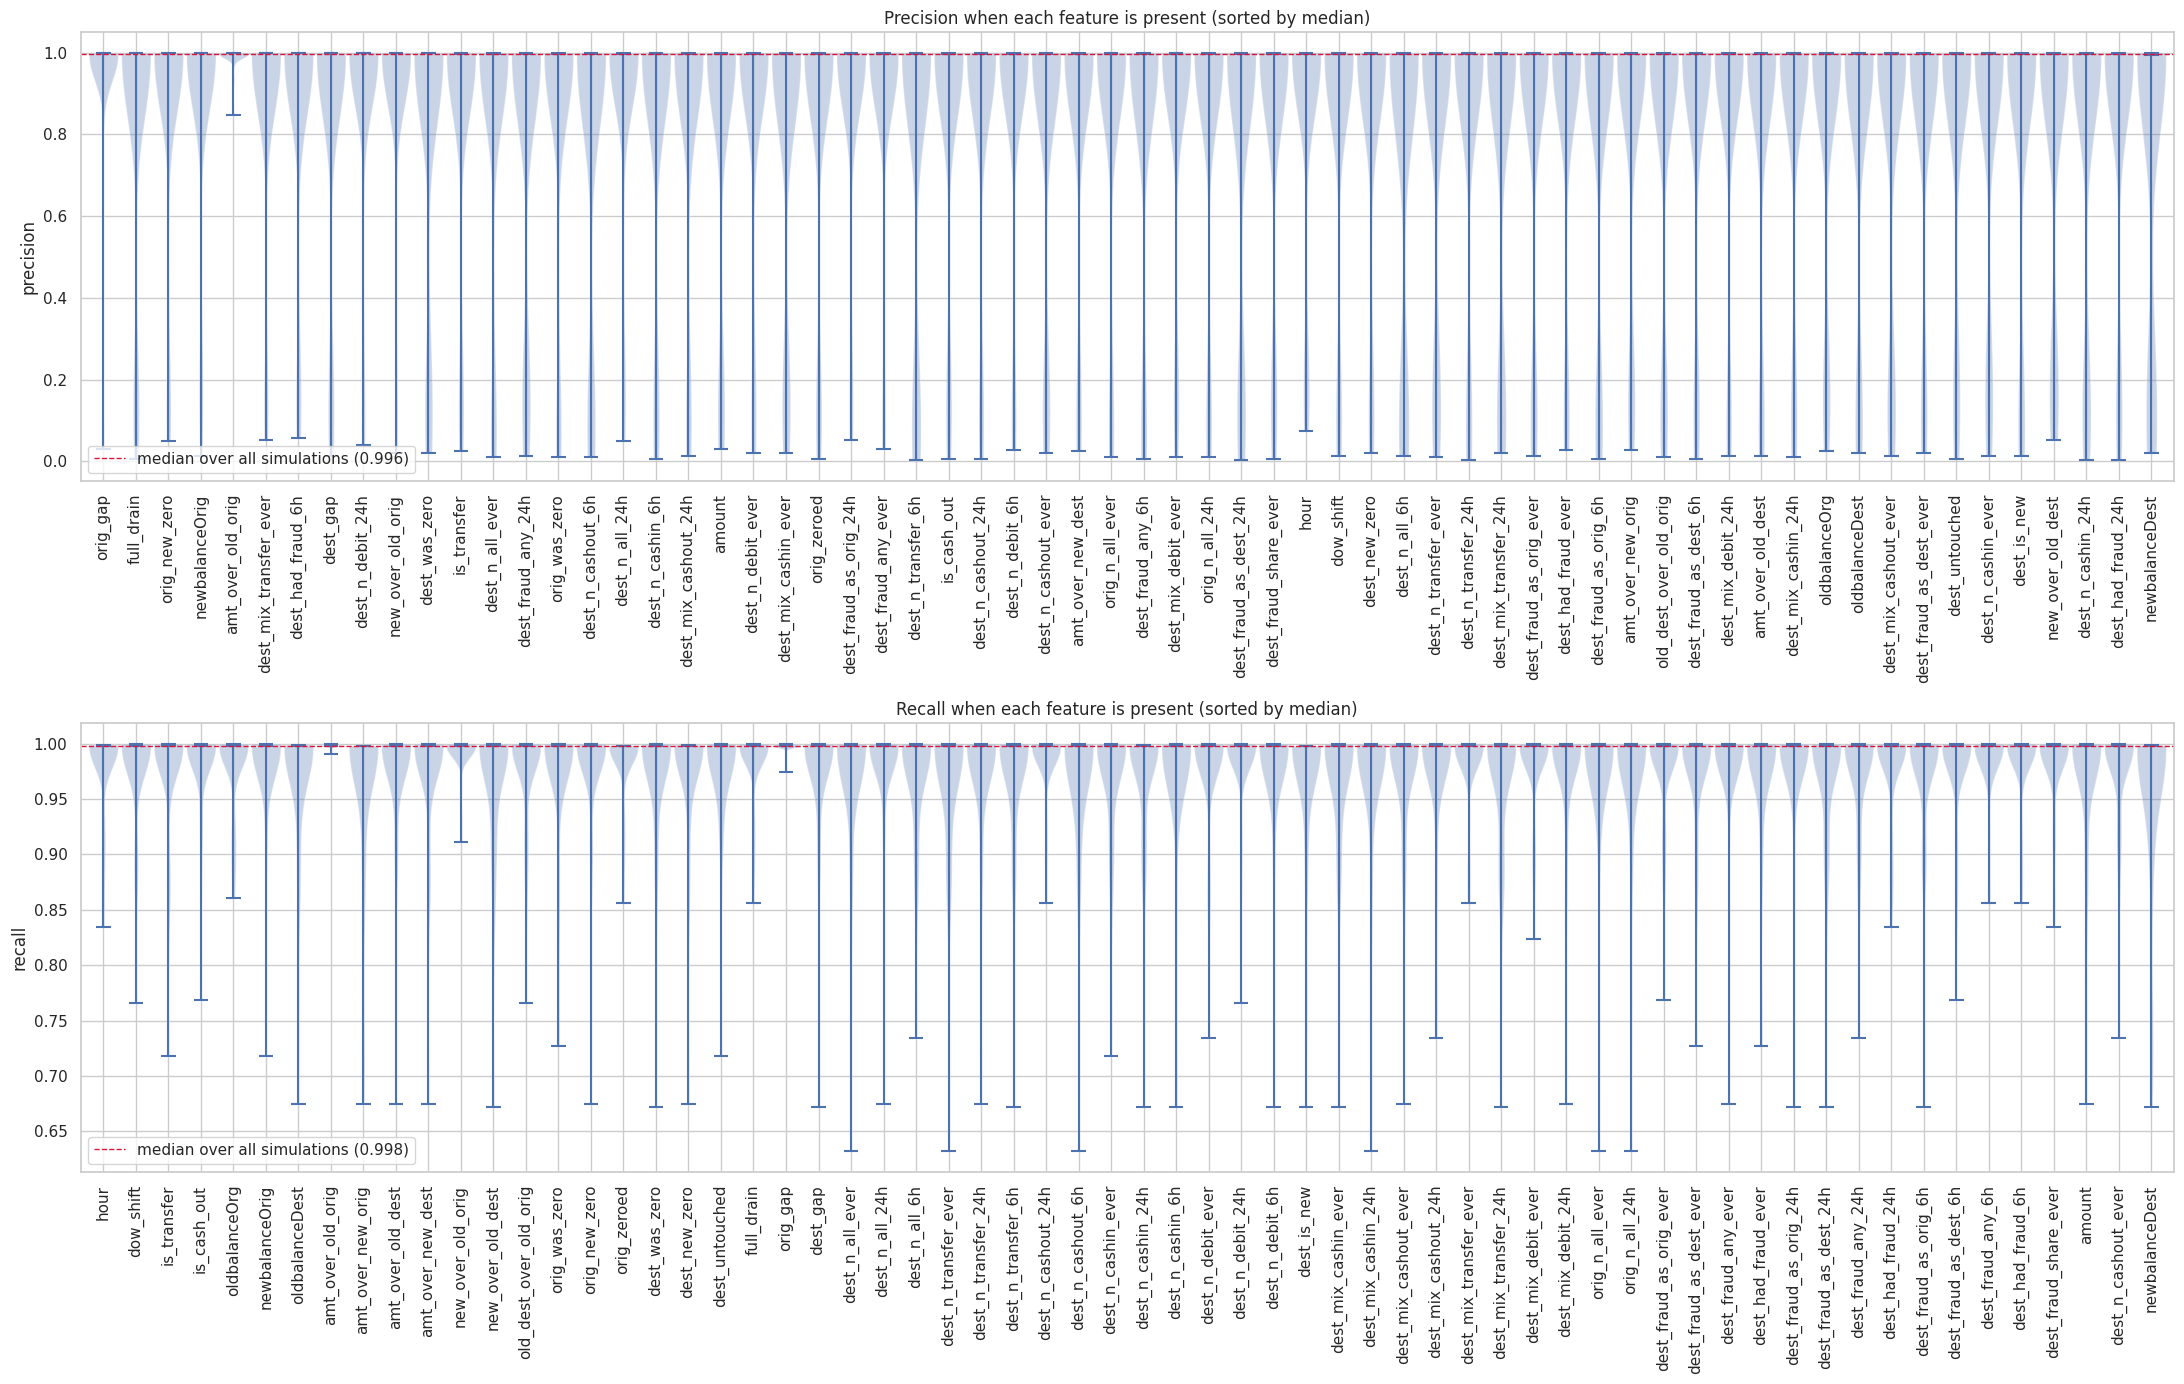

In [23]:

def plot_feature_violins(results, metrics=("precision", "recall"), figsize=(22, 14)):
    """One violin per feature: the distribution of each metric over the simulations that included that feature.

    `results` has one row per simulation, a 0/1 column per feature, plus the metric columns (precision, recall).
    In each panel the features are sorted by that metric's median, highest first, so the two panels can have
    different orders. The dashed line is the metric's median over all simulations.
    """
    features = [c for c in results.columns if c not in ("precision", "recall")]
    fig, axes = plt.subplots(len(metrics), 1, figsize=figsize)
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        med = pd.Series({f: results.loc[results[f] == 1, metric].median() for f in features})
        order = med.sort_values(ascending=False, kind="stable", na_position="last").index
        data = [results.loc[results[f] == 1, metric].to_numpy() for f in order]
        pos = [i for i, v in enumerate(data, start=1) if len(v) >= 2]
        ax.violinplot([data[i - 1] for i in pos], positions=pos, showmedians=True, widths=0.9)
        ax.axhline(results[metric].median(), color="crimson", ls="--", lw=1,
                   label=f"median over all simulations ({results[metric].median():.3f})")
        ax.set(title=f"{metric.capitalize()} when each feature is present (sorted by median)", ylabel=metric)
        ax.set_xticks(range(1, len(order) + 1))
        ax.set_xticklabels(order, rotation=90)
        ax.set_xlim(0.3, len(order) + 0.7)
        ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()

plot_feature_violins(results)

## 6.1 Rerun Sans Leakage

Lets add in isolation features and remove all features that have oldbalanceOrg in their pipeline.

### Discussion of results of full run sans leakage:

Most predictive are hour, type indicators that are direct transforms of another (I should have deleted, my bad), and newbalanceDest. All untransformed from the original dataset. But almost all other features have signal, aside from the very last. dow_shift: the day of the week that I rotated. So lets drop that. yes it does well with recall, but I do prefer precision head to head in this situation.

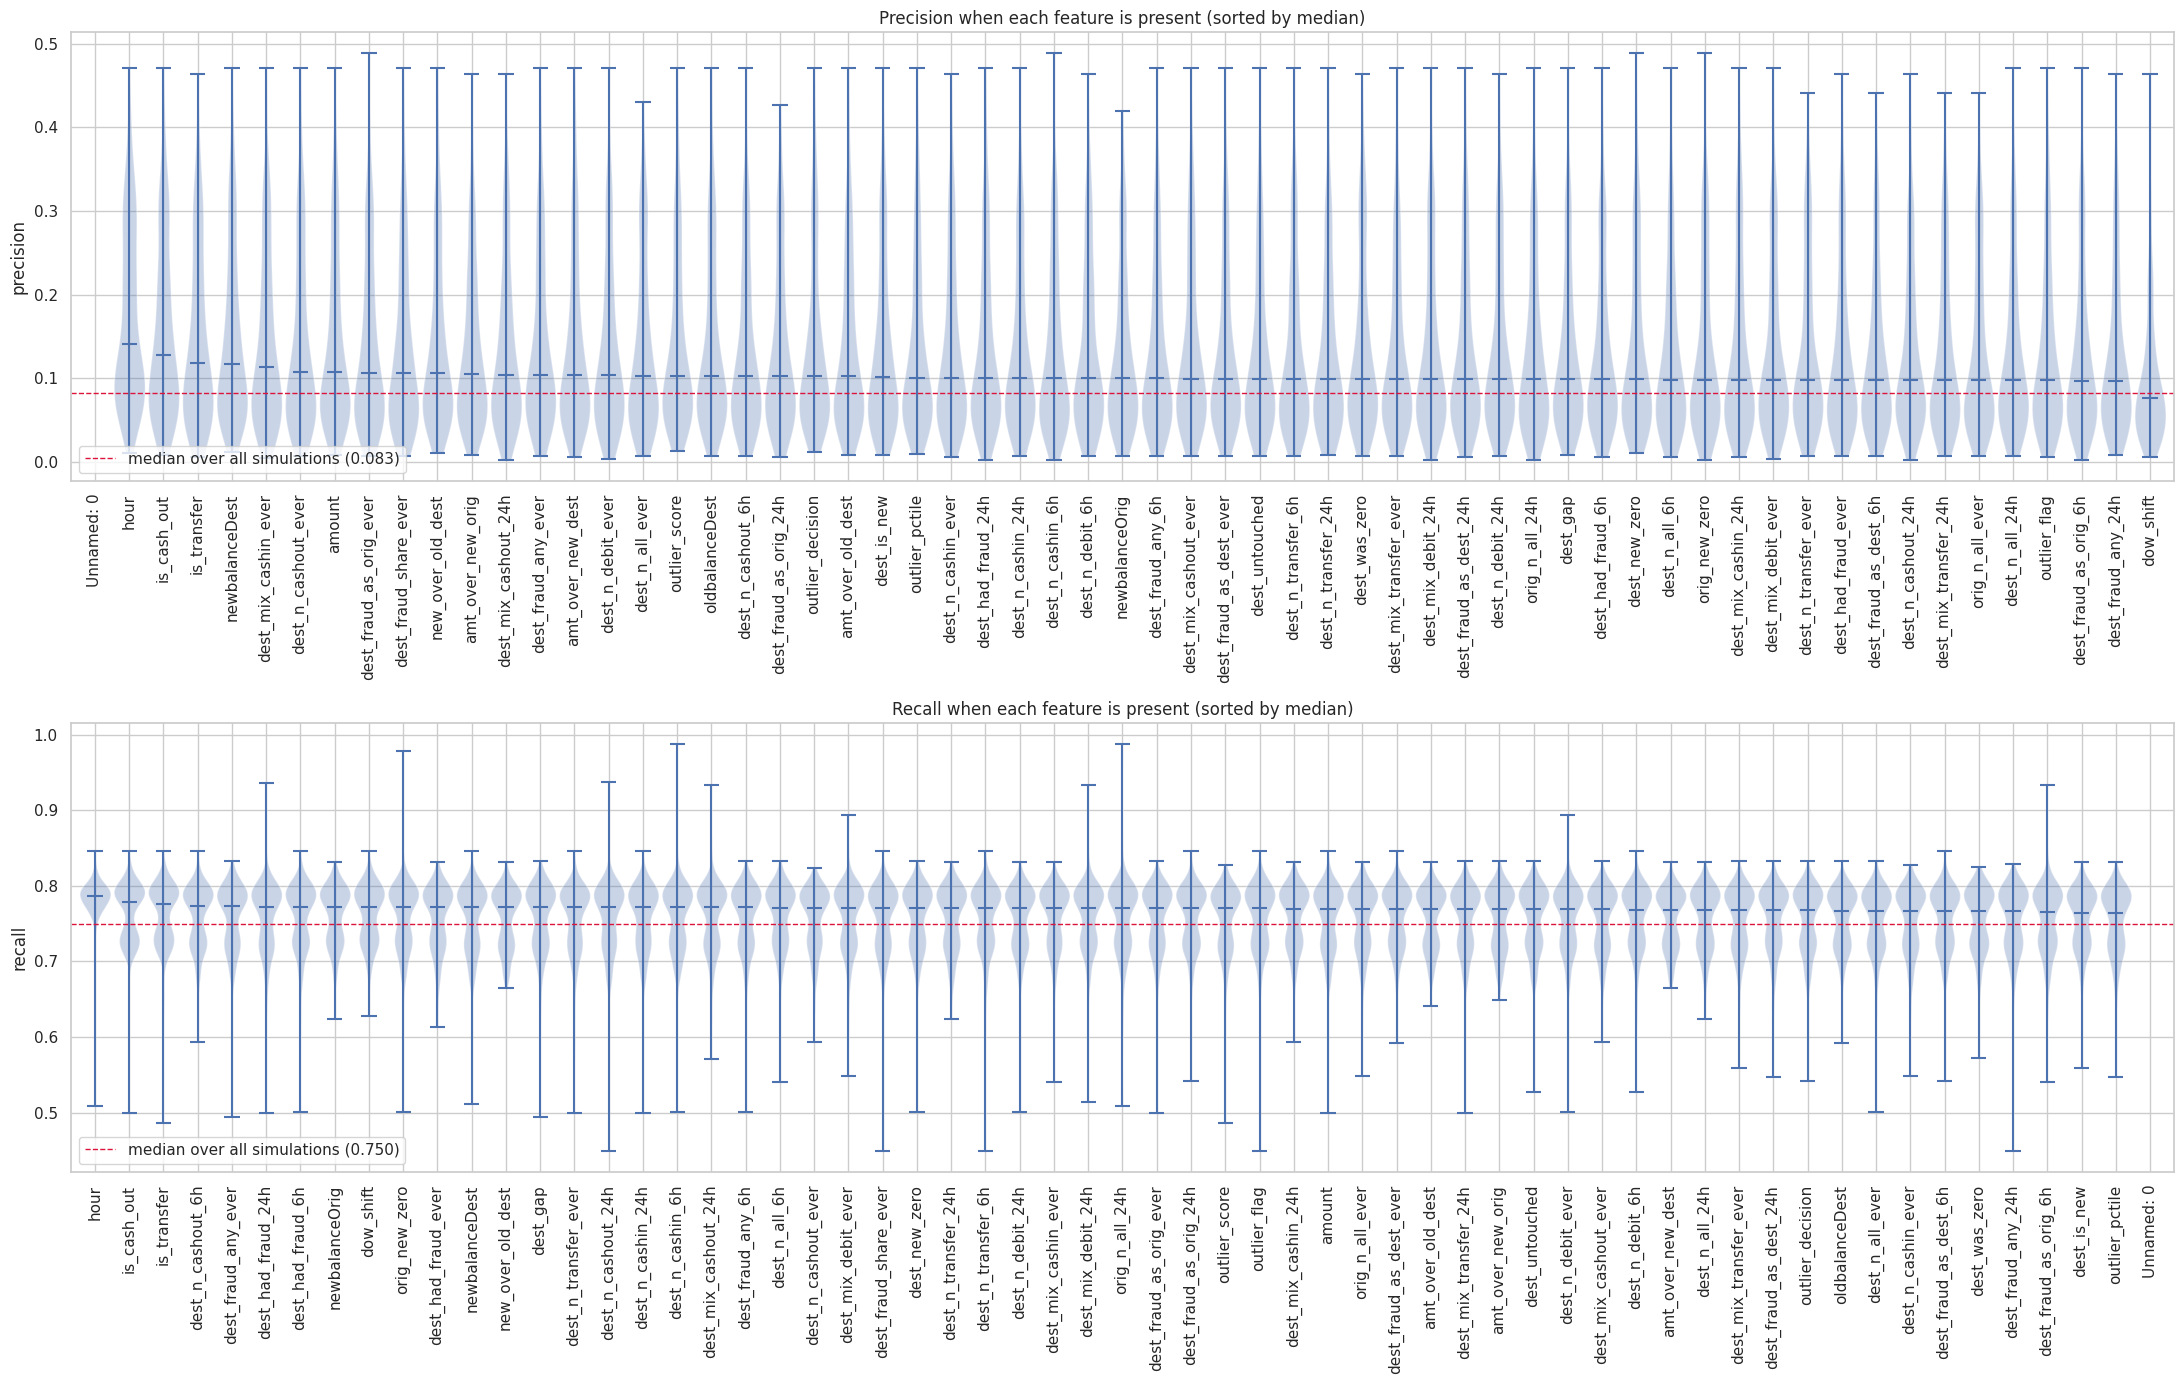

In [24]:

# 64-feature matrix for the train set: static (row-wise) + temporal (account history) features
X = static_features(train).join(temporal_features(train, end_step=train.step.max() + 1))
#features without oldbalanceOrg origin
BASE_FEATURES = [
    # static (17)
    "hour", "dow_shift", "is_transfer", "is_cash_out",
    "amount", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "amt_over_new_orig", "amt_over_old_dest", "amt_over_new_dest", "new_over_old_dest",
    "orig_new_zero", "dest_was_zero", "dest_new_zero", "dest_untouched", "dest_gap",
    # temporal (39)
    "dest_n_all_ever", "dest_n_all_24h", "dest_n_all_6h",
    "dest_n_transfer_ever", "dest_n_transfer_24h", "dest_n_transfer_6h",
    "dest_n_cashout_ever", "dest_n_cashout_24h", "dest_n_cashout_6h",
    "dest_n_cashin_ever", "dest_n_cashin_24h", "dest_n_cashin_6h",
    "dest_n_debit_ever", "dest_n_debit_24h", "dest_n_debit_6h",
    "dest_is_new",
    "dest_mix_cashin_ever", "dest_mix_cashin_24h",
    "dest_mix_cashout_ever", "dest_mix_cashout_24h",
    "dest_mix_transfer_ever", "dest_mix_transfer_24h",
    "dest_mix_debit_ever", "dest_mix_debit_24h",
    "orig_n_all_ever", "orig_n_all_24h",
    "dest_fraud_as_orig_ever", "dest_fraud_as_dest_ever", "dest_fraud_any_ever", "dest_had_fraud_ever",
    "dest_fraud_as_orig_24h", "dest_fraud_as_dest_24h", "dest_fraud_any_24h", "dest_had_fraud_24h",
    "dest_fraud_as_orig_6h", "dest_fraud_as_dest_6h", "dest_fraud_any_6h", "dest_had_fraud_6h",
    "dest_fraud_share_ever",]
    # isolation forest (4), added after the forest is fit on the 56 features above]                                  # the 64 features
d = X.join(train[["step", "isFraud", "type"]])
d = d[d.type.isin(["CASH_OUT", "TRANSFER"])]                  # drop other types AFTER feature building

# split first, then fit the isolation forest on the fit portion only
feature_engineering_subset_df, holdout_df = split_by_step(d, 0.6)

# outlier features: fit on the 60% fit portion (base features only), score both portions with that same model
o_fit, o_hold = outlier_features(feature_engineering_subset_df[BASE_FEATURES],
                                 [feature_engineering_subset_df[BASE_FEATURES], holdout_df[BASE_FEATURES]])
feature_engineering_subset_df = feature_engineering_subset_df.join(o_fit)
holdout_df = holdout_df.join(o_hold)
ALL_FEATURES = BASE_FEATURES + list(o_fit.columns)            # 56 + 4 = 60

# results = simulate_feature_subsets(feature_engineering_subset_df, holdout_df, ALL_FEATURES, n_sims=1000)
# results.to_csv("saved_computationally_big_results.csv")
results = pd.read_csv("saved_computationally_big_results.csv")
plot_feature_violins(results)

### Optimal number of features:

Annoyingly, the more features the more better.

I like to trim out middling features so theres a more condensced set for production, but I don't like doing that at the expense of accuracy.

more verbal discussion on this

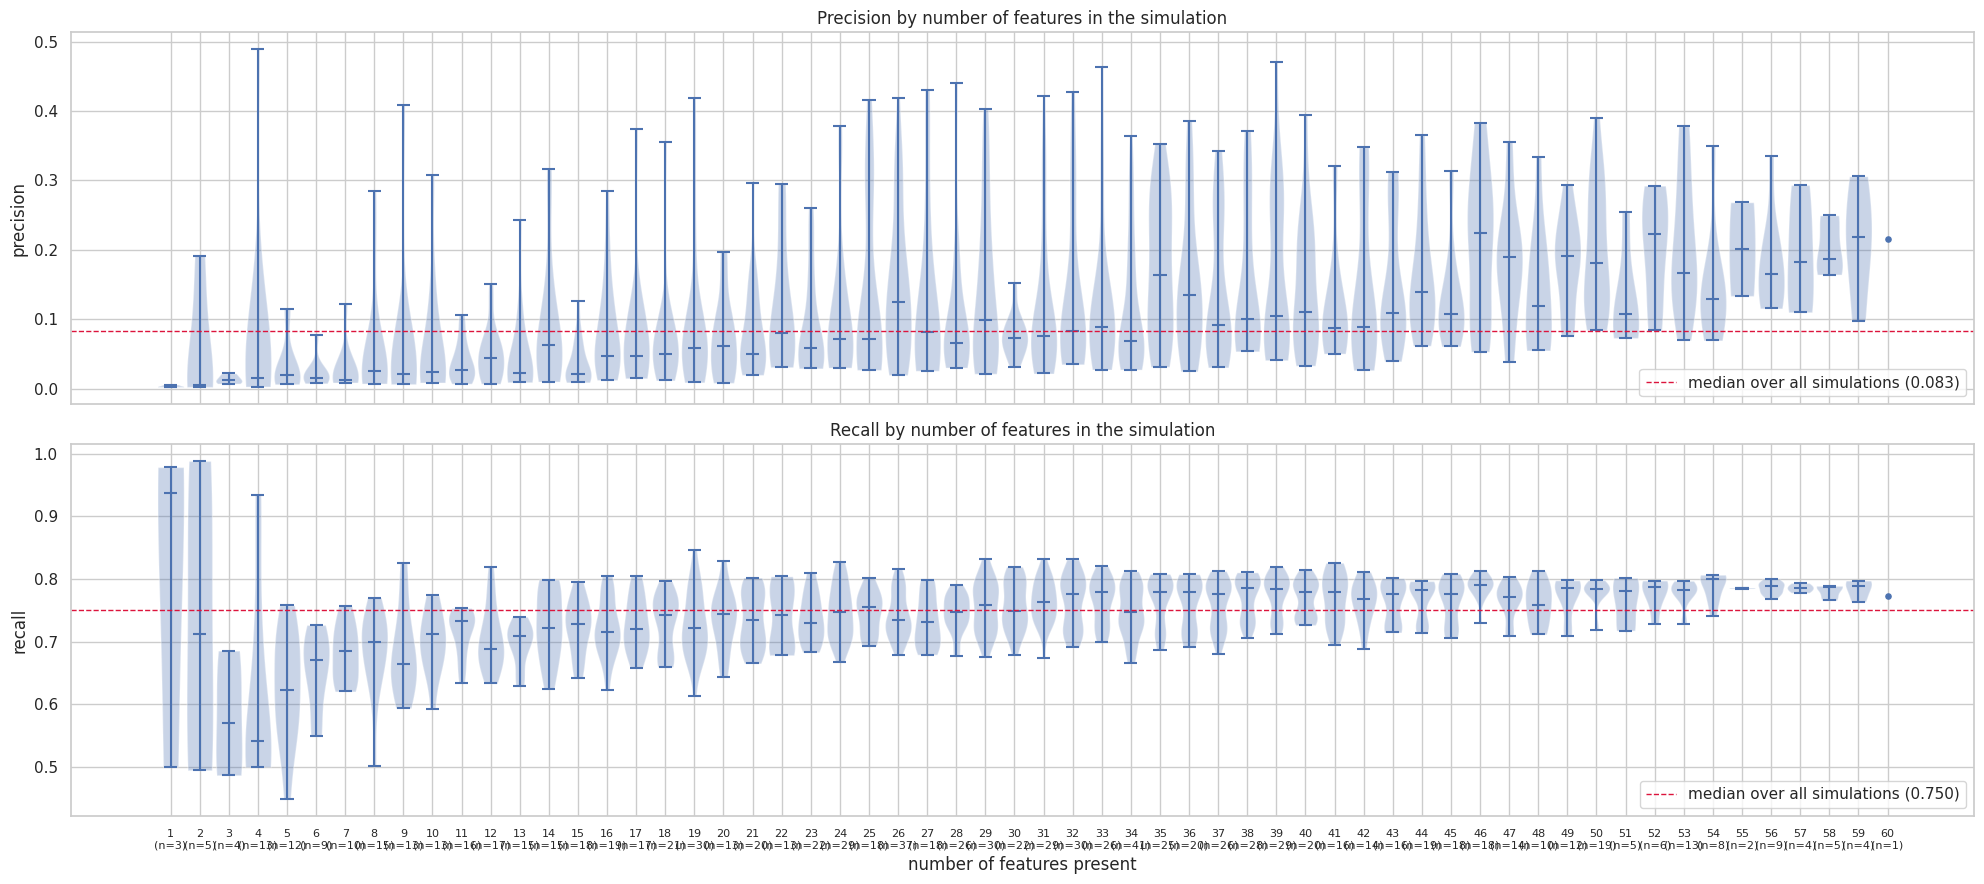

In [25]:

def plot_by_feature_count(results, metrics=("precision", "recall"), figsize=(20, 9)):
    """Violin plots of each metric, one violin per distinct number of features used in a simulation.

    `results` has one row per simulation, a 0/1 column per feature, plus the metric columns (precision, recall).
    The x axis is the number of features present, ascending, with the number of simulations in each group (n).
    Groups with a single simulation are drawn as a point, since a violin needs at least two.
    """
    features = [c for c in results.columns if c not in ("Unnamed: 0", "precision", "recall")]
    count = results[features].sum(axis=1)
    sizes = [int(k) for k in sorted(count.unique())]
    fig, axes = plt.subplots(len(metrics), 1, figsize=figsize, sharex=True)
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        groups = [results.loc[count == k, metric].to_numpy() for k in sizes]
        many = [i for i, g in enumerate(groups, start=1) if len(g) >= 2]
        ax.violinplot([groups[i - 1] for i in many], positions=many, showmedians=True, widths=0.9)
        single = [i for i, g in enumerate(groups, start=1) if len(g) == 1]
        ax.scatter(single, [groups[i - 1][0] for i in single], color="C0", s=14)
        ax.axhline(results[metric].median(), color="crimson", ls="--", lw=1,
                   label=f"median over all simulations ({results[metric].median():.3f})")
        ax.set(title=f"{metric.capitalize()} by number of features in the simulation", ylabel=metric)
        ax.legend(loc="lower right")
    ax.set_xticks(range(1, len(sizes) + 1))
    ax.set_xticklabels([f"{k}\n(n={(count == k).sum()})" for k in sizes], fontsize=8)
    ax.set_xlabel("number of features present")
    plt.tight_layout()
    plt.show()
plot_by_feature_count(results)
# results.columns



In [26]:
#here are our new slected features sans the isolation forest with get added into this list later for reasons
BASE_SELECTED_FEATURES = [
    # static
    "hour", "is_transfer", "is_cash_out",
    "amount", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "amt_over_new_orig", "amt_over_old_dest", "amt_over_new_dest", "new_over_old_dest",
    "orig_new_zero", "dest_was_zero", "dest_new_zero", "dest_untouched", "dest_gap",
    # temporal
    "dest_n_all_ever", "dest_n_all_24h", "dest_n_all_6h",
    "dest_n_transfer_ever", "dest_n_transfer_24h", "dest_n_transfer_6h",
    "dest_n_cashout_ever", "dest_n_cashout_24h", "dest_n_cashout_6h",
    "dest_n_cashin_ever", "dest_n_cashin_24h", "dest_n_cashin_6h",
    "dest_n_debit_ever", "dest_n_debit_24h", "dest_n_debit_6h",
    "dest_is_new",
    "dest_mix_cashin_ever", "dest_mix_cashin_24h",
    "dest_mix_cashout_ever", "dest_mix_cashout_24h",
    "dest_mix_transfer_ever", "dest_mix_transfer_24h",
    "dest_mix_debit_ever", "dest_mix_debit_24h",
    "orig_n_all_ever", "orig_n_all_24h",
    "dest_fraud_as_orig_ever", "dest_fraud_as_dest_ever", "dest_fraud_any_ever", "dest_had_fraud_ever",
    "dest_fraud_as_orig_24h", "dest_fraud_as_dest_24h", "dest_fraud_any_24h", "dest_had_fraud_24h",
    "dest_fraud_as_orig_6h", "dest_fraud_as_dest_6h", "dest_fraud_any_6h", "dest_had_fraud_6h",
    "dest_fraud_share_ever",
]

## 7.0) Model Selection
Machine Learning has had a lot of research attention over the last 30 years. It is rapidly evolving at the frontier, but for a long while the general consensus has been that for mid-sized and up tabular data, without distinct functional forms generating them, some form of gradient boosted tree is typically the optimal model. This can absolutely not always be the case, but in my experience finding a model that beats a well build GBT in datasets like this is a lot of work and even a bit of luck. Neural networks also do well in large datasets, but in tabular scenarios tree-based models still outperform.
As such, the initial base-case model I am choosing is a GBT. 

Of the pen source options, the two most commonly used are LightGBM and XGBoost. Both perform similarly in accuracy, although XGBoost overfits less on small datasets (because it grows by trees instead of by leaves). LightGBM does better with large datasets, as it is much faster. In environments like this with time constraints, a quicker model allows greater breadth of searches. Because our dataset is quite large, I am going with a LightGBM, but keeping an eye out for overfitting.


## 7.1) Choosing the loss function
Before learning the fraud weight, check which LightGBM classification loss function (objective) works best. Each one is fit on the 60% split and scored on the 40% holdout with the same top-1000-per-day labeling. The objective with the highest recall wins (ties broken by PR-AUC).

cross_entropy_lambda is the best loss function by a few tenths of a point, but it errors out computationally lower down. I am going with the classic binary loss. There is less difference here than I expected. Most of my wins tuning losses have been in regression, so maybe a simply binary classification is less consequential.

In [32]:
# Loss-function selection: try every LightGBM classification objective, fit on the 60% split,
# score on the 40% holdout with the same top-1000-per-day rule, and keep the objective with the highest recall.
# Fraud weight is left at 1 (no cost-sensitivity) so the comparison is about the loss itself; the weight is tuned next.
OBJECTIVES = ["binary", "cross_entropy", "cross_entropy_lambda"]    # the objectives that take a 0/1 target
LOSS_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1)
                   
def top_k_per_day(eval_df, proba, capacity=1000):
    """Boolean array: True for the `capacity` highest-probability transactions of each day (day = (step - 1) // 24)."""
    rank = pd.Series(proba, index=eval_df.index).groupby((eval_df.step - 1) // 24).rank(method="first", ascending=False)
    return (rank <= capacity).to_numpy()

def _score_one(objective, Xf, yf, Xe, ye, eval_df, capacity, seed):
    row = {"objective": objective, "precision": np.nan, "recall": np.nan, "pr_auc": np.nan, "error": ""}
    try:
        model = LGBMClassifier(objective=objective, random_state=seed, n_jobs=1, **LOSS_PARAMS).fit(Xf, yf)
        proba = model.predict_proba(Xe)[:, 1]
        flag = top_k_per_day(eval_df, proba, capacity)
        tp = (flag & ye).sum()
        row.update(precision=tp / max(flag.sum(), 1), recall=tp / max(ye.sum(), 1),
                   pr_auc=average_precision_score(ye, proba))
    except Exception as e:                                 # a loss that can't handle this data shouldn't kill the sweep
        row["error"] = f"{type(e).__name__}: {str(e)[:80]}"
    return row


def compare_losses(fit_df, eval_df, features, objectives=OBJECTIVES, capacity=1000, seed=0, n_jobs=-1):
    """One row per objective: precision, recall (top-`capacity`-per-day labeling) and PR-AUC on eval_df.

    Ranked by recall, ties broken by PR-AUC. Objectives that fail to fit are kept at the bottom with their error.
    """
    Xf, yf = fit_df[features].to_numpy(np.float32), fit_df.isFraud.to_numpy()
    Xe, ye = eval_df[features].to_numpy(np.float32), eval_df.isFraud.to_numpy().astype(bool)
    rows = Parallel(n_jobs=n_jobs, backend="threading")(
        delayed(_score_one)(obj, Xf, yf, Xe, ye, eval_df, capacity, seed) for obj in objectives)
    return (pd.DataFrame(rows).sort_values(["recall", "pr_auc"], ascending=False, na_position="last")
            .reset_index(drop=True))


def plot_loss_comparison(res, figsize=(10, 4)):
    ok = res.dropna(subset=["recall"]).iloc[::-1]
    fig, ax = plt.subplots(figsize=figsize)
    colors = ["crimson" if o == ok.objective.iloc[-1] else "lightsteelblue" for o in ok.objective]
    ax.barh(ok.objective, ok.recall, color=colors)
    ax.set(xlabel="recall (top-1000-per-day labeling, 40% holdout)", title="Recall by LightGBM classification loss")
    plt.tight_layout()
    plt.show()


FEATURES = BASE_SELECTED_FEATURES + list(o_fit.columns)
loss_res = compare_losses(feature_engineering_subset_df, holdout_df, FEATURES)
display(loss_res.round(4))

top = loss_res.iloc[0]
print(f"Highest recall: {top.objective} (recall={top.recall:.4f}, precision={top.precision:.4f})")

# The losses are separated by about one caught fraud (noise). `binary` is also the only one that works with the fraud
# weight in the next step (scale_pos_weight is ignored by the cross-entropy losses, which flattens the weight sweep), and
# cross_entropy_lambda's output is not a bounded probability (it can overflow to inf under some settings).
BEST_OBJECTIVE = "binary"


,objective,precision,recall,pr_auc,error
0,cross_entropy_lambda,0.1992,0.8412,0.7868,
1,binary,0.1991,0.8408,0.7866,
2,cross_entropy,0.1991,0.8408,0.7866,


Highest recall: cross_entropy_lambda (recall=0.8412, precision=0.1992)


 ## 8) Sensitivity Learning
Using the same train-test split in our prior feature selection, and with these newly defined BASE_SELECTED_FEATURES + list(o_fit.columns) ,  lets do some cost sensitive learning by weighting the loss associated with misclassifying a fraud higher. We are hyperparameter tuning on the weighting factor. Starting small and going large by trying 90 different weights. We will be using a lightGBM model (what we are going for in production), so starting with that and common sense hyperparameters we will escalate the weights. A few thing to discuss:
  - Now that feature engineering and selection is finished, we can drop all types that have no history of fraud.
  - We will be using a different labeling criteria. Because the audit team can only process 1000 transactions a day, we will be using a probabilistic lightGBM classifying, and we will only label the top 1000 most likely fraud transactions as fraud.


,weight,precision,recall,pr_auc,flagged,tp
0,1.00,0.1991,0.8408,0.7866,10000,1991
1,1.10,0.1992,0.8412,0.7892,10000,1992
2,1.21,0.1990,0.8404,0.7897,10000,1990
3,1.33,0.1990,0.8404,0.7900,10000,1990
4,1.47,0.1993,0.8416,0.7918,10000,1993
...,...,...,...,...,...,...
85,3409.76,0.1146,0.4840,0.0207,10000,1146
86,3752.20,0.1134,0.4789,0.0163,10000,1134
87,4129.02,0.1095,0.4624,0.0114,10000,1095
88,4543.69,0.1053,0.4447,0.0125,10000,1053


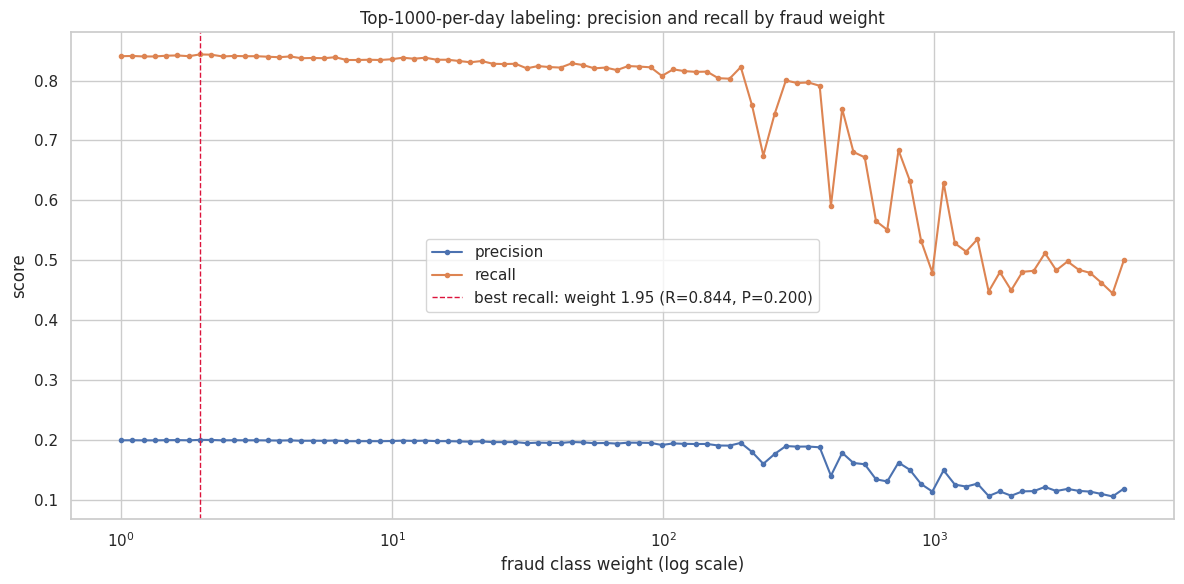

In [33]:


# FEATURES = BASE_SELECTED_FEATURES + list(o_fit.columns)      # + the 4 isolation-forest columns

# 90 weights, geometrically spaced from 1 (no cost-sensitivity) to 5000. The class ratio is ~500:1,
# so "balanced" sits in the middle and the upper half explores heavy over-weighting.
WEIGHTS = np.unique(np.round(np.geomspace(1, 5000, 90), 2))

LGBM_PARAMS = dict(objective=BEST_OBJECTIVE, n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                   n_jobs=1, verbose=-1)


def top_k_per_day(eval_df, proba, capacity=1000):
    """Boolean array: True for the `capacity` highest-probability transactions of each day (day = (step - 1) // 24)."""
    rank = pd.Series(proba, index=eval_df.index).groupby((eval_df.step - 1) // 24).rank(method="first", ascending=False)
    return (rank <= capacity).to_numpy()


def _fit_one(weight, Xf, yf, Xe, ye, eval_df, capacity, seed):
    model = LGBMClassifier(scale_pos_weight=weight, random_state=seed, **LGBM_PARAMS).fit(Xf, yf)
    proba = model.predict_proba(Xe)[:, 1]
    flag = top_k_per_day(eval_df, proba, capacity)
    tp = (flag & ye).sum()
    return {"weight": weight, "precision": tp / max(flag.sum(), 1), "recall": tp / max(ye.sum(), 1),
            "pr_auc": average_precision_score(ye, proba), "flagged": int(flag.sum()), "tp": int(tp)}


def tune_fraud_weight(fit_df, eval_df, features, weights=WEIGHTS, capacity=1000, seed=0, n_jobs=-1):
    """One row per weight: precision, recall (top-`capacity`-per-day labeling) and PR-AUC on eval_df.

    Fits one LightGBM per weight on fit_df (loss weight on fraud rows = `weight`), all in parallel (one thread each).
    Both frames need `features`, `isFraud` and `step`. Precision/recall are pooled over all eval days.
    """
    Xf, yf = fit_df[features].to_numpy(np.float32), fit_df.isFraud.to_numpy()
    Xe, ye = eval_df[features].to_numpy(np.float32), eval_df.isFraud.to_numpy().astype(bool)
    rows = Parallel(n_jobs=n_jobs, backend="threading")(
        delayed(_fit_one)(w, Xf, yf, Xe, ye, eval_df, capacity, seed) for w in weights)
    return pd.DataFrame(rows).sort_values("weight").reset_index(drop=True)


def plot_weight_curve(res, figsize=(12, 6)):
    """Precision and recall (y) against the fraud weight (x, log scale); the best-recall weight is marked."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(res.weight, res.precision, marker="o", ms=3, label="precision")
    ax.plot(res.weight, res.recall, marker="o", ms=3, label="recall")
    best = res.sort_values(["recall", "pr_auc"], ascending=False).iloc[0]     # best recall, ties broken by PR-AUC
    ax.axvline(best.weight, color="crimson", ls="--", lw=1,
               label=f"best recall: weight {best.weight:g} (R={best.recall:.3f}, P={best.precision:.3f})")
    ax.set_xscale("log")
    ax.set(xlabel="fraud class weight (log scale)", ylabel="score",
           title="Top-1000-per-day labeling: precision and recall by fraud weight")
    ax.legend(loc="best")
    plt.tight_layout()
    plt.show()


# Usage (same 60/40 split and outlier columns as the feature selection):
FEATURES = BASE_SELECTED_FEATURES + list(o_fit.columns)
res = tune_fraud_weight(feature_engineering_subset_df, holdout_df, FEATURES)
display(res.round(4)); plot_weight_curve(res)

## 9) Hyperparemeter Tuning

Now lets do some simple hyperparameter tuning. This usually gives a small amount of lift but why not do it?

- n_estimators: 100, 200, 300, 500, 800
- learning_rate: log-uniform 0.01 to 0.2
- num_leaves: 7, 15, 31, 63, 127, 255
- min_child_samples: 20, 50, 100, 200, 500, 1000
- subsample: uniform 0.5 to 1.0
- colsample_bytree: uniform 0.3 to 1.0
- reg_lambda: log-uniform 0.01 to 100
- min_split_gain: 0, 0, 0.01, 0.1, 1.0 (0 is listed twice, so it's drawn 40% of the time)

We are using random search with 96 draws. Could be optimized more.

NOTE: ideally there would be some kind of rolling through time for these tuning and selection steps, but that takes a lot longer to run. I am going to do that step at the end before the final test set roll through.



,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,min_split_gain,precision,recall,pr_auc,is_default
0,800,0.0255,7,50,0.9506,0.5392,0.0903,0.10,0.2010,0.8488,0.7998,False
1,100,0.0903,31,500,0.9660,0.3805,8.2425,0.10,0.2008,0.8480,0.7985,False
2,200,0.0626,63,200,0.6914,0.6960,87.7159,0.10,0.2007,0.8476,0.8025,False
3,300,0.0425,7,50,0.9858,0.9284,69.6081,0.00,0.2006,0.8471,0.8053,False
4,500,0.0182,7,20,0.7561,0.4362,13.1759,0.01,0.2006,0.8471,0.8041,False
5,500,0.0182,255,50,0.5120,0.4144,34.1724,0.01,0.2006,0.8471,0.8031,False
6,800,0.0101,7,1000,0.9954,0.4853,21.0270,0.00,0.2005,0.8467,0.8033,False
7,200,0.0566,7,50,0.9041,0.6422,90.1117,0.00,0.2002,0.8454,0.8046,False
8,300,0.0123,7,50,0.8170,0.6476,0.0451,1.00,0.2002,0.8454,0.8025,False
9,200,0.0320,15,1000,0.8629,0.3614,0.3805,0.00,0.2002,0.8454,0.7991,False


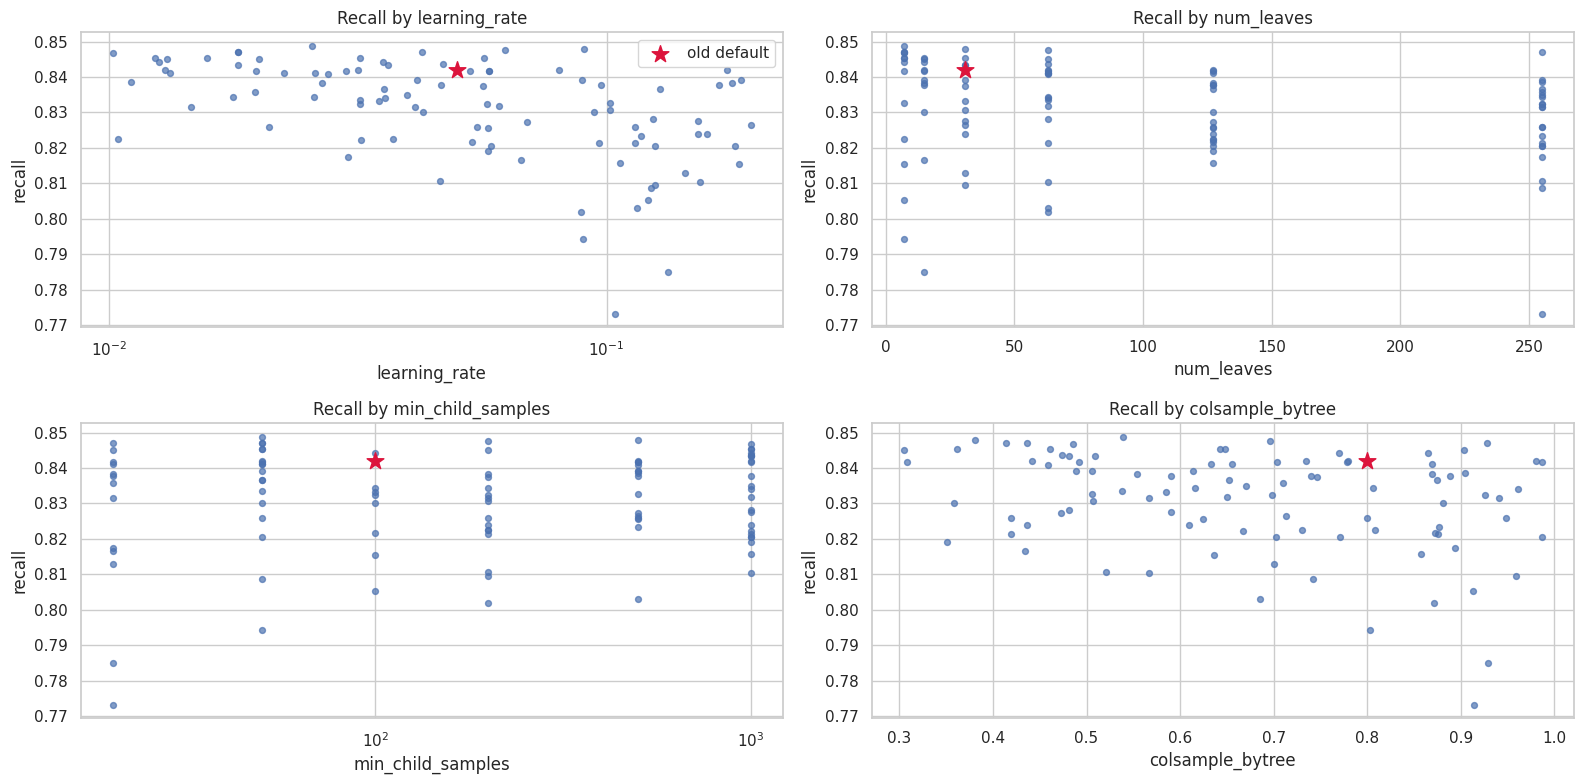

In [34]:
"""Random-search hyperparameter tuning for the LightGBM fraud model (fraud weight fixed, top-k-per-day labeling)."""


BASE_SELECTED_FEATURES = [
    "hour", "is_transfer", "is_cash_out",
    "amount", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "amt_over_new_orig", "amt_over_old_dest", "amt_over_new_dest", "new_over_old_dest",
    "orig_new_zero", "dest_was_zero", "dest_new_zero", "dest_untouched", "dest_gap",
    "dest_n_all_ever", "dest_n_all_24h", "dest_n_all_6h",
    "dest_n_transfer_ever", "dest_n_transfer_24h", "dest_n_transfer_6h",
    "dest_n_cashout_ever", "dest_n_cashout_24h", "dest_n_cashout_6h",
    "dest_n_cashin_ever", "dest_n_cashin_24h", "dest_n_cashin_6h",
    "dest_n_debit_ever", "dest_n_debit_24h", "dest_n_debit_6h",
    "dest_is_new",
    "dest_mix_cashin_ever", "dest_mix_cashin_24h",
    "dest_mix_cashout_ever", "dest_mix_cashout_24h",
    "dest_mix_transfer_ever", "dest_mix_transfer_24h",
    "dest_mix_debit_ever", "dest_mix_debit_24h",
    "orig_n_all_ever", "orig_n_all_24h",
    "dest_fraud_as_orig_ever", "dest_fraud_as_dest_ever", "dest_fraud_any_ever", "dest_had_fraud_ever",
    "dest_fraud_as_orig_24h", "dest_fraud_as_dest_24h", "dest_fraud_any_24h", "dest_had_fraud_24h",
    "dest_fraud_as_orig_6h", "dest_fraud_as_dest_6h", "dest_fraud_any_6h", "dest_had_fraud_6h",
    "dest_fraud_share_ever",
]
# FEATURES = BASE_SELECTED_FEATURES + list(o_fit.columns)      # + the 4 isolation-forest columns

FRAUD_WEIGHT = 1.61   # best weight from the weight sweep


def top_k_per_day(eval_df, proba, capacity=1000):
    """Boolean array: True for the `capacity` highest-probability transactions of each day (day = (step - 1) // 24)."""
    rank = pd.Series(proba, index=eval_df.index).groupby((eval_df.step - 1) // 24).rank(method="first", ascending=False)
    return (rank <= capacity).to_numpy()


def sample_params(n, seed=0):
    """`n` random LightGBM settings. The first row is the previous default, as a baseline to beat."""
    rng = np.random.default_rng(seed)
    default = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                   subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, min_split_gain=0.0)
    rows = [default]
    for _ in range(n - 1):
        rows.append(dict(
            n_estimators=int(rng.choice([100, 200, 300, 500, 800])),
            learning_rate=float(np.exp(rng.uniform(np.log(0.01), np.log(0.2)))),
            num_leaves=int(rng.choice([7, 15, 31, 63, 127, 255])),
            min_child_samples=int(rng.choice([20, 50, 100, 200, 500, 1000])),
            subsample=float(rng.uniform(0.5, 1.0)),
            colsample_bytree=float(rng.uniform(0.3, 1.0)),
            reg_lambda=float(np.exp(rng.uniform(np.log(0.01), np.log(100)))),
            min_split_gain=float(rng.choice([0.0, 0.0, 0.01, 0.1, 1.0])),
        ))
    return pd.DataFrame(rows)


def _fit_one(params, Xf, yf, Xe, ye, eval_df, weight, capacity, seed):
    model = LGBMClassifier(objective=BEST_OBJECTIVE, scale_pos_weight=weight, subsample_freq=1, random_state=seed,
                           n_jobs=1, verbose=-1, **params).fit(Xf, yf)
    proba = model.predict_proba(Xe)[:, 1]
    flag = top_k_per_day(eval_df, proba, capacity)
    tp = (flag & ye).sum()
    return {"precision": tp / max(flag.sum(), 1), "recall": tp / max(ye.sum(), 1),
            "pr_auc": average_precision_score(ye, proba)}


def tune_lightgbm(fit_df, eval_df, features, n_configs=96, weight=FRAUD_WEIGHT, capacity=1000, seed=0, n_jobs=-1):
    """Random search: one row per configuration (its params, precision, recall, PR-AUC), best first.

    All configurations run in parallel (one thread each) on fit_df and are scored on eval_df with the top-`capacity`
    per day rule. Ranked by recall (precision is capped by the 1000/day budget, so it moves with recall),
    ties broken by PR-AUC. Row 0 of the unsorted search is the old default; its `is_default` flag is kept.
    """
    grid = sample_params(n_configs, seed)
    Xf, yf = fit_df[features].to_numpy(np.float32), fit_df.isFraud.to_numpy()
    Xe, ye = eval_df[features].to_numpy(np.float32), eval_df.isFraud.to_numpy().astype(bool)
    scores = Parallel(n_jobs=n_jobs, backend="threading")(
        delayed(_fit_one)(p, Xf, yf, Xe, ye, eval_df, weight, capacity, seed) for p in grid.to_dict("records"))
    res = pd.concat([grid, pd.DataFrame(scores)], axis=1).assign(is_default=lambda r: r.index == 0)
    return res.sort_values(["recall", "pr_auc"], ascending=False).reset_index(drop=True)


PARAM_COLS = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples",
              "subsample", "colsample_bytree", "reg_lambda", "min_split_gain"]


def best_params(res, rank=0, weight=FRAUD_WEIGHT):
    """Settings of the `rank`-th best configuration (0 = best) as a dict that can be fed straight to LightGBM:
    LGBMClassifier(**best_params(res)).fit(X, y). Includes the fraud weight (scale_pos_weight) and subsample_freq."""
    row = res.iloc[rank][PARAM_COLS]
    params = {k: (int(v) if k in ("n_estimators", "num_leaves", "min_child_samples") else float(v))
              for k, v in row.items()}
    return params | {"objective": BEST_OBJECTIVE, "scale_pos_weight": weight, "subsample_freq": 1}


def plot_tuning(res, params=("learning_rate", "num_leaves", "min_child_samples", "colsample_bytree"), figsize=(16, 8)):
    """Recall of each configuration against each hyperparameter (the old default is the red star)."""
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    for ax, p in zip(axes.ravel(), params):
        ax.scatter(res[p], res.recall, s=18, alpha=0.7)
        d = res[res.is_default]
        ax.scatter(d[p], d.recall, color="crimson", marker="*", s=160, label="old default")
        ax.set(xlabel=p, ylabel="recall", title=f"Recall by {p}")
        if p in ("learning_rate", "min_child_samples"):
            ax.set_xscale("log")
    axes[0, 0].legend()
    plt.tight_layout()
    plt.show()


# Usage (same 60/40 split and outlier columns as before):
FEATURES = BASE_SELECTED_FEATURES + list(o_fit.columns)
res = tune_lightgbm(feature_engineering_subset_df, holdout_df, FEATURES)
display(res.head(15).round(4)); plot_tuning(res)
params = best_params(res)
# model = LGBMClassifier(**params, random_state=0, n_jobs=-1, verbose=-1).fit(X_train, y_train)


## 10) Observing walk forward validation
- Now we can get a rough baseline performance to compare against our benchmark. 
- No black box yet

day   7: train   661,943 rows | frauds  278 | caught  219 | precision 0.219 | 129.6s
day   8: train   848,111 rows | frauds  255 | caught  202 | precision 0.202 | 138.9s
day   9: train 1,045,120 rows | frauds  282 | caught  211 | precision 0.211 | 129.3s
day  10: train 1,227,398 rows | frauds  262 | caught  207 | precision 0.207 | 133.1s
day  11: train 1,398,774 rows | frauds  298 | caught  240 | precision 0.240 | 130.8s
day  12: train 1,580,736 rows | frauds  242 | caught  209 | precision 0.209 | 141.1s
day  13: train 1,730,036 rows | frauds  246 | caught  195 | precision 0.195 | 140.1s
day  14: train 1,918,676 rows | frauds  250 | caught  207 | precision 0.207 | 384.3s
day  15: train 2,091,045 rows | frauds  252 | caught  203 | precision 0.203 | 227.1s
day  16: train 2,265,225 rows | frauds  320 | caught  262 | precision 0.262 | 151.6s
day  17: train 2,428,314 rows | frauds  268 | caught  233 | precision 0.233 | 150.1s
day  18: train 2,615,932 rows | frauds  256 | caught  241 | preci

,days,flagged,frauds,caught,precision,recall,accuracy
model,14.0,14000.0,3555.0,2950.0,0.2107,0.8298,0.9935
incumbent,14.0,13932.0,3555.0,858.0,0.0616,0.2414,0.9912


,n,frauds,flagged,tp,fp,fn,accuracy,precision,recall,at_capacity,train_rows,train_frauds,pr_auc,fit_seconds
day,,,,,,,,,,,,,,
7,197042,278,1000,219,781,59,0.9957,0.219,0.7878,True,661943,1646,0.7621,129.6124
8,181649,255,1000,202,798,53,0.9953,0.202,0.7922,True,848111,1914,0.7685,138.8515
9,171830,282,1000,211,789,71,0.9950,0.211,0.7482,True,1045120,2190,0.7329,129.2618
10,182109,262,1000,207,793,55,0.9953,0.207,0.7901,True,1227398,2453,0.7622,133.1202
11,149340,298,1000,240,760,58,0.9945,0.240,0.8054,True,1398774,2737,0.7812,130.7686
12,188657,242,1000,209,791,33,0.9956,0.209,0.8636,True,1580736,2993,0.8372,141.0692
13,172524,246,1000,195,805,51,0.9950,0.195,0.7927,True,1730036,3291,0.7754,140.1415
14,173951,250,1000,207,793,43,0.9952,0.207,0.8280,True,1918676,3531,0.8006,384.3340
15,163144,252,1000,203,797,49,0.9948,0.203,0.8056,True,2091045,3777,0.7791,227.0683


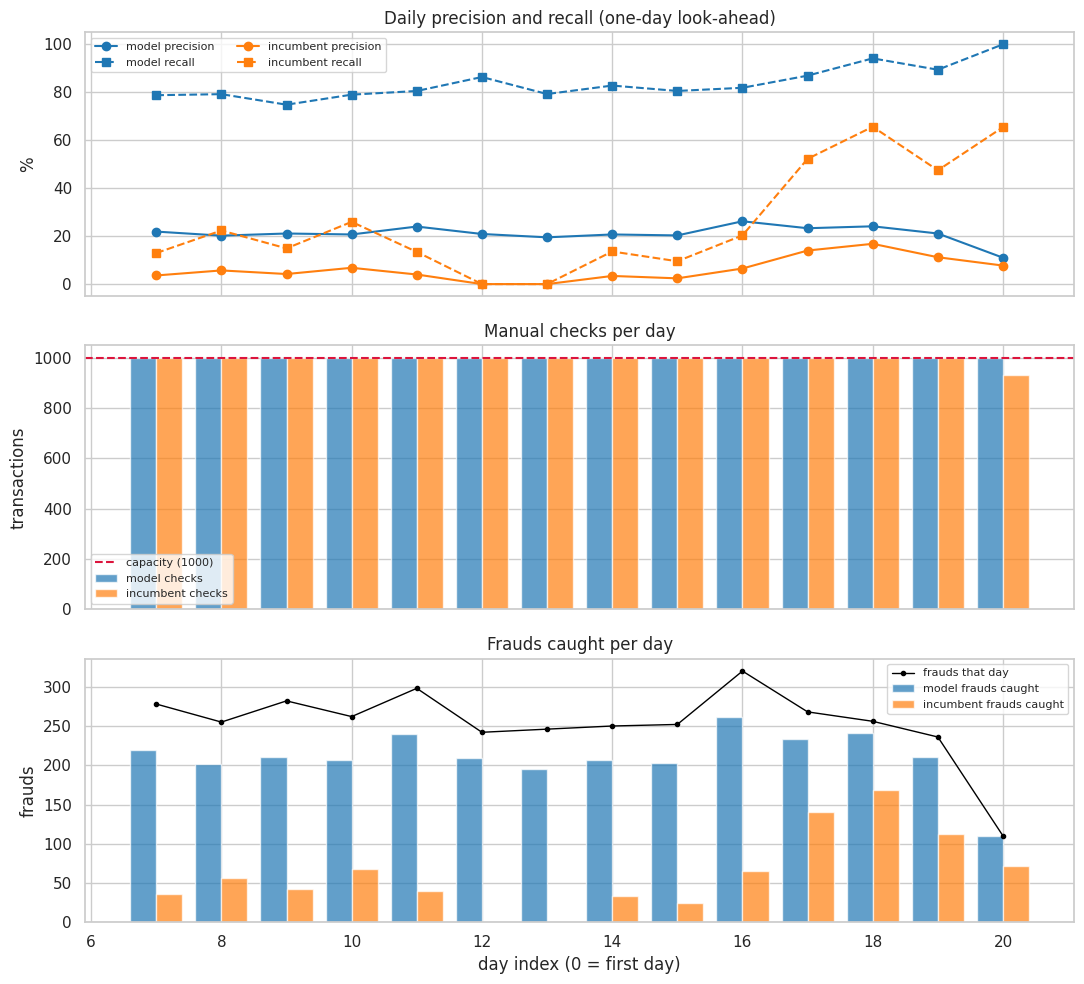

In [35]:
"""One-day look-ahead (walk-forward) validation of the LightGBM fraud model, scored with the top-k-per-day rule.

For each test day starting after the first `warmup_days` days: fit the isolation forest and LightGBM on all earlier
rows, score that one day, flag the `capacity` highest-probability transactions, then step forward a day and repeat
until the last day of the data. Results are compared with the incumbent (largest transactions >= $200k, max 1000/day).
Day = (step - 1) // 24, so day 0 is steps 1-24.
"""
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score

BASE_SELECTED_FEATURES = [
    "hour", "is_transfer", "is_cash_out",
    "amount", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
    "amt_over_new_orig", "amt_over_old_dest", "amt_over_new_dest", "new_over_old_dest",
    "orig_new_zero", "dest_was_zero", "dest_new_zero", "dest_untouched", "dest_gap",
    "dest_n_all_ever", "dest_n_all_24h", "dest_n_all_6h",
    "dest_n_transfer_ever", "dest_n_transfer_24h", "dest_n_transfer_6h",
    "dest_n_cashout_ever", "dest_n_cashout_24h", "dest_n_cashout_6h",
    "dest_n_cashin_ever", "dest_n_cashin_24h", "dest_n_cashin_6h",
    "dest_n_debit_ever", "dest_n_debit_24h", "dest_n_debit_6h",
    "dest_is_new",
    "dest_mix_cashin_ever", "dest_mix_cashin_24h",
    "dest_mix_cashout_ever", "dest_mix_cashout_24h",
    "dest_mix_transfer_ever", "dest_mix_transfer_24h",
    "dest_mix_debit_ever", "dest_mix_debit_24h",
    "orig_n_all_ever", "orig_n_all_24h",
    "dest_fraud_as_orig_ever", "dest_fraud_as_dest_ever", "dest_fraud_any_ever", "dest_had_fraud_ever",
    "dest_fraud_as_orig_24h", "dest_fraud_as_dest_24h", "dest_fraud_any_24h", "dest_had_fraud_24h",
    "dest_fraud_as_orig_6h", "dest_fraud_as_dest_6h", "dest_fraud_any_6h", "dest_had_fraud_6h",
    "dest_fraud_share_ever",
]
OUTLIER_COLS = ["outlier_score", "outlier_decision", "outlier_flag", "outlier_pctile"]

FRAUD_WEIGHT = 1.61   # best weight from the weight sweep
LABEL_LAG = 24        # hours until a fraud label is visible (same meaning as in the notebook)

# fallback settings (the old default). In the notebook pass `best_params(res)` instead: it already includes
# scale_pos_weight and subsample_freq.
DEFAULT_PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                      subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, min_split_gain=0.0,
                      scale_pos_weight=FRAUD_WEIGHT, subsample_freq=1)


# ---------------------------------------------------------------------------------------------------------------
# scoring helpers
# ---------------------------------------------------------------------------------------------------------------
def top_k_per_day(eval_df, proba, capacity=1000):
    """Boolean array: True for the `capacity` highest-probability transactions of each day."""
    rank = pd.Series(proba, index=eval_df.index).groupby((eval_df.step - 1) // 24).rank(method="first", ascending=False)
    return (rank <= capacity).to_numpy()


def outlier_features(X_fit, X_score, n_estimators=200, ref_size=200_000, random_state=0, n_jobs=-1):
    """Fit an IsolationForest on `X_fit`, then score `X_score` (a DataFrame, or a list of them).
    Returns the 4 OUTLIER_COLS (higher = more anomalous); `outlier_pctile` is comparable across daily refits."""
    cols = list(X_fit.columns)
    as_array = lambda X: X[cols].to_numpy(np.float32)
    forest = IsolationForest(n_estimators=n_estimators, random_state=random_state, n_jobs=n_jobs)
    forest.fit(as_array(X_fit))
    ref = np.sort(-forest.score_samples(as_array(X_fit.sample(min(ref_size, len(X_fit)), random_state=random_state))))

    def score(X):
        raw = forest.score_samples(as_array(X))
        return pd.DataFrame({
            "outlier_score": -raw,
            "outlier_decision": raw - forest.offset_,
            "outlier_flag": (raw < forest.offset_).astype("int8"),
            "outlier_pctile": np.searchsorted(ref, -raw, side="right") / len(ref),
        }, index=X.index)

    if isinstance(X_score, pd.DataFrame):
        return score(X_score)
    return [score(X) for X in X_score]


def incumbent_flags(df, threshold=200_000, capacity=1000):
    """1 for the transactions the incumbent would check: each day's largest amounts, stopping at `capacity` checks
    or when the amount drops below `threshold`."""
    rank = df.groupby((df.step - 1) // 24).amount.rank(method="first", ascending=False)
    return ((df.amount >= threshold) & (rank <= capacity)).astype("int8")


def daily_metrics(df, flag, capacity=1000):
    """Daily confusion counts, accuracy, precision and recall for a boolean `flag` aligned with `df`
    (needs step, isFraud). Same columns as the incumbent table from the notebook."""
    flag, fraud = np.asarray(flag, dtype=bool), df.isFraud.to_numpy().astype(bool)
    d = pd.DataFrame({"day": ((df.step - 1) // 24).to_numpy(), "tp": flag & fraud, "fp": flag & ~fraud,
                      "fn": ~flag & fraud, "tn": ~flag & ~fraud}).groupby("day").sum()
    d["n"], d["frauds"], d["flagged"] = d[["tp", "fp", "fn", "tn"]].sum(axis=1), d.tp + d.fn, d.tp + d.fp
    d["accuracy"] = (d.tp + d.tn) / d.n
    d["precision"] = d.tp / d.flagged.replace(0, np.nan)
    d["recall"] = d.tp / d.frauds.replace(0, np.nan)
    d["at_capacity"] = d.flagged >= capacity
    return d[["n", "frauds", "flagged", "tp", "fp", "fn", "accuracy", "precision", "recall", "at_capacity"]]


def incumbent_daily_metrics(df, threshold=200_000, capacity=1000):
    """Daily metrics of the incumbent rule on `df` (needs step, amount, isFraud)."""
    return daily_metrics(df, incumbent_flags(df, threshold, capacity), capacity)


# ---------------------------------------------------------------------------------------------------------------
# walk-forward validation
# ---------------------------------------------------------------------------------------------------------------
def walk_forward(d, base_features=BASE_SELECTED_FEATURES, params=None, warmup_days=7, capacity=1000,
                 label_lag=LABEL_LAG, use_outliers=True, time_decay=True, decay_days=10, decay_weight=0.2, seed=0, n_jobs=-1,
                 verbose=True, start_day=None):
    """One-day look-ahead validation.

    d              static + temporal features for the CASH_OUT / TRANSFER rows only, plus step and isFraud
                   (the temporal features already only see history lagged bxy LAG, so building them once is leak-free).
    params         LightGBM settings, e.g. best_params(res) (must include scale_pos_weight); default DEFAULT_PARAMS.
    warmup_days    days 0..warmup_days-1 are only ever used for training; day `warmup_days` is the first one scored.
    start_day      optional: score only days >= start_day (earlier days still train). Each day's result depends only on
                   earlier rows, so this gives the same numbers as a full run for those days.
    label_lag      hours until a label is visible: a test day starting at step s trains on rows with step <= s - label_lag
                   (24 = the whole previous day is still unlabeled and left out).
    time_decay     True: weight training rows exponentially by recency; False: equal weights.
    decay_days, decay_weight
                   only used when time_decay=True: a row `decay_days` days older than the newest training row gets
                   `decay_weight` of its weight (10 days -> 20%, 20 days -> 4%, ...). Multiplies with scale_pos_weight.
    use_outliers   refit the isolation forest on each day's training rows (base features only) and add its 4 columns.

    Returns (scored, daily):
      scored  one row per scored transaction: day, step, isFraud, amount, proba, flag (model), inc_flag (incumbent)
      daily   one row per test day: daily_metrics for the model + PR-AUC, train size and fit time
    """
    params = DEFAULT_PARAMS if params is None else params
    base_features = list(base_features)
    features = base_features + (OUTLIER_COLS if use_outliers else [])

    d = d.sort_values("step", kind="stable")
    steps = d.step.to_numpy()
    day = (steps - 1) // 24
    pieces, extra = [], []

    for test_day in range(warmup_days if start_day is None else max(warmup_days, start_day), int(day.max()) + 1):
        t0 = time.time()
        start = test_day * 24 + 1
        n_fit = np.searchsorted(steps, start - label_lag, side="right")        # rows with step <= start - label_lag
        lo, hi = np.searchsorted(steps, [start, start + 24], side="left")      # the test day's rows
        if hi == lo or n_fit == 0:
            continue
        fit, test = d.iloc[:n_fit], d.iloc[lo:hi]

        Xf, Xt = fit[base_features], test[base_features]
        if use_outliers:
            o_fit, o_test = outlier_features(Xf, [Xf, Xt], random_state=seed, n_jobs=n_jobs)
            Xf, Xt = Xf.join(o_fit), Xt.join(o_test)

        model = LGBMClassifier(**params, random_state=seed, n_jobs=n_jobs, verbose=-1)
        w = decay_weight ** ((fit.step.max() - fit.step.to_numpy()) / (24 * decay_days)) if time_decay else None
        model.fit(Xf[features].to_numpy(np.float32), fit.isFraud.to_numpy(), sample_weight=w)
        proba = model.predict_proba(Xt[features].to_numpy(np.float32))[:, 1]

        piece = test[["step", "isFraud", "amount"]].copy()
        piece["day"], piece["proba"] = test_day, proba
        piece["flag"] = top_k_per_day(test, proba, capacity)
        piece["inc_flag"] = incumbent_flags(test, capacity=capacity).astype(bool)
        pieces.append(piece)

        y = test.isFraud.to_numpy()
        extra.append({"day": test_day, "train_rows": n_fit, "train_frauds": int(fit.isFraud.sum()),
                      "pr_auc": average_precision_score(y, proba) if y.any() else np.nan,
                      "fit_seconds": time.time() - t0})
        if verbose:
            p = piece
            tp = int((p.flag & (p.isFraud == 1)).sum())
            print(f"day {test_day:>3}: train {n_fit:>9,} rows | frauds {int(y.sum()):>4} | caught {tp:>4} "
                  f"| precision {tp / max(int(p.flag.sum()), 1):.3f} | {time.time() - t0:5.1f}s")

    scored = pd.concat(pieces)
    daily = daily_metrics(scored, scored.flag, capacity).join(pd.DataFrame(extra).set_index("day"))
    return scored, daily


def summarize(daily, label="model"):
    """Pooled precision / recall / accuracy over all scored days."""
    tp, fp, fn = daily.tp.sum(), daily.fp.sum(), daily.fn.sum()
    tn = daily.n.sum() - tp - fp - fn
    return pd.Series({"days": len(daily), "flagged": int(tp + fp), "frauds": int(tp + fn), "caught": int(tp),
                      "precision": tp / max(tp + fp, 1), "recall": tp / max(tp + fn, 1),
                      "accuracy": (tp + tn) / daily.n.sum()}, name=label)


def plot_walk_forward(daily, incumbent, capacity=1000, blackbox_start_step=None):
    """Model vs incumbent through time: precision/recall, manual checks and frauds caught per day.
    `incumbent` is incumbent_daily_metrics(...) on the same rows/days (or scored-day subset).
    If `blackbox_start_step` is given, everything from that step on is shaded as the black box test period."""
    inc = incumbent.reindex(daily.index)
    c_model, c_inc = "tab:blue", "tab:orange"
    fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

    if blackbox_start_step is not None:
        x0 = (blackbox_start_step - 1) / 24          # fractional day index where the black box begins (mid-day is possible)
        x1 = max(daily.index.max(), inc.index.max()) + 0.6
        for i, ax in enumerate(axes):
            ax.axvspan(x0, x1, color="gold", alpha=0.2, zorder=0,
                       label=f"black box test (from step {blackbox_start_step})" if i == 0 else None)
            ax.axvline(x0, color="darkgoldenrod", ls=":", lw=1.2)

    axes[0].plot(daily.index, daily.precision * 100, marker="o", color=c_model, label="model precision")
    axes[0].plot(daily.index, daily.recall * 100, marker="s", color=c_model, ls="--", label="model recall")
    axes[0].plot(inc.index, inc.precision * 100, marker="o", color=c_inc, label="incumbent precision")
    axes[0].plot(inc.index, inc.recall * 100, marker="s", color=c_inc, ls="--", label="incumbent recall")
    axes[0].set(title="Daily precision and recall (one-day look-ahead)", ylabel="%")
    axes[0].legend(ncol=2, fontsize=8)

    w = 0.4
    axes[1].bar(daily.index - w / 2, daily.flagged, w, color=c_model, alpha=0.7, label="model checks")
    axes[1].bar(inc.index + w / 2, inc.flagged, w, color=c_inc, alpha=0.7, label="incumbent checks")
    axes[1].axhline(capacity, color="crimson", ls="--", label=f"capacity ({capacity})")
    axes[1].set(title="Manual checks per day", ylabel="transactions")
    axes[1].legend(fontsize=8)

    axes[2].bar(daily.index - w / 2, daily.tp, w, color=c_model, alpha=0.7, label="model frauds caught")
    axes[2].bar(inc.index + w / 2, inc.tp, w, color=c_inc, alpha=0.7, label="incumbent frauds caught")
    axes[2].plot(daily.index, daily.frauds, color="black", marker=".", lw=1, label="frauds that day")
    axes[2].set(title="Frauds caught per day", xlabel="day index (0 = first day)", ylabel="frauds")
    axes[2].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


# Usage in the notebook (needs static_features, temporal_features, best_params(res) and the o_fit-based features):
X = static_features(train).join(temporal_features(train, end_step=train.step.max() + 1))
d = X.join(train[["step", "isFraud", "type"]])
d = d[d.type.isin(["CASH_OUT", "TRANSFER"])]                      # drop other types AFTER feature building
scored, daily = walk_forward(d, BASE_SELECTED_FEATURES, params=best_params(res), time_decay=False)
inc = incumbent_daily_metrics(d[d.step > 24 * 7])
display(pd.concat([summarize(daily, "model"), summarize(inc, "incumbent")], axis=1).T.round(4))
display(daily.round(4)); plot_walk_forward(daily, inc)

## 11) Comparing this against another totally different algorithm
This is the red-headed stepchild of my analysis. I will talk more about this in person, but the instructions asked for some model comparison. Here is my attempt to cook up a truly different model (not tree permutations that Claude was suggesting which would be very similar).

This problem, and fraud in general, has me thinking of embeddings in vector space. There's wasy to use neural networks for such things, but I usually explore a simpler route first. Algorithms that explicitly assume distance in vector space I like, and Nearest Neighbors is a classic. Unfortunately, we have over 60 featureds and NN breaks down after 5 or so typically. What if use Partial Least Squares to compress these 50 features into a smaller subet with appropriate dimensionality for Nearest neighbors?


I went back and forth on this, doing some research it seems that method isn't the strongest to pair with a GBT, and what was recommended were trees with different loss-functions or weighting strategies. Comparing trees with slightly different weights and loss functions seemed like there would be a lot of quibbling over very small shifts, and repetition of previously shown work above. so I am going with the NN just for some genuinely different results (even if they are a bit worse than expected) for discussions sake.

My prompt to Claude: "I want you to create a Nearest Neighbor  predictor, that takes the selected features, runs Partial least squares on them with respect to the target, and then uses the top N  most variable vectors through a Nearest neighbor classiciation algorithm that outputs probabilities. Please tune the N vectors and the number of neighbors (should choose high numbers due to sparsity of fraud datapoints). Once you have those parameters tuned then run it through the same step forward validation strategy, but don't use the black box test set. outputs plots int he same style as we have done for the incumbent and random forest (no accuracy please). do this all in the holder.py file. feel free to overwrite it. I will then C&P this into a single cell in the notebook, so feel free to use existing functions already declared in the notebook. Any questions before you begin?"

One issue with NN is that it is slow when there's so many features. I am therefor parameter tuning over a small space, and in production/for more tuning I would try a non-sklearn speedup like using approximate neighbors, requiring distinct packages.

n_components= 2 done in  17.9s
n_components= 4 done in  42.3s
n_components= 8 done in  42.0s
n_components=12 done in  40.6s


,n_components,n_neighbors,precision,recall,pr_auc,flagged,tp
0,12,100,0.1165,0.7819,0.6777,2000,233
1,12,250,0.1150,0.7718,0.6686,2000,230
2,12,1000,0.1145,0.7685,0.6502,2000,229
3,12,500,0.1140,0.7651,0.6627,2000,228
4,8,100,0.1120,0.7517,0.6704,2000,224
5,8,500,0.1120,0.7517,0.6567,2000,224
6,4,250,0.1120,0.7517,0.6495,2000,224
7,4,100,0.1115,0.7483,0.6544,2000,223
8,8,250,0.1105,0.7416,0.6604,2000,221
9,8,1000,0.1105,0.7416,0.6436,2000,221


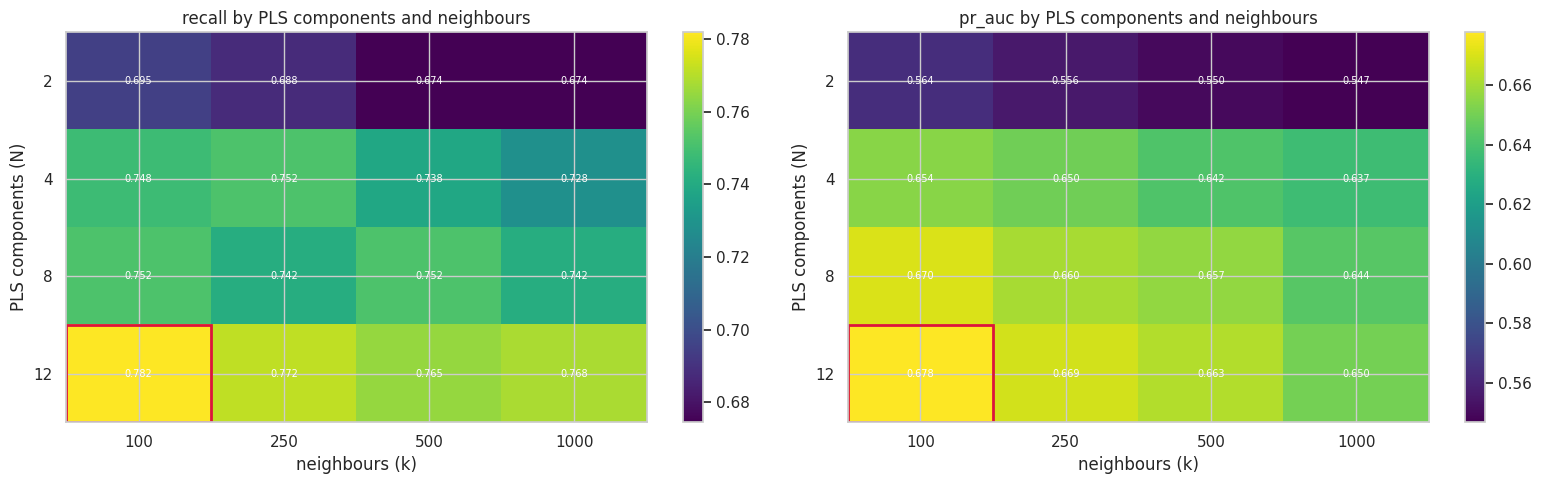

chosen: {'n_components': 12, 'n_neighbors': 100}
day   7: train   661,943 rows | frauds  278 | caught  182 | precision 0.182 |  12.9s
day   8: train   848,111 rows | frauds  255 | caught  173 | precision 0.173 |  12.3s
day   9: train 1,045,120 rows | frauds  282 | caught  176 | precision 0.176 |  11.4s
day  10: train 1,227,398 rows | frauds  262 | caught  186 | precision 0.186 |  11.9s
day  11: train 1,398,774 rows | frauds  298 | caught  212 | precision 0.212 |  10.7s
day  12: train 1,580,736 rows | frauds  242 | caught  184 | precision 0.184 |  13.3s
day  13: train 1,730,036 rows | frauds  246 | caught  174 | precision 0.174 |  11.7s
day  14: train 1,918,676 rows | frauds  250 | caught  184 | precision 0.184 |  12.0s
day  15: train 2,091,045 rows | frauds  252 | caught  192 | precision 0.192 |  11.8s
day  16: train 2,265,225 rows | frauds  320 | caught  242 | precision 0.242 |  12.7s
day  17: train 2,428,314 rows | frauds  268 | caught  231 | precision 0.231 |   2.5s
day  18: train 2

,days,flagged,frauds,caught,precision,recall
pls+knn,14.0,14000.0,3555.0,2692.0,0.1923,0.7572
incumbent,14.0,13932.0,3555.0,858.0,0.0616,0.2414


,n,frauds,flagged,tp,fp,fn,precision,recall,at_capacity,train_rows,train_frauds,pr_auc,fit_seconds
day,,,,,,,,,,,,,
7,197042,278,1000,182,818,96,0.182,0.6547,True,661943,1646,0.5753,12.9480
8,181649,255,1000,173,827,82,0.173,0.6784,True,848111,1914,0.5895,12.2509
9,171830,282,1000,176,824,106,0.176,0.6241,True,1045120,2190,0.5652,11.3916
10,182109,262,1000,186,814,76,0.186,0.7099,True,1227398,2453,0.6018,11.9054
11,149340,298,1000,212,788,86,0.212,0.7114,True,1398774,2737,0.6212,10.7063
12,188657,242,1000,184,816,58,0.184,0.7603,True,1580736,2993,0.6453,13.3202
13,172524,246,1000,174,826,72,0.174,0.7073,True,1730036,3291,0.6141,11.7285
14,173951,250,1000,184,816,66,0.184,0.7360,True,1918676,3531,0.6474,11.9929
15,163144,252,1000,192,808,60,0.192,0.7619,True,2091045,3777,0.6557,11.7904


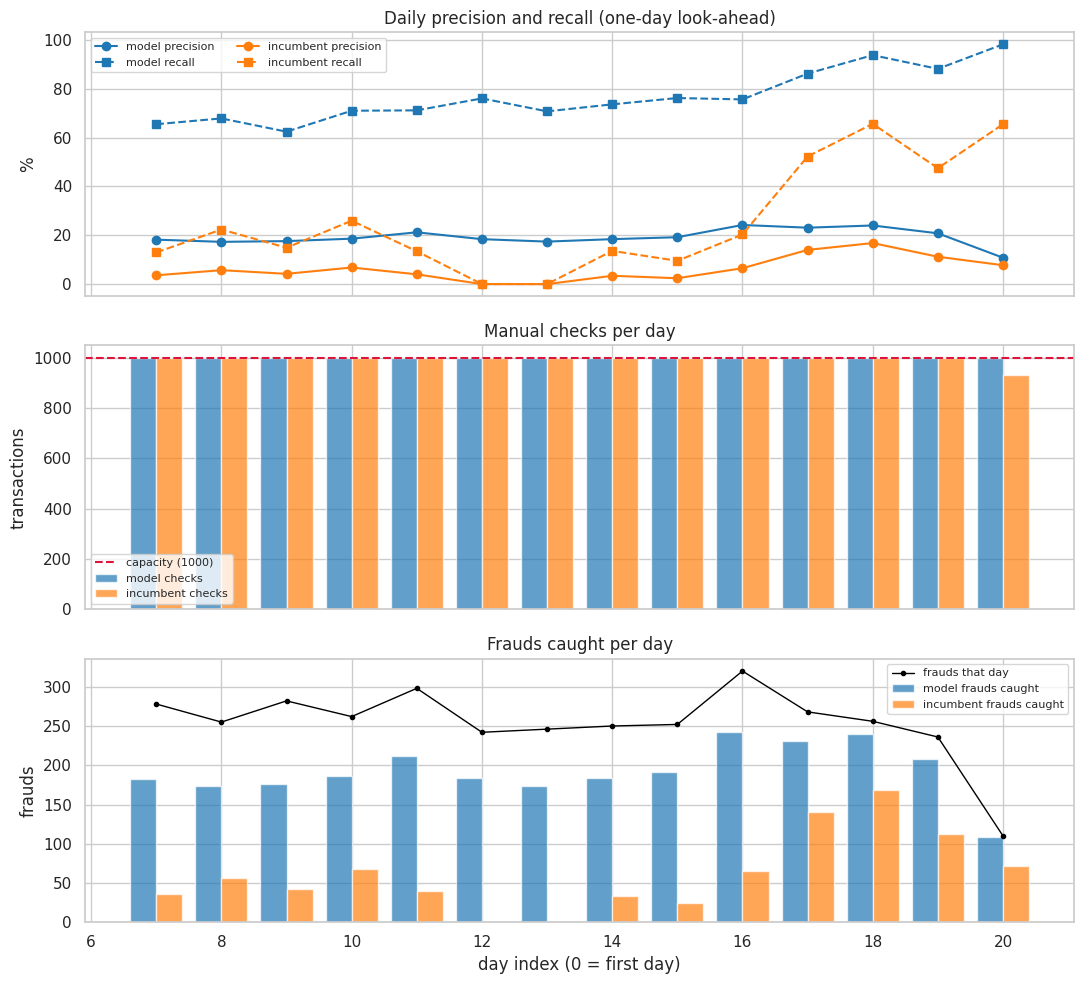

In [36]:
"""PLS + nearest-neighbour fraud model: tuned on the 60/40 split, then validated with the one-day look-ahead
(walk-forward) strategy and the top-k-per-day rule. The black box is NOT touched.

Pipeline (class PLSKNNClassifier):
  1. keep every fraud row and a random sample of `max_legit` legit rows (the kNN index would otherwise hold millions
     of rows; the top-k-per-day ranking is unaffected, but raw probabilities are inflated by the undersampling)
  2. signed log1p of every feature (amounts, balances and counts are heavy tailed), then Partial Least Squares against
     isFraud (PLSRegression standardizes internally); keep the first N components. PLS components come out ordered by
     how much covariance with the fraud label they explain, so "top N" = the first N columns
  3. k-nearest neighbours in that N-dimensional PLS space; probability = share of the k nearest index rows that are fraud

Tuning (tune_pls_knn) is a grid over N (components) and k (neighbours, deliberately large because fraud is sparse).
PLS is fitted once at the largest N (the first N components do not depend on how many are kept), and one neighbour query
at the largest k gives every smaller k for free (the nearest k are a prefix of the nearest kmax).
Ranked like tune_lightgbm: recall at top-`capacity`-per-day, ties broken by PR-AUC.

Needs from the notebook: BASE_SELECTED_FEATURES, LABEL_LAG, feature_engineering_subset_df, holdout_df, and the helpers
top_k_per_day, incumbent_daily_metrics, daily_metrics, summarize, plot_walk_forward.
"""
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import average_precision_score
from sklearn.neighbors import NearestNeighbors

N_GRID = (2, 4, 8, 12)                          # PLS components kept
K_GRID = (100, 250, 500, 1000)                  # neighbours (large: ~0.2% of the rows are fraud)
MAX_LEGIT = 150_000                             # legit rows kept in the kNN index (all frauds are always kept)


# ---------------------------------------------------------------------------------------------------------------
# model
# ---------------------------------------------------------------------------------------------------------------
def _slog(X):
    """Signed log1p, float32: compresses the heavy tails of amounts, balances and counts, keeps 0/1 flags as they are."""
    X = np.asarray(X, dtype=np.float32)
    return np.sign(X) * np.log1p(np.abs(X))


def _sample_index(y, max_legit, rng):
    """Row positions of every fraud plus up to `max_legit` random legit rows (sorted, so row order is kept)."""
    fraud, legit = np.flatnonzero(y), np.flatnonzero(~y)
    keep = rng.choice(legit, size=min(max_legit, len(legit)), replace=False)
    return np.sort(np.concatenate([fraud, keep]))


def _make_nn(n_neighbors, n_dims, n_jobs):
    """Tree search only wins in very low dimension; from ~6 dimensions up, brute force (BLAS) is several times faster."""
    return NearestNeighbors(n_neighbors=n_neighbors, algorithm="kd_tree" if n_dims <= 4 else "brute", n_jobs=n_jobs)


def _fraud_fractions(nn, index_y, Z, ks, chunk=4000):
    """For each row of Z: the share of its k nearest index rows that are fraud, for every k in `ks` (one query).

    `nn` is a fitted NearestNeighbors with n_neighbors >= max(ks). Neighbours come back sorted by distance, so the
    cumulative fraud count along them gives every k at once. Queried in chunks to keep the index matrix small."""
    ks = np.asarray(ks)
    out = np.empty((len(Z), len(ks)), dtype=np.float32)
    for s in range(0, len(Z), chunk):
        idx = nn.kneighbors(Z[s:s + chunk], return_distance=False)
        cum = np.cumsum(index_y[idx], axis=1, dtype=np.int32)
        out[s:s + chunk] = cum[:, ks - 1] / ks
    return out


class PLSKNNClassifier:
    """Signed-log -> PLS (n_components, supervised by the fraud label) -> kNN with predict_proba.

    fit(X, y) takes the feature matrix and a 0/1 label; predict_proba(X) returns (n, 2) like scikit-learn, column 1 =
    share of the `n_neighbors` nearest index rows that are fraud. Because legit rows are undersampled to `max_legit`,
    that share is higher than the true fraud rate (rank with it, don't read it as a calibrated probability)."""

    def __init__(self, n_components=8, n_neighbors=500, max_legit=MAX_LEGIT, random_state=0, n_jobs=-1):
        self.n_components, self.n_neighbors, self.max_legit = n_components, n_neighbors, max_legit
        self.random_state, self.n_jobs = random_state, n_jobs

    def fit(self, X, y):
        y = np.asarray(y).astype(bool)
        keep = _sample_index(y, self.max_legit, np.random.default_rng(self.random_state))
        Xs = _slog(X.iloc[keep].to_numpy() if hasattr(X, "iloc") else np.asarray(X)[keep])   # copy only the kept rows
        self.y_ = y[keep]
        self.pls_ = PLSRegression(n_components=self.n_components, scale=True).fit(Xs, self.y_.astype(np.float32))
        self.index_ = self.pls_.transform(Xs).astype(np.float32)
        self.nn_ = _make_nn(min(self.n_neighbors, len(keep)), self.n_components, self.n_jobs).fit(self.index_)
        return self

    def predict_proba(self, X):
        Z = self.pls_.transform(_slog(X)).astype(np.float32)
        frac = _fraud_fractions(self.nn_, self.y_, Z, [self.nn_.n_neighbors])[:, 0]
        return np.column_stack([1 - frac, frac])


# ---------------------------------------------------------------------------------------------------------------
# tuning
# ---------------------------------------------------------------------------------------------------------------
def tune_pls_knn(fit_df, eval_df, features, n_grid=N_GRID, k_grid=K_GRID, capacity=1000, max_legit=MAX_LEGIT,
                 tune_days=2, seed=0, n_jobs=-1):
    """Grid search: one row per (n_components, n_neighbors) with precision, recall (top-`capacity`-per-day labeling,
    pooled over the scored days) and PR-AUC, best first (recall, then PR-AUC).

    fit_df supplies the index (all frauds + `max_legit` random legit rows). To keep the search affordable, eval_df is
    cut to `tune_days` evenly spaced whole days (None = every day); k is capped at the index size. Expect roughly
    1 minute per N value on 2 days of real data (the neighbour search dominates), so ~4-5 minutes in all.
    Both frames need `features`, `isFraud` and `step`."""
    rng = np.random.default_rng(seed)
    yf_all = fit_df.isFraud.to_numpy().astype(bool)
    keep = _sample_index(yf_all, max_legit, rng)
    Xf, yf = _slog(fit_df[features].to_numpy()[keep]), yf_all[keep]

    day = ((eval_df.step - 1) // 24).to_numpy()
    days = np.unique(day)
    if tune_days is not None and tune_days < len(days):
        days = days[np.unique(np.linspace(0, len(days) - 1, tune_days).round().astype(int))]
    ev = eval_df[np.isin(day, days)]
    Xe, ye = _slog(ev[features].to_numpy()), ev.isFraud.to_numpy().astype(bool)

    n_grid = [n for n in n_grid if n <= len(features)]
    k_grid = sorted(k for k in k_grid if k <= len(yf))
    pls = PLSRegression(n_components=max(n_grid), scale=True).fit(Xf, yf.astype(np.float32))
    Zf_all, Ze_all = pls.transform(Xf).astype(np.float32), pls.transform(Xe).astype(np.float32)

    rows = []
    for n in n_grid:
        t0 = time.time()
        nn = _make_nn(max(k_grid), n, n_jobs).fit(Zf_all[:, :n])
        frac = _fraud_fractions(nn, yf, Ze_all[:, :n], k_grid)
        for j, k in enumerate(k_grid):
            flag = top_k_per_day(ev, frac[:, j], capacity)
            tp = int((flag & ye).sum())
            rows.append({"n_components": n, "n_neighbors": k, "precision": tp / max(int(flag.sum()), 1),
                         "recall": tp / max(int(ye.sum()), 1), "pr_auc": average_precision_score(ye, frac[:, j]),
                         "flagged": int(flag.sum()), "tp": tp})
        print(f"n_components={n:>2} done in {time.time() - t0:5.1f}s")
    return pd.DataFrame(rows).sort_values(["recall", "pr_auc"], ascending=False).reset_index(drop=True)


def best_pls_knn_params(res, rank=0):
    """Settings of the `rank`-th best row (0 = best) as kwargs for PLSKNNClassifier / walk_forward_knn."""
    row = res.iloc[rank]
    return {"n_components": int(row.n_components), "n_neighbors": int(row.n_neighbors)}


def plot_pls_knn_tuning(res, figsize=(16, 5)):
    """Recall and PR-AUC over the (n_components, n_neighbors) grid; the best cell is outlined in red."""
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    best = res.iloc[0]
    for ax, metric in zip(axes, ("recall", "pr_auc")):
        g = res.pivot(index="n_components", columns="n_neighbors", values=metric)
        im = ax.imshow(g.to_numpy(), aspect="auto", cmap="viridis")
        ax.set_xticks(range(g.shape[1]), g.columns)
        ax.set_yticks(range(g.shape[0]), g.index)
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                ax.text(j, i, f"{g.iat[i, j]:.3f}", ha="center", va="center", fontsize=7, color="white")
        bi, bj = list(g.index).index(best.n_components), list(g.columns).index(best.n_neighbors)
        ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, edgecolor="crimson", lw=2))
        ax.set(title=f"{metric} by PLS components and neighbours", xlabel="neighbours (k)", ylabel="PLS components (N)")
        fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------------------------------------------------------
# walk-forward validation (no black box)
# ---------------------------------------------------------------------------------------------------------------
def walk_forward_knn(d, base_features=None, n_components=8, n_neighbors=500, max_legit=MAX_LEGIT, warmup_days=7,
                     capacity=1000, label_lag=None, seed=0, n_jobs=-1, verbose=True):
    """One-day look-ahead validation of PLSKNNClassifier, same protocol as walk_forward for the LightGBM model.

    d              static + temporal features for the CASH_OUT / TRANSFER rows only, plus step and isFraud.
    base_features  defaults to the notebook's BASE_SELECTED_FEATURES (no isolation-forest columns).
    warmup_days    days 0..warmup_days-1 are only ever used for training; day `warmup_days` is the first one scored.
    label_lag      hours until a label is visible (default: the notebook's LABEL_LAG): a test day starting at step s
                   trains on rows with step <= s - label_lag.
    The PLS and the neighbour index are refitted on each day's training rows (every fraud + `max_legit` random legit
    rows; no time decay, since kNN takes no sample weights).

    Returns (scored, daily), shaped like walk_forward's: scored has one row per scored transaction (day, step, isFraud,
    amount, proba, flag, inc_flag); daily has one row per test day (daily_metrics + PR-AUC, train size, fit time)."""
    features = list(BASE_SELECTED_FEATURES if base_features is None else base_features)
    label_lag = LABEL_LAG if label_lag is None else label_lag

    d = d.sort_values("step", kind="stable")
    steps = d.step.to_numpy()
    day = (steps - 1) // 24
    pieces, extra = [], []

    for test_day in range(warmup_days, int(day.max()) + 1):
        t0 = time.time()
        start = test_day * 24 + 1
        n_fit = np.searchsorted(steps, start - label_lag, side="right")        # rows with step <= start - label_lag
        lo, hi = np.searchsorted(steps, [start, start + 24], side="left")      # the test day's rows
        if hi == lo or n_fit == 0:
            continue
        fit, test = d.iloc[:n_fit], d.iloc[lo:hi]

        model = PLSKNNClassifier(n_components, n_neighbors, max_legit, random_state=seed + test_day, n_jobs=n_jobs)
        model.fit(fit[features], fit.isFraud.to_numpy())
        proba = model.predict_proba(test[features].to_numpy())[:, 1]

        piece = test[["step", "isFraud", "amount"]].copy()
        piece["day"], piece["proba"] = test_day, proba
        piece["flag"] = top_k_per_day(test, proba, capacity)
        piece["inc_flag"] = incumbent_flags(test, capacity=capacity).astype(bool)
        pieces.append(piece)

        y = test.isFraud.to_numpy()
        extra.append({"day": test_day, "train_rows": n_fit, "train_frauds": int(fit.isFraud.sum()),
                      "pr_auc": average_precision_score(y, proba) if y.any() else np.nan,
                      "fit_seconds": time.time() - t0})
        if verbose:
            p = piece
            tp = int((p.flag & (p.isFraud == 1)).sum())
            print(f"day {test_day:>3}: train {n_fit:>9,} rows | frauds {int(y.sum()):>4} | caught {tp:>4} "
                  f"| precision {tp / max(int(p.flag.sum()), 1):.3f} | {time.time() - t0:5.1f}s")

    scored = pd.concat(pieces)
    daily = daily_metrics(scored, scored.flag, capacity).join(pd.DataFrame(extra).set_index("day"))
    return scored, daily


# Usage in the notebook (needs static_features, temporal_features and the feature_engineering_subset_df / holdout_df
# 60/40 split used for the other tuning steps; BASE_SELECTED_FEATURES has no isolation-forest columns):
res_knn = tune_pls_knn(feature_engineering_subset_df, holdout_df, BASE_SELECTED_FEATURES)
display(res_knn.head(15).round(4)); plot_pls_knn_tuning(res_knn)
knn_params = best_pls_knn_params(res_knn)
print("chosen:", knn_params)

X = static_features(train).join(temporal_features(train, end_step=train.step.max() + 1))
d = X.join(train[["step", "isFraud", "type"]])
d = d[d.type.isin(["CASH_OUT", "TRANSFER"])]                      # drop other types AFTER feature building
scored_knn, daily_knn = walk_forward_knn(d, BASE_SELECTED_FEATURES, **knn_params)
inc = incumbent_daily_metrics(d[d.step > 24 * 7])
display(pd.concat([summarize(daily_knn, "pls+knn"), summarize(inc, "incumbent")], axis=1).T.drop(columns="accuracy").round(4))
display(daily_knn.drop(columns="accuracy").round(4)); plot_walk_forward(daily_knn, inc)


## Comparing two models:
LGBM is clearly better. I am struggling to find any reason to choose the NN. It may be better in an ensemble?

In [37]:
print("KNN")
display(daily_knn.drop(columns="accuracy").round(4).describe())
print("LGBM")
daily.round(4).describe()

KNN


,n,frauds,flagged,tp,fp,fn,precision,recall,train_rows,train_frauds,pr_auc,fit_seconds
count,14.000000,14.000000,14.0,14.000000,14.000000,14.000000,14.000000,14.000000,1.400000e+01,14.000000,14.000000,14.000000
mean,127891.214286,253.928571,1000.0,192.285714,807.714286,61.642857,0.192286,0.768771,1.790238e+06,3388.214286,0.668521,9.257243
std,81085.345479,47.397605,0.0,34.239942,34.239942,30.573008,0.034240,0.107132,6.823007e+05,1114.869235,0.088634,4.660959
min,2018.000000,110.000000,1000.0,108.000000,758.000000,2.000000,0.108000,0.624100,6.619430e+05,1646.000000,0.565200,1.933800
25%,43441.500000,247.000000,1000.0,177.500000,789.000000,42.250000,0.177500,0.707950,1.270242e+06,2524.000000,0.604875,4.584500
50%,172177.000000,255.500000,1000.0,185.000000,815.000000,69.000000,0.185000,0.746100,1.824356e+06,3411.000000,0.646350,11.759450
75%,181994.000000,275.500000,1000.0,211.000000,822.500000,81.000000,0.211000,0.836900,2.387542e+06,4215.500000,0.730000,12.186400
max,197042.000000,320.000000,1000.0,242.000000,892.000000,106.000000,0.242000,0.981800,2.628123e+06,5123.000000,0.828900,13.320200


LGBM


,n,frauds,flagged,tp,fp,fn,accuracy,precision,recall,train_rows,train_frauds,pr_auc,fit_seconds
count,14.000000,14.000000,14.0,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,1.400000e+01,14.000000,14.000000,14.000000
mean,127891.214286,253.928571,1000.0,210.714286,789.285714,43.214286,0.937750,0.210714,0.838379,1.790238e+06,3388.214286,0.802057,167.012786
std,81085.345479,47.397605,0.0,34.559711,34.559711,19.521895,0.122141,0.034560,0.068686,6.823007e+05,1114.869235,0.047349,67.434200
min,2018.000000,110.000000,1000.0,110.000000,738.000000,0.000000,0.559000,0.110000,0.748200,6.619430e+05,1646.000000,0.732900,129.261800
25%,43441.500000,247.000000,1000.0,204.000000,770.500000,33.500000,0.924075,0.204000,0.792325,1.270242e+06,2524.000000,0.770225,134.553025
50%,172177.000000,255.500000,1000.0,210.000000,790.000000,50.000000,0.995000,0.210000,0.812200,1.824356e+06,3411.000000,0.786800,145.596100
75%,181994.000000,275.500000,1000.0,229.500000,796.000000,57.250000,0.995300,0.229500,0.867950,2.387542e+06,4215.500000,0.830950,159.568525
max,197042.000000,320.000000,1000.0,262.000000,890.000000,71.000000,0.995800,0.262000,1.000000,2.628123e+06,5123.000000,0.900100,384.334000


## 11) Ensemble discussion
### Can we make an ensemble?

This is a good candidate for an ensemble, because the modeling structure and feature engineering is so much different.

But I also don't like ensembles for real-world reasons: 
- they make inference (already challenging) far harder. 
- The added complexity increases possibility of failure. 
- It is also often hard to incorporate desires from less technical staff. IE if a fraud reviewer convinces mgmt to create a ticket to change something about the model (IE "add Seasonality"), the ensemble multiplies the work associated with that change.
- If you build a rigourous best-in-class model the accuracy improvements from adding to an ensemble are rarely massive. Usually it is a measurable but small lift, and at a startup doubling the complexity and effort put into a new model is usually more worth going towards a greenfield project, if the existing model is already a viable product.

A good anecdote about ensembles: the netflixs challenge, one of the first kaggle-like competitions with an astronomical prize, really highlighted the power of them. But netflix never used that ensemble in their ship to production after the prize was awarded, rationalizing that the engineering complexity wasn't worth the marginal gain in accuracy. Instead they took inspiration from simpler, earlier attempts in the competition and built an now-classic matrix factorization approach.

## 12) Walk forward with recency weights for regime changes

One last thing to add to the LGBT:
Due to the regime changes, I think weighting the data by step would be ideal. Lets use an exponential weighting strategy on 'step' as follows: a datapoint 10 days before the most recent datapoint gets 20% of the weight. a datapoint 20 days before the most recent datapoint/step gets 4%, and so forth. If I had time I would tune this but this necessiates a walk forward validation strategy and this notebook takes long enough to run as is.

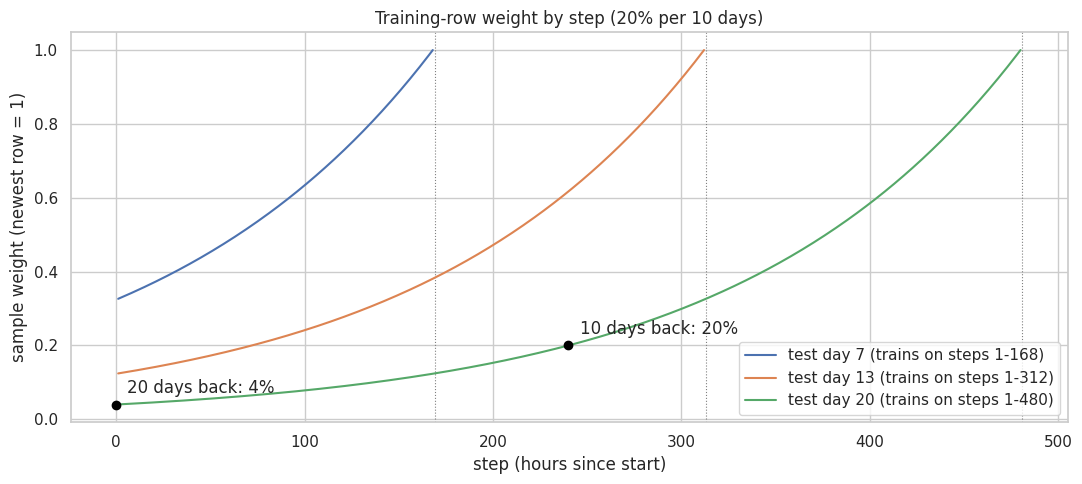

In [38]:
decay_days, decay_weight, label_lag, warmup_days = 10, 0.2, 1, 7
last_day = int((d.step.max() - 1) // 24)
test_days = [warmup_days, (warmup_days + last_day) // 2, last_day]     # first, middle, last scored day

fig, ax = plt.subplots(figsize=(11, 5))
for td in test_days:
    newest = td * 24 + 1 - label_lag                       # newest training step for that test day
    steps = np.arange(1, newest + 1)
    w = decay_weight ** ((newest - steps) / (24 * decay_days))
    ax.plot(steps, w, label=f"test day {td} (trains on steps 1-{newest})")
    ax.axvline(td * 24 + 1, color="gray", ls=":", lw=0.8)  # where that test day starts

# mark the 10 and 20 day points for the last test day
newest = test_days[-1] * 24 + 1 - label_lag
for k in (10, 20):
    ax.scatter(newest - 24 * k, decay_weight ** (k / decay_days), color="black", zorder=3)
    ax.annotate(f"{k} days back: {decay_weight ** (k / decay_days):.0%}",
                (newest - 24 * k, decay_weight ** (k / decay_days)), xytext=(8, 8), textcoords="offset points")

ax.set(title=f"Training-row weight by step ({decay_weight:.0%} per {decay_days} days)",
       xlabel="step (hours since start)", ylabel="sample weight (newest row = 1)")
ax.legend()
plt.tight_layout()
plt.show()

### Compare temporal vs non-temporal weighting:

day   7: train   661,943 rows | frauds  278 | caught  220 | precision 0.220 | 109.5s
day   8: train   848,111 rows | frauds  255 | caught  203 | precision 0.203 | 110.2s
day   9: train 1,045,120 rows | frauds  282 | caught  214 | precision 0.214 | 124.5s
day  10: train 1,227,398 rows | frauds  262 | caught  208 | precision 0.208 | 127.8s
day  11: train 1,398,774 rows | frauds  298 | caught  240 | precision 0.240 | 123.1s
day  12: train 1,580,736 rows | frauds  242 | caught  208 | precision 0.208 | 123.2s
day  13: train 1,730,036 rows | frauds  246 | caught  195 | precision 0.195 | 119.2s
day  14: train 1,918,676 rows | frauds  250 | caught  207 | precision 0.207 | 131.0s
day  15: train 2,091,045 rows | frauds  252 | caught  201 | precision 0.201 | 134.5s
day  16: train 2,265,225 rows | frauds  320 | caught  261 | precision 0.261 | 159.5s
day  17: train 2,428,314 rows | frauds  268 | caught  233 | precision 0.233 | 165.2s
day  18: train 2,615,932 rows | frauds  256 | caught  240 | preci

,days,flagged,frauds,caught,precision,recall,accuracy
model,14.0,14000.0,3555.0,2951.0,0.2108,0.8301,0.9935
incumbent,14.0,13932.0,3555.0,858.0,0.0616,0.2414,0.9912


,n,frauds,flagged,tp,fp,fn,accuracy,precision,recall,at_capacity,train_rows,train_frauds,pr_auc,fit_seconds
day,,,,,,,,,,,,,,
7,197042,278,1000,220,780,58,0.9957,0.220,0.7914,True,661943,1646,0.7629,109.5451
8,181649,255,1000,203,797,52,0.9953,0.203,0.7961,True,848111,1914,0.7561,110.1732
9,171830,282,1000,214,786,68,0.9950,0.214,0.7589,True,1045120,2190,0.7447,124.4754
10,182109,262,1000,208,792,54,0.9954,0.208,0.7939,True,1227398,2453,0.7687,127.8195
11,149340,298,1000,240,760,58,0.9945,0.240,0.8054,True,1398774,2737,0.7804,123.1084
12,188657,242,1000,208,792,34,0.9956,0.208,0.8595,True,1580736,2993,0.8385,123.1613
13,172524,246,1000,195,805,51,0.9950,0.195,0.7927,True,1730036,3291,0.7795,119.1661
14,173951,250,1000,207,793,43,0.9952,0.207,0.8280,True,1918676,3531,0.8064,131.0406
15,163144,252,1000,201,799,51,0.9948,0.201,0.7976,True,2091045,3777,0.7751,134.5244


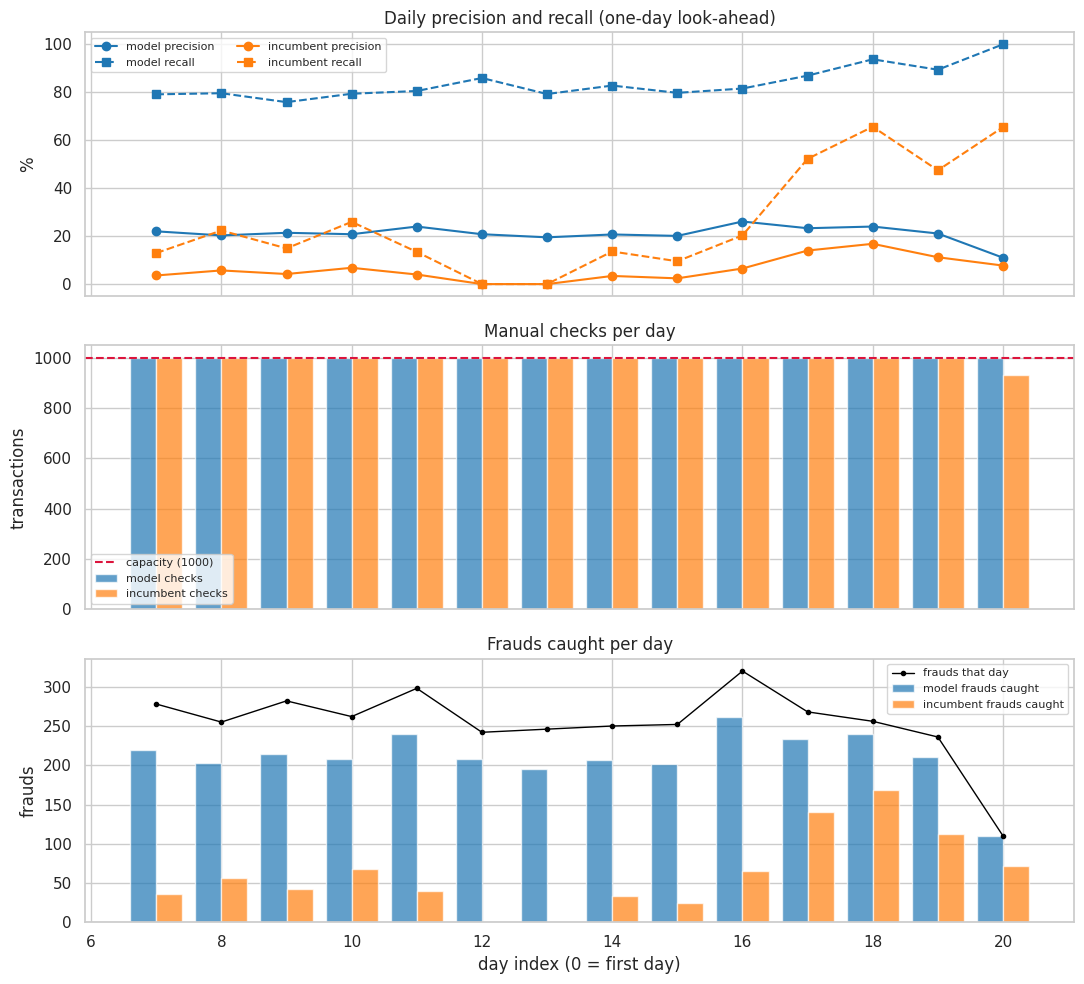

In [39]:
# Usage in the notebook (needs static_features, temporal_features, best_params(res) and the o_fit-based features):
X = static_features(train).join(temporal_features(train, end_step=train.step.max() + 1))
d = X.join(train[["step", "isFraud", "type"]])
d = d[d.type.isin(["CASH_OUT", "TRANSFER"])]                      # drop other types AFTER feature building
scored, daily = walk_forward(d, BASE_SELECTED_FEATURES, params=best_params(res), time_decay=True)
scored_td, daily_td = scored, daily          # kept so the black-box run below can reuse these days
inc = incumbent_daily_metrics(d[d.step > 24 * 7])
display(pd.concat([summarize(daily, "model"), summarize(inc, "incumbent")], axis=1).T.round(4))
display(daily.round(4)); plot_walk_forward(daily, inc)

## 
These accuracies are functionally the same as before but I still want to leave weights in as there are strong regime changes in this dataset, and fraud in general as old strategies get patched and new ones are attempted.

## 14) Blackbox test:

I am seeing a slight strategic overfit between the validation and black box sets, but very minor. In the tenths of a percent. 

day  20: train 2,628,123 rows | frauds  272 | caught  250 | precision 0.250 | 190.7s
day  21: train 2,636,269 rows | frauds  256 | caught  210 | precision 0.210 | 178.0s
day  22: train 2,646,547 rows | frauds  216 | caught  187 | precision 0.187 | 178.4s
day  23: train 2,667,920 rows | frauds  280 | caught  242 | precision 0.242 | 187.6s
day  24: train 2,688,690 rows | frauds  240 | caught  210 | precision 0.210 | 178.5s
day  25: train 2,702,546 rows | frauds  272 | caught  250 | precision 0.250 | 180.3s
day  26: train 2,727,038 rows | frauds  280 | caught  260 | precision 0.260 | 168.9s
day  27: train 2,732,341 rows | frauds  248 | caught  214 | precision 0.214 | 171.0s
day  28: train 2,736,108 rows | frauds  260 | caught  222 | precision 0.222 | 164.7s
day  29: train 2,741,836 rows | frauds  268 | caught  247 | precision 0.247 | 178.4s
day  30: train 2,765,088 rows | frauds  272 | caught  272 | precision 1.000 | 185.5s


,,days,flagged,frauds,caught,precision,recall,accuracy
model,validation (train days),13.0,13000.0,3445.0,2841.0,0.2185,0.8247,0.9940
incumbent,validation (train days),13.0,13000.0,3445.0,786.0,0.0605,0.2282,0.9917
model,mixed day 20 (split at step 491),1.0,1000.0,272.0,250.0,0.2500,0.9191,0.9236
incumbent,mixed day 20 (split at step 491),1.0,1000.0,272.0,120.0,0.1200,0.4412,0.8979
model,black box test,10.0,9272.0,2592.0,2314.0,0.2496,0.8927,0.9417
incumbent,black box test,10.0,9175.0,2592.0,1191.0,0.1298,0.4595,0.9243


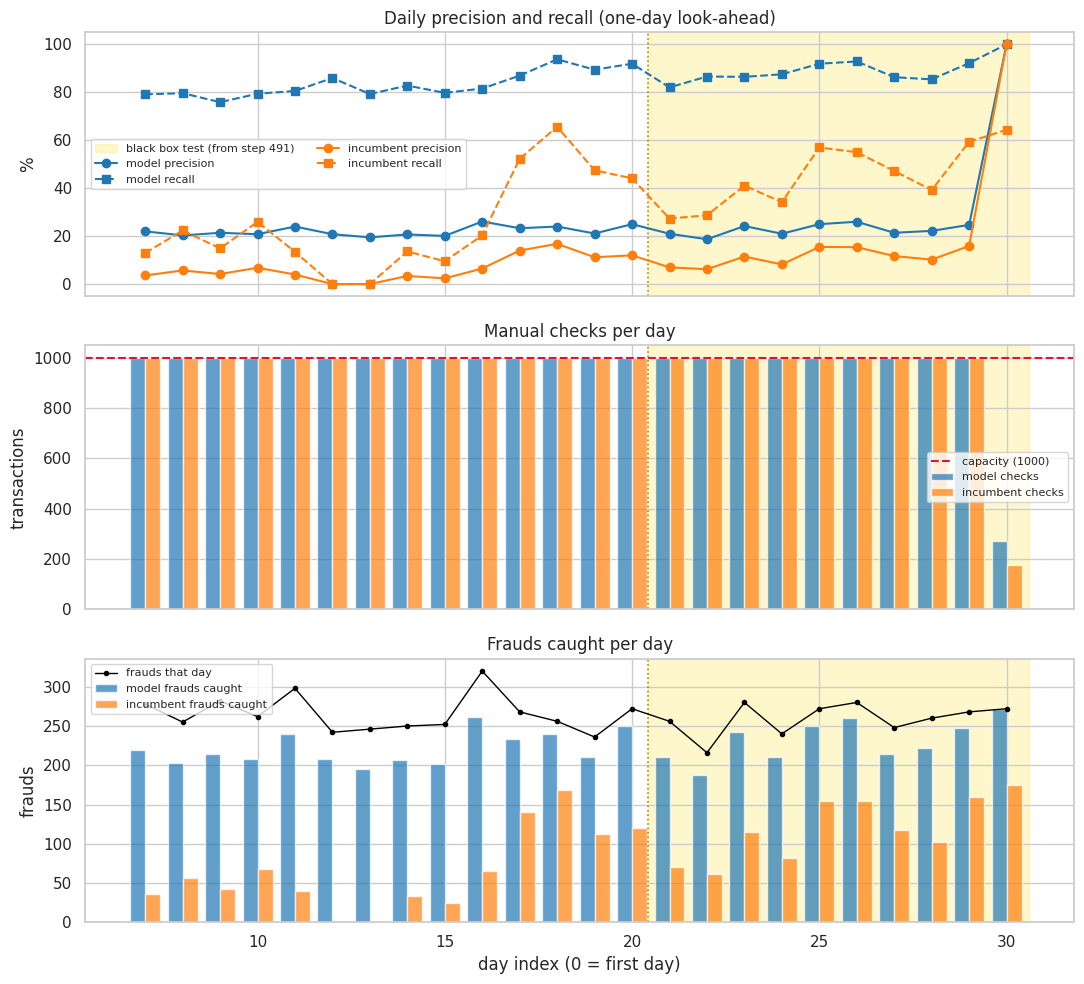

In [40]:
# One-day look-ahead validation over train (validation period) AND the black box (test period), assuming it takes
# LABEL_LAG (= 24) hours for a fraud label to become known. Needs: train, BLACKBOX_PATH, static_features,
# temporal_features, best_params(res) and the walk_forward / plot functions from the cell above.
# Run this once: no tuning or feature changes after looking at the black box result.
raw_cols = ["step", "type", "amount", "nameOrig", "oldbalanceOrg", "newbalanceOrig",
            "nameDest", "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]
blackbox = pd.read_parquet(BLACKBOX_PATH, columns=raw_cols)
BLACKBOX_START_STEP = int(blackbox.step.min())
full = pd.concat([train[raw_cols], blackbox], ignore_index=True)       # train steps, then black box steps
del blackbox

# features for every row, as of the row's own step (history lagged by LAG; fraud labels lagged by LABEL_LAG)
X_all = static_features(full).join(temporal_features(full, end_step=full.step.max() + 1, label_lag=LABEL_LAG))
d_all = X_all.join(full[["step", "isFraud", "type"]])
d_all = d_all[d_all.type.isin(["CASH_OUT", "TRANSFER"])]               # drop other types AFTER feature building
del X_all, full
gc.collect()

# Reuse the time-decay walk-forward already run on train for every day before the black box starts: a day only trains on
# earlier rows, so those days come out identical here. The split day itself is rerun, because the train-only run saw only
# part of it and the full day also contains black box rows.
bb_day = (BLACKBOX_START_STEP - 1) // 24
new_scored, new_daily = walk_forward(d_all, BASE_SELECTED_FEATURES, params=best_params(res),
                                     time_decay=True, label_lag=LABEL_LAG, start_day=bb_day)
scored_all = pd.concat([scored_td[scored_td.day < bb_day], new_scored])
daily_all = pd.concat([daily_td[daily_td.index < bb_day], new_daily])
inc_all = incumbent_daily_metrics(d_all[d_all.step > 24 * 7]).reindex(daily_all.index)

# pooled metrics per period (the black box starts mid-way through bb_day, so that day is reported separately)
bb_day = (BLACKBOX_START_STEP - 1) // 24
periods = {"validation (train days)": daily_all.index < bb_day,
           f"mixed day {bb_day} (split at step {BLACKBOX_START_STEP})": daily_all.index == bb_day,
           "black box test": daily_all.index > bb_day}
rows = {}
for name, mask in periods.items():
    rows[("model", name)] = summarize(daily_all[mask])
    rows[("incumbent", name)] = summarize(inc_all[mask])
display(pd.DataFrame(rows).T.round(4))
plot_walk_forward(daily_all, inc_all, blackbox_start_step=BLACKBOX_START_STEP)


### One undiscussed key KPI for the business?
If the business is liable for every fraud it fails to flag, what is the $ value of the misses? (thinking of the recent Binance hack)

This may be a critical metric to track

,validation (train days),black box test,all scored days
fraud $,5.300684e+09,3.929345e+09,9.619252e+09
model missed $,1.283075e+08,4.675863e+07,1.788321e+08
incumbent missed $,1.831530e+09,3.157088e+08,2.187947e+09
model % of fraud $ caught,9.800000e+01,9.900000e+01,9.800000e+01
incumbent % of fraud $ caught,6.500000e+01,9.200000e+01,7.700000e+01


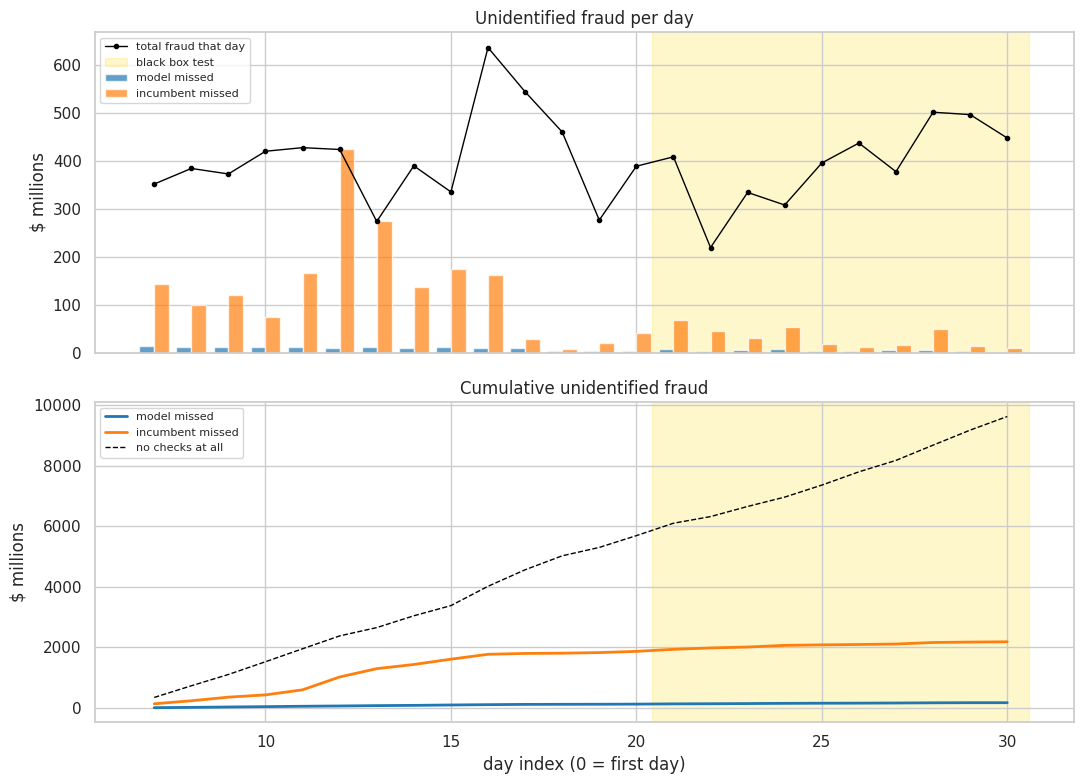

In [41]:
# Dollar liability: if the business eats every fraud it fails to flag, what is the $ value of the misses?
# Works straight off `scored_all` (one row per scored transaction: day, isFraud, amount, flag, inc_flag).
def dollar_losses(scored):
    """Daily fraud $ and unidentified (missed) fraud $ for the model and the incumbent."""
    fraud = scored.isFraud.astype(bool)
    usd = scored.amount.where(fraud, 0.0)                                  # $ of each fraud, 0 for honest rows
    by_day = lambda s: s.groupby(scored.day).sum()
    return pd.DataFrame({"fraud_usd": by_day(usd),
                         "model_missed_usd": by_day(usd.where(~scored.flag.astype(bool), 0.0)),
                         "incumbent_missed_usd": by_day(usd.where(~scored.inc_flag.astype(bool), 0.0))})


def plot_dollar_losses(usd, blackbox_start_step=None):
    """Daily and cumulative unidentified-fraud $; the black line is what you would lose with no checks at all."""
    c_model, c_inc = "tab:blue", "tab:orange"
    fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
    w = 0.4
    axes[0].bar(usd.index - w / 2, usd.model_missed_usd / 1e6, w, color=c_model, alpha=0.7, label="model missed")
    axes[0].bar(usd.index + w / 2, usd.incumbent_missed_usd / 1e6, w, color=c_inc, alpha=0.7, label="incumbent missed")
    axes[0].plot(usd.index, usd.fraud_usd / 1e6, color="black", marker=".", lw=1, label="total fraud that day")
    axes[0].set(title="Unidentified fraud per day", ylabel="$ millions")
    cum = usd.cumsum() / 1e6
    axes[1].plot(cum.index, cum.model_missed_usd, color=c_model, lw=2, label="model missed")
    axes[1].plot(cum.index, cum.incumbent_missed_usd, color=c_inc, lw=2, label="incumbent missed")
    axes[1].plot(cum.index, cum.fraud_usd, color="black", ls="--", lw=1, label="no checks at all")
    axes[1].set(title="Cumulative unidentified fraud", xlabel="day index (0 = first day)", ylabel="$ millions")
    if blackbox_start_step is not None:
        x0 = (blackbox_start_step - 1) / 24
        for i, ax in enumerate(axes):
            ax.axvspan(x0, usd.index.max() + 0.6, color="gold", alpha=0.2, zorder=0,
                       label="black box test" if i == 0 else None)
    for ax in axes:
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


usd_all = dollar_losses(scored_all)
bb_day = (BLACKBOX_START_STEP - 1) // 24
summary = pd.DataFrame({
    name: {"fraud $": u.fraud_usd.sum(), "model missed $": u.model_missed_usd.sum(),
           "incumbent missed $": u.incumbent_missed_usd.sum(),
           "model % of fraud $ caught": 100 * (1 - u.model_missed_usd.sum() / u.fraud_usd.sum()),
           "incumbent % of fraud $ caught": 100 * (1 - u.incumbent_missed_usd.sum() / u.fraud_usd.sum())}
    for name, u in {"validation (train days)": usd_all[usd_all.index < bb_day],
                    "black box test": usd_all[usd_all.index > bb_day],
                    "all scored days": usd_all}.items()})
display(summary.round())
plot_dollar_losses(usd_all, blackbox_start_step=BLACKBOX_START_STEP)

## 15) CONCLUSION: Non-technical Recommendations for FraudOps Lead
#### Proposal:
I am proposing that we replace your current strategy of only investigating transactions above $200k with a model that takes into a variety of data sources into account. This model will output a probability of fraud, and you can investigate them in ranked order: starting from the highest probability and working down. This will mean effortless changes of your team's capacity: if you hire more or less you wont need to change the underlying flag, just how far down you check.
#### KPIs:
Averaging over the last three weeks the current strategy ensures that ~9% of your flagged transactions are fraud. This catches ~33% of frauds in the total daily population. The model we are proposing ensures that ~25% of your flagged transactions are fraud, while ~89% of the total frauds are caught daily. We tested this extensively, but as you know there are distinct regime changes in this business, and we are building out monitoring dashboards and even in rare cases, on-call alerts if anomalies are detected.

If you are tracking total dollars of uncaught fraud as a metric, this new model will reduce that by approximately 10x. This could result in savings approaching a quarter billion dollars in a calendar month.

#### Shipping and Specs once we have your approval:
Given our recent infrastructure deployment efforts, it will take about a week to reach production. Wih your permission we would like to AB test: giving your team a proportion of recommendations from our new model and the rest from your old strategy. Once these results are looking good and everyone is aligned, we could do a full rollout.

Once in production in any capacity, we will be monitoring the daily performance of our model, tracking the statistics shared above with you, regime changes, and if fraud comes in a type that is not "CASH_OUT" or "TRANSFER" the Machine Learning team will immediately convene to understand this new source of fraud. 

#### Open questions:
- Did we accurately assume which features are available at time of scoring? The accuracies suggest no leakage but that doesn't necessarily mean that a feature is present at time of training.
- We want to better understand regime changes from your perspective as an ops manager.
- Is the 24 hour lag for Fraud labeling an accurate assumption?
- Do you care more about actual instances of fraud or total monetary loss of fraud. This could change our weighting in the model.
- Does this actually work in production? Only the AB test will say for sure.
